In [2]:
import pandas as pd
import scanpy as sc
import numpy as np
import anndata as ad
import os
import colorcet as cc
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import harmonypy as hm
import scrublet as scr
import traceback
from collections import Counter
from sklearn.decomposition import PCA
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import re
from matplotlib.patches import Patch
from PIL import Image

# --- ADOBE ILLUSTRATOR COMPATIBILITY ---
# 42 is for TrueType fonts (editable text in Illustrator)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

# --- NOTEBOOK SETTINGS ---
%matplotlib inline

# Define Working Directory
working_dic = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/"
os.chdir(working_dic)

# --- SCANPY SETTINGS ---
sc.settings.verbosity = 1
sc.logging.print_header()

# Professional Plotting Parameters
# sc.set_figure_params( dpi=100,  dpi_save=300,  vector_friendly=True, format='pdf',  transparent=True, facecolor='white' )

# --- CUSTOM COLOR SCHEMES ---
# Your grey-to-blue gradient for feature plots
dimplot_color = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["#E5E5E5", "#4C4DB7"])

COND_ORDER = [
    "Control",
    "Prematurely-terminated",
    "3month-protocol",
    "6month-protocol",
    "PCMV/PRV",
    "Rejection",
]

COND_PALETTE = {
    "Control": "#EFE48E",
    "3month-protocol": "skyblue",
    "6month-protocol": "#08528f",
    "Prematurely-terminated": "#C9B8D9",
    "PCMV/PRV": "#F0C096",
    "Rejection": "#E09E9E",
}


In [2]:
# ============================================================
#  GLOBAL STYLE — run this cell FIRST in every notebook
#  • Font : Arial (fallback: Helvetica → Liberation Sans → DejaVu Sans)
#  • All text, titles, axis labels : bold
#  • PDF/PS : Type-42 (editable text in Illustrator)
# ============================================================
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

mpl.rcParams["font.family"]       = "sans-serif"
mpl.rcParams["font.sans-serif"]   = ["Arial", "Helvetica",
                                      "Liberation Sans", "DejaVu Sans"]
mpl.rcParams["font.weight"]       = "bold"
mpl.rcParams["axes.titleweight"]  = "bold"
mpl.rcParams["axes.labelweight"]  = "bold"
mpl.rcParams["figure.titleweight"]= "bold"
mpl.rcParams["pdf.fonttype"]      = 42
mpl.rcParams["ps.fonttype"]       = 42

sns.set_theme(
    style = "whitegrid",
    font  = "Arial",
    rc    = {
        "font.weight"        : "bold",
        "axes.titleweight"   : "bold",
        "axes.labelweight"   : "bold",
        "figure.titleweight" : "bold",
        "pdf.fonttype"       : 42,
        "ps.fonttype"        : 42,
    }
)

print(f"Font family : {mpl.rcParams['font.sans-serif'][0]}")
print(f"Font weight : {mpl.rcParams['font.weight']}")
print(f"PDF type    : {mpl.rcParams['pdf.fonttype']}")

Font family : Arial
Font weight : bold
PDF type    : 42


# Scrublet

In [5]:

import os
import io
import math
import traceback
import warnings
from concurrent.futures import ProcessPoolExecutor, as_completed

import numpy as np
import pandas as pd
import scanpy as sc
import scrublet as scr
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import anndata
from matplotlib.patches import Patch
from PIL import Image

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

anndata.settings.allow_write_nullable_strings = True

# ── re-apply style (belt-and-suspenders after Agg switch) ───
def _apply_style():
    mpl.rcParams["font.family"]        = "sans-serif"
    mpl.rcParams["font.sans-serif"]    = ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"]
    mpl.rcParams["font.weight"]        = "bold"
    mpl.rcParams["axes.titleweight"]   = "bold"
    mpl.rcParams["axes.labelweight"]   = "bold"
    mpl.rcParams["figure.titleweight"] = "bold"
    mpl.rcParams["pdf.fonttype"]       = 42
    mpl.rcParams["ps.fonttype"]        = 42
    mpl.rcParams["figure.constrained_layout.use"]    = True
    mpl.rcParams["figure.constrained_layout.hspace"] = 0.12
    mpl.rcParams["figure.constrained_layout.wspace"] = 0.12
    mpl.rcParams["savefig.bbox"]       = "tight"
    mpl.rcParams["savefig.pad_inches"] = 0.05
    sns.set_theme(
        style = "whitegrid",
        font  = "Arial",
        rc    = {
            "font.weight"        : "bold",
            "axes.titleweight"   : "bold",
            "axes.labelweight"   : "bold",
            "figure.titleweight" : "bold",
            "pdf.fonttype"       : 42,
            "ps.fonttype"        : 42,
        }
    )

_apply_style()

# ============================================================
#  PATHS
# ============================================================
SOURCE_A_ROOT = (
    "/data/ag_reichart_lindberg/compu_lab/PROJECTS/"
    "20231020_el_Xenotransplant/data/"
    "20240916_LafugaHelmholtz_CB_XENOPIGcustom_V2"
)
SOURCE_B_ROOT = (
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/"
    "xeno/data/new_xeno_data_post_CB_v2"
)
OUT_ROOT = (
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/"
    "xeno/analysis/v1/celltype_annotation/results/scrublet"
)
os.makedirs(OUT_ROOT, exist_ok=True)

# ============================================================
#  PARAMETERS
# ============================================================
DOUBLET_THRESHOLD     = 0.20
EXPECTED_DOUBLET_RATE = 0.05
N_WORKERS             = 64

# ============================================================
#  REMAPPING & EXCLUSIONS
# ============================================================
SAMPLE_ID_REMAP = {
    "23L012212": "PAV71",
}

NON_SAMPLE_FOLDERS = {
    "ind_outs",
    "cb_logs",
    "cellbender_V3_SIF",
}

# ============================================================
#  SAMPLE COLLECTION
# ============================================================
def _collect_samples(root, suffix, id_remap=None):
    if id_remap is None:
        id_remap = {}
    entries = []
    if not os.path.isdir(root):
        print(f"  WARNING: root not found — {root}")
        return entries
    for folder in sorted(os.listdir(root)):
        if folder.startswith(".") or folder in NON_SAMPLE_FOLDERS:
            continue
        subdir = os.path.join(root, folder)
        if not os.path.isdir(subdir):
            continue
        h5 = os.path.join(subdir, f"{folder}{suffix}")
        if not os.path.isfile(h5):
            print(f"  WARNING: expected file not found — {h5}")
            continue
        canonical_id = id_remap.get(folder, folder)
        entries.append({
            "Sample_ID" : canonical_id,
            "folder"    : folder,
            "h5_path"   : h5,
        })
    return entries

samples_A = _collect_samples(SOURCE_A_ROOT, "_filtered.h5",            SAMPLE_ID_REMAP)
samples_B = _collect_samples(SOURCE_B_ROOT, "_cellbender_filtered.h5", SAMPLE_ID_REMAP)
for s in samples_A: s["source"] = "A_old_PAV"
for s in samples_B: s["source"] = "B_new"
all_samples = samples_A + samples_B

seen, deduped = set(), []
for s in all_samples:
    if s["Sample_ID"] in seen:
        print(f"  WARNING: duplicate Sample_ID '{s['Sample_ID']}' — keeping first")
    else:
        seen.add(s["Sample_ID"])
        deduped.append(s)
all_samples = deduped

print(f"\nTotal samples : {len(all_samples)}  (A={len(samples_A)}, B={len(samples_B)})")
print("\nManifest:")
for s in all_samples:
    note = f"  [remapped from '{s['folder']}']" if s["folder"] != s["Sample_ID"] else ""
    print(f"  [{s['source']}]  {s['Sample_ID']:<20}  {s['h5_path']}{note}")


# ============================================================
#  WORKER FUNCTION
# ============================================================
def _process_one_sample(args):
    entry, out_root, doublet_threshold, expected_doublet_rate = args

    import os, traceback
    import numpy as _np
    import scanpy as _sc
    import scrublet as _scr
    import anndata as _ad
    import matplotlib as _mpl
    _mpl.use("Agg")
    import matplotlib.pyplot as _plt
    import seaborn as _sns

    _ad.settings.allow_write_nullable_strings = True

    _mpl.rcParams.update({
        "font.family"        : "sans-serif",
        "font.sans-serif"    : ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
        "font.weight"        : "bold",
        "axes.titleweight"   : "bold",
        "axes.labelweight"   : "bold",
        "figure.titleweight" : "bold",
        "pdf.fonttype"       : 42,
        "ps.fonttype"        : 42,
        "savefig.bbox"       : "tight",
        "savefig.pad_inches" : 0.05,
    })
    _sns.set_theme(
        style = "whitegrid", font = "Arial",
        rc = {
            "font.weight"        : "bold",
            "axes.titleweight"   : "bold",
            "axes.labelweight"   : "bold",
            "figure.titleweight" : "bold",
        }
    )

    def _bold_ax(ax):
        ax.set_title(ax.get_title(),   fontweight="bold")
        ax.set_xlabel(ax.get_xlabel(), fontweight="bold")
        ax.set_ylabel(ax.get_ylabel(), fontweight="bold")
        for lbl in ax.get_xticklabels() + ax.get_yticklabels():
            lbl.set_fontweight("bold")

    sample_id  = entry["Sample_ID"]
    h5_path    = entry["h5_path"]
    source     = entry["source"]
    sample_out = os.path.join(out_root, sample_id)
    os.makedirs(sample_out, exist_ok=True)

    try:
        # ── 1. Load ──────────────────────────────────────────
        adata = _sc.read_10x_h5(h5_path)
        adata.var_names_make_unique()
        adata.obs_names        = [f"{sample_id}_{bc}" for bc in adata.obs_names]
        adata.obs["Sample_ID"] = sample_id
        adata.obs["source"]    = source
        n_cells_raw = adata.n_obs

        # ── 2. Run Scrublet ──────────────────────────────────
        scrub = _scr.Scrublet(adata.X, expected_doublet_rate=expected_doublet_rate)
        doublet_scores, predicted_doublets = scrub.scrub_doublets(
            min_counts=2, min_cells=3,
            min_gene_variability_pctl=85,
            n_prin_comps=30, verbose=False
        )

        # ── 3. Annotate & Filter ──────────────────────────────
        adata.obs["doublet_score"]              = doublet_scores
        adata.obs["predicted_doublet_scrublet"] = predicted_doublets
        adata_clean = adata[adata.obs["doublet_score"] < doublet_threshold].copy()

        n_cells_after = adata_clean.n_obs
        n_doublets    = n_cells_raw - n_cells_after
        pct_doublets  = (n_doublets / n_cells_raw * 100) if n_cells_raw > 0 else 0.0
        median_score  = float(_np.median(doublet_scores))
        mean_score    = float(_np.mean(doublet_scores))
        n_auto_flag   = int(predicted_doublets.sum())

        # ── 4. Save h5ad ──────────────────────────────────────
        adata_clean.write(os.path.join(sample_out, f"{sample_id}_post_scrublet.h5ad"))

        # ── 5. Histogram figure ───────────────────────────────
        fig_hist, axes_hist = scrub.plot_histogram()
        fig_hist.set_constrained_layout(False)
        
        # Pushed top down slightly further to 0.78 to prevent subplot titles crashing into text
        fig_hist.subplots_adjust(top=0.78, hspace=0.50)

        # Shifted up to y=1.04 to add distinct vertical separation
        fig_hist.suptitle(sample_id, fontweight="bold", y=1.04, va="top")

        default_fs = _mpl.rcParams.get("font.size", 10)
        info_fs    = max(default_fs - 2, 6)   
        info_str   = f"threshold = {doublet_threshold}  |  removed {n_doublets} / {n_cells_raw} cells ({pct_doublets:.1f} %)"
        
        # Centered safely below the title at y=0.93
        fig_hist.text(0.5, 0.93, info_str, ha="center", va="top", fontsize=info_fs,
                      color="#555555", fontweight="normal", transform=fig_hist.transFigure)

        for ax in axes_hist:
            ax.axvline(doublet_threshold, color="crimson", linestyle="--", linewidth=1.2, label=f"Threshold {doublet_threshold}")
            ax.legend()
            _bold_ax(ax)

        fig_hist.savefig(os.path.join(sample_out, f"{sample_id}_scrublet_histogram.pdf"), bbox_inches="tight")

        tmp_panel_png = os.path.join(sample_out, f"{sample_id}_tmp_panel.png")
        fig_hist.savefig(tmp_panel_png, format="png", dpi=100, bbox_inches="tight")
        _plt.close(fig_hist)

        # ── 6. KDE score distribution — PDF ──────────────────
        fig_kde, ax_kde = _plt.subplots(figsize=(5, 3))
        _sns.histplot(doublet_scores, bins=60, kde=True, color="steelblue", ax=ax_kde, edgecolor="none")
        ax_kde.axvline(doublet_threshold, color="crimson", linestyle="--", linewidth=1.2, label=f"Threshold {doublet_threshold}")
        ax_kde.set_xlabel("Doublet score",      fontweight="bold")
        ax_kde.set_ylabel("Cell count",         fontweight="bold")
        ax_kde.set_title(f"{sample_id} — doublet score distribution", fontweight="bold")
        ax_kde.legend()
        _bold_ax(ax_kde)
        _sns.despine(fig_kde)
        fig_kde.savefig(os.path.join(sample_out, f"{sample_id}_score_distribution.pdf"), bbox_inches="tight")
        
        _plt.close('all')

        return {
            "summary": {
                "Sample_ID"             : sample_id,
                "source"                : source,
                "n_cells_pre_scrublet"  : n_cells_raw,
                "n_cells_post_scrublet" : n_cells_after,
                "n_doublets_removed"    : n_doublets,
                "pct_doublets_removed"  : round(pct_doublets, 2),
                "n_scrublet_auto_flag"  : n_auto_flag,
                "threshold_used"        : doublet_threshold,
                "expected_doublet_rate" : expected_doublet_rate,
                "median_doublet_score"  : round(median_score, 4),
                "mean_doublet_score"    : round(mean_score, 4),
            },
            "scores"       : doublet_scores.tolist(),
            "source"       : source,
            "tmp_panel_png": tmp_panel_png,
        }

    except Exception:
        return {
            "error"    : traceback.format_exc(),
            "Sample_ID": sample_id,
        }

# ============================================================
#  PARALLEL MASTER EXECUTION
# ============================================================
worker_args = [
    (entry, OUT_ROOT, DOUBLET_THRESHOLD, EXPECTED_DOUBLET_RATE)
    for entry in all_samples
]

summary_rows  = []
score_rows    = []
panel_entries = []

print(f"\nLaunching {len(worker_args)} jobs across {N_WORKERS} workers …\n")

with ProcessPoolExecutor(max_workers=N_WORKERS) as pool:
    futures = {
        pool.submit(_process_one_sample, arg): arg[0]["Sample_ID"]
        for arg in worker_args
    }
    for future in as_completed(futures):
        result = future.result()
        if "error" in result:
            print(f"  ✗  ERROR — {result['Sample_ID']}\n{result['error']}")
        else:
            s = result["summary"]
            print(
                f"  ✓  {s['Sample_ID']:<20}  "
                f"{s['n_cells_pre_scrublet']} → "
                f"{s['n_cells_post_scrublet']} cells  "
                f"| removed {s['n_doublets_removed']} "
                f"({s['pct_doublets_removed']:.1f} %)"
            )
            summary_rows.append(s)
            for v in result["scores"]:
                score_rows.append({
                    "Sample_ID"    : s["Sample_ID"],
                    "doublet_score": v,
                    "source"       : result["source"],
                })
            
            if os.path.exists(result["tmp_panel_png"]):
                img = Image.open(result["tmp_panel_png"])
                panel_entries.append((s["Sample_ID"], img.copy()))
                try: os.remove(result["tmp_panel_png"])
                except: pass

# ============================================================
#  GRAND SUMMARY CSV
# ============================================================
summary_df = pd.DataFrame(summary_rows).set_index("Sample_ID").sort_index()
grand_csv = os.path.join(OUT_ROOT, "scrublet_grand_summary.csv")
summary_df.to_csv(grand_csv)
print(f"\nGrand summary → {grand_csv}")
print(summary_df.to_string())

palette_source = {"A_old_PAV": "#2980B9", "B_new": "#C0392B"}

def _bold_ax(ax):
    ax.set_title(ax.get_title(),   fontweight="bold")
    ax.set_xlabel(ax.get_xlabel(), fontweight="bold")
    ax.set_ylabel(ax.get_ylabel(), fontweight="bold")
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontweight("bold")

# ============================================================
#  SUMMARY BAR PLOT  (PDF)
# ============================================================
n_s = len(summary_df)
fig_bar, ax_bar = plt.subplots(figsize=(max(5, n_s * 0.6), 4))

bar_colors = [palette_source.get(summary_df.loc[sid, "source"], "#7F8C8D") for sid in summary_df.index]
bars = ax_bar.bar(range(n_s), summary_df["pct_doublets_removed"], color=bar_colors, edgecolor="white", linewidth=0.5, zorder=3)
ax_bar.set_xticks(range(n_s))
ax_bar.set_xticklabels(summary_df.index, rotation=45, ha="right", fontweight="bold")
ax_bar.axhline(10, color="black", linestyle=":", linewidth=0.8, alpha=0.5, zorder=2, label="10 % reference")
ax_bar.set_xlabel("Sample_ID",           fontweight="bold")
ax_bar.set_ylabel("Doublets removed (%)", fontweight="bold")
ax_bar.set_title(f"Scrublet — Doublets removed per sample\n(threshold = {DOUBLET_THRESHOLD}, expected doublet rate = {EXPECTED_DOUBLET_RATE})", fontweight="bold")
ax_bar.set_ylim(0, max(summary_df["pct_doublets_removed"].max() * 1.3, 15))
ax_bar.yaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
ax_bar.set_axisbelow(True)

legend_handles = [Patch(color=c, label=l) for l, c in palette_source.items()]
ax_bar.legend(handles=legend_handles, title="Source", title_fontproperties={"weight": "bold"})

for bar, val in zip(bars, summary_df["pct_doublets_removed"]):
    ax_bar.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4, f"{val:.1f}%", ha="center", va="bottom", fontweight="bold")

_bold_ax(ax_bar)
sns.despine(fig_bar)
fig_bar.savefig(os.path.join(OUT_ROOT, "SUMMARY_doublets_per_sample.pdf"), bbox_inches="tight")
plt.close(fig_bar)
print("Summary bar plot saved.")

# ============================================================
#  GRAND VIOLIN  (PDF)
# ============================================================
if score_rows:
    score_df   = pd.DataFrame(score_rows)
    order      = sorted(score_df["Sample_ID"].unique())
    src_lookup = summary_df["source"].to_dict()
    vio_colors = [palette_source.get(src_lookup.get(s, ""), "#7F8C8D") for s in order]

    fig_vio, ax_vio = plt.subplots(figsize=(max(5, len(order) * 0.6), 4))
    sns.violinplot(data=score_df, x="Sample_ID", y="doublet_score", palette=vio_colors, inner="quartile", order=order, ax=ax_vio, linewidth=0.7, cut=0)
    ax_vio.axhline(DOUBLET_THRESHOLD, color="crimson", linestyle="--", linewidth=1.2, label=f"Threshold {DOUBLET_THRESHOLD}")
    ax_vio.set_xlabel("Sample_ID",     fontweight="bold")
    ax_vio.set_ylabel("Doublet score", fontweight="bold")
    ax_vio.set_title("Doublet score distribution across all samples\n(violin — quartiles shown; all cells pre-filter)", fontweight="bold")
    ax_vio.set_xticklabels(ax_vio.get_xticklabels(), rotation=45, ha="right", fontweight="bold")
    ax_vio.legend()
    _bold_ax(ax_vio)
    sns.despine(fig_vio)
    fig_vio.savefig(os.path.join(OUT_ROOT, "SUMMARY_score_violin_all_samples.pdf"), bbox_inches="tight")
    plt.close(fig_vio)
    print("Violin plot saved.")

# ============================================================
#  ONE-PAGE MULTI-PANEL SUPPLEMENTARY PDF
# ============================================================
if panel_entries:
    panel_sorted = sorted(panel_entries, key=lambda x: x[0])
    n_panels = len(panel_sorted)
    n_cols   = 4
    n_rows   = math.ceil(n_panels / n_cols)

    fig_page, axes_page = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5.5, n_rows * 4.2))
    fig_page.set_constrained_layout(False)

    axes_flat = axes_page.flatten() if n_panels > 1 else [axes_page]

    for idx, (sid, img) in enumerate(panel_sorted):
        axes_flat[idx].imshow(img)
        axes_flat[idx].axis("off")
        axes_flat[idx].set_title(sid, fontweight="bold", pad=4)

    for idx in range(n_panels, len(axes_flat)):
        axes_flat[idx].axis("off")

    fig_page.suptitle(f"Scrublet — doublet-score histograms, all samples\nthreshold = {DOUBLET_THRESHOLD}  |  expected doublet rate = {EXPECTED_DOUBLET_RATE}", fontweight="bold", y=1.01)
    fig_page.tight_layout(rect=[0, 0, 1, 0.98])
    fig_page.savefig(os.path.join(OUT_ROOT, "SUPPLEMENTARY_scrublet_all_samples.pdf"), bbox_inches="tight")
    plt.close(fig_page)
    print("One-page supplementary PDF saved.")

print("\n" + "="*60)
print("  SCRUBLET PARALLEL PIPELINE EXECUTION COMPLETE ✓")
print("="*60)


Total samples : 26  (A=19, B=7)

Manifest:
  [A_old_PAV]  PAV71                 /data/ag_reichart_lindberg/compu_lab/PROJECTS/20231020_el_Xenotransplant/data/20240916_LafugaHelmholtz_CB_XENOPIGcustom_V2/23L012212/23L012212_filtered.h5  [remapped from '23L012212']
  [A_old_PAV]  PAV65                 /data/ag_reichart_lindberg/compu_lab/PROJECTS/20231020_el_Xenotransplant/data/20240916_LafugaHelmholtz_CB_XENOPIGcustom_V2/PAV65/PAV65_filtered.h5
  [A_old_PAV]  PAV66                 /data/ag_reichart_lindberg/compu_lab/PROJECTS/20231020_el_Xenotransplant/data/20240916_LafugaHelmholtz_CB_XENOPIGcustom_V2/PAV66/PAV66_filtered.h5
  [A_old_PAV]  PAV67                 /data/ag_reichart_lindberg/compu_lab/PROJECTS/20231020_el_Xenotransplant/data/20240916_LafugaHelmholtz_CB_XENOPIGcustom_V2/PAV67/PAV67_filtered.h5
  [A_old_PAV]  PAV68                 /data/ag_reichart_lindberg/compu_lab/PROJECTS/20231020_el_Xenotransplant/data/20240916_LafugaHelmholtz_CB_XENOPIGcustom_V2/PAV68/PAV68_filtered.h5

# Stacked barplot of scrublet results

In [4]:


# ── 1. Set Publication Aesthetics ───────────────────────────
mpl.rcParams["font.family"]        = "sans-serif"
mpl.rcParams["font.sans-serif"]    = ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"]
mpl.rcParams["font.weight"]        = "bold"
mpl.rcParams["axes.titleweight"]   = "bold"
mpl.rcParams["axes.labelweight"]   = "bold"
mpl.rcParams["figure.titleweight"] = "bold"
mpl.rcParams["pdf.fonttype"]       = 42
mpl.rcParams["ps.fonttype"]        = 42
mpl.rcParams["savefig.bbox"]       = "tight"
mpl.rcParams["savefig.pad_inches"] = 0.05

sns.set_theme(
    style = "white",
    font  = "Arial",
    rc    = {
        "font.weight"        : "bold",
        "axes.titleweight"   : "bold",
        "axes.labelweight"   : "bold",
        "figure.titleweight" : "bold",
    }
)

# ── 2. Define File Paths ────────────────────────────────────
OUT_ROOT = (
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/"
    "xeno/analysis/v1/celltype_annotation/results/scrublet"
)
grand_csv  = os.path.join(OUT_ROOT, "scrublet_grand_summary.csv")
output_pdf = os.path.join(OUT_ROOT, "SUMMARY_cell_counts_stacked.pdf")

# Pre-flight data availability check
if not os.path.exists(grand_csv):
    raise FileNotFoundError(
        f"Missing tracking data matrix: {grand_csv}\n"
        "Please execute the primary parallelized Scrublet pipeline first."
    )

# ── 3. Load & Sort Metrics ──────────────────────────────────
df = pd.read_csv(grand_csv, index_col="Sample_ID").sort_index()

samples       = df.index
cells_clean   = df["n_cells_post_scrublet"]
cells_doublet = df["n_doublets_removed"]
cells_total   = df["n_cells_pre_scrublet"]
pct_removed   = df["pct_doublets_removed"]

# ── 4. Generate Stacked Vector Canvas ───────────────────────
n_samples = len(df)
fig, ax = plt.subplots(figsize=(max(6, n_samples * 0.65), 6))

# Plot Bottom Segment: Retained Cells (Publication Blue)
bars_clean = ax.bar(
    range(n_samples), cells_clean, 
    color="#2980B9", edgecolor="none", linewidth=0.5, 
    label="Cells Retained", zorder=3
)

# Plot Top Segment: Doublets Removed 
bars_doublet = ax.bar(
    range(n_samples), cells_doublet, 
    bottom=cells_clean, 
    color="#BDC3C7", edgecolor="none", linewidth=0.5, 
    label="Doublets Removed", zorder=3
)

# ── 5. Enforce Full Box Spine Frame (No Grids) ──────────────
ax.grid(False)  # Double-enforce grid shutdown

# Enforce explicit solid black borders around all 4 sides of the plot area
for spine in ["top", "bottom", "left", "right"]:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_color("black")
    ax.spines[spine].set_linewidth(1.2)

# Format axes ranges and text orientation
ax.set_xlim(-0.6, n_samples - 0.4)
ax.set_ylim(0, cells_total.max() * 1.15)  # Headroom for annotations

ax.set_xticks(range(n_samples))
ax.set_xticklabels(samples, rotation=45, ha="right", fontweight="bold")

# Add standard comma grouping for cell counts on Y-axis
ax.get_yaxis().set_major_formatter(
    matplotlib.ticker.FuncFormatter(lambda x, p: format(int(x), ','))
)

# Set Labels
ax.set_xlabel("Sample ID", fontweight="bold", labelpad=8)
ax.set_ylabel("Total number of nuclei", fontweight="bold", labelpad=8)
ax.set_title(
    "Stacked barplot of removed doublets across samples", 
    fontweight="bold", pad=15
)

# ── 6. Add Dark Gray Percentage Annotations Above Bars ──────
for idx, (total, pct) in enumerate(zip(cells_total, pct_removed)):
    ax.text(
        idx, total + (cells_total.max() * 0.015), 
        f"{pct:.1f}%", 
        ha="center", va="bottom", 
        fontweight="bold", fontsize=9, 
        color="#333333"  # Modified to a elegant dark gray tone
    )

# Enforce bold weights explicitly across labels
for lbl in ax.get_xticklabels() + ax.get_yticklabels():
    lbl.set_fontweight("bold")

# Legend positioning configuration
ax.legend(
    loc="upper right", frameon=True, facecolor="white", 
    edgecolor="none", title_fontproperties={"weight": "bold"}
)

# ── 7. Save High-Resolution Target ──────────────────────────
fig.savefig(output_pdf, bbox_inches="tight")
plt.close(fig)

print("\n" + "="*60)
print(f"✓ Box-framed summary stacked visualization generated successfully!")
print(f"  Target Vector PDF: {output_pdf}")
print("="*60)


✓ Box-framed summary stacked visualization generated successfully!
  Target Vector PDF: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/scrublet/SUMMARY_cell_counts_stacked.pdf


# Barnyard doublet detection test- mixed species

In [6]:
#  BARNYARD QC — Cross-species doublet removal

import os
import math
import traceback
import warnings
import io

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.patches as mpatches
import seaborn as sns
import anndata
from PIL import Image

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
anndata.settings.allow_write_nullable_strings = True

# ── Style ────────────────────────────────────────────────────
mpl.rcParams.update({
    "font.family"                      : "sans-serif",
    "font.sans-serif"                  : ["Arial", "Helvetica",
                                          "Liberation Sans", "DejaVu Sans"],
    "font.weight"                      : "bold",
    "axes.titleweight"                 : "bold",
    "axes.labelweight"                 : "bold",
    "figure.titleweight"               : "bold",
    "pdf.fonttype"                     : 42,
    "ps.fonttype"                      : 42,
    "savefig.bbox"                     : "tight",
    "savefig.pad_inches"               : 0.05,
    "savefig.dpi"                      : 300,
    "axes.grid"                        : False,   # ← grids OFF globally
    "figure.constrained_layout.use"    : True,
    "figure.constrained_layout.hspace" : 0.15,
    "figure.constrained_layout.wspace" : 0.15,
})
sns.set_theme(
    style = "white",          # "white" = no grid, clean background
    font  = "Arial",
    rc    = {
        "font.weight"        : "bold",
        "axes.titleweight"   : "bold",
        "axes.labelweight"   : "bold",
        "axes.grid"          : False,
    }
)

# ============================================================
#  PATHS & PARAMETERS
# ============================================================
SCRUBLET_ROOT = (
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/"
    "xeno/analysis/v1/celltype_annotation/results/scrublet"
)
OUT_ROOT = (
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/"
    "xeno/analysis/v1/celltype_annotation/results/barnyard"
)
os.makedirs(OUT_ROOT, exist_ok=True)

BARNYARD_THRESHOLD = 100   # UMIs per genome — cell needs >= this in BOTH to be doublet

# ── Fixed colour palette (used identically in every figure) ──
ORIGIN_COLORS = {
    "Sus_scrofa"           : "#E67E22",   # orange  — pig donor cells
    "Papio_anubis"         : "#2980B9",   # blue    — baboon host cells
    "cross_species_doublet": "#C0392B",   # red     — barnyard doublets
    "low_counts_both"      : "#BDC3C7",   # gray    — low-quality / fragments
}

# ============================================================
#  HELPERS
# ============================================================
def _bold_ax(ax):
    """Enforce bold on all text elements of an Axes."""
    ax.set_title(ax.get_title(),   fontweight="bold")
    ax.set_xlabel(ax.get_xlabel(), fontweight="bold")
    ax.set_ylabel(ax.get_ylabel(), fontweight="bold")
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontweight("bold")


def _detect_genomes(adata):
    """
    Returns [Sus_scrofa_name, Papio_anubis_name].
    Raises clearly if the 'genome' column is absent or has wrong count.
    """
    if "genome" not in adata.var.columns:
        raise ValueError(
            "'genome' column absent in adata.var. "
            "Verify the h5 was produced with a multi-species Cell Ranger reference "
            "and that CellBender preserved .var metadata."
        )
    genomes = [g for g in adata.var["genome"].unique() if g != ""]
    if len(genomes) != 2:
        raise ValueError(
            f"Expected exactly 2 genomes, found: {genomes}. "
            "Check the Cell Ranger reference used for this sample."
        )
    return sorted(genomes, key=lambda g: (0 if "Sus" in g else 1))


def _fix_obs_dtypes(adata):
    """
    Convert string / StringDtype / category columns in .obs to object dtype.
    Required for clean .write() under anndata 0.12.x — NOT optional.
    """
    for col in adata.obs.columns:
        dtype_str = str(adata.obs[col].dtype)
        if dtype_str in {"string", "category"} or "StringDtype" in dtype_str:
            adata.obs[col] = adata.obs[col].astype(object)


def _composition_legend_handles(g_pig, g_bab, threshold):
    """
    Build four custom legend patch handles with full biological descriptions.
    Uses matplotlib math text for the threshold inequalities.
    """
    handles = [
        mpatches.Patch(
            color=ORIGIN_COLORS[g_pig],
            label=(
                f"{g_pig}: Pure donor cells\n"
                f"($\\geq${threshold} Pig UMIs, $<${threshold} Baboon UMIs)"
            )
        ),
        mpatches.Patch(
            color=ORIGIN_COLORS[g_bab],
            label=(
                f"{g_bab}: Pure host cells\n"
                f"($<${threshold} Pig UMIs, $\\geq${threshold} Baboon UMIs)"
            )
        ),
        mpatches.Patch(
            color=ORIGIN_COLORS["cross_species_doublet"],
            label=(
                "cross_species_doublet: Barnyard confirmed doublets\n"
                f"($\\geq${threshold} Pig UMIs AND $\\geq${threshold} Baboon UMIs)"
            )
        ),
        mpatches.Patch(
            color=ORIGIN_COLORS["low_counts_both"],
            label=(
                "low_counts_both: Damaged cells or fragments\n"
                f"($<${threshold} UMIs for both genomes)"
            )
        ),
    ]
    return handles


# ============================================================
#  DISCOVER SAMPLES
# ============================================================
sample_ids = sorted([
    d for d in os.listdir(SCRUBLET_ROOT)
    if os.path.isdir(os.path.join(SCRUBLET_ROOT, d))
    and os.path.isfile(
        os.path.join(SCRUBLET_ROOT, d, f"{d}_post_scrublet.h5ad")
    )
])

print(f"Post-scrublet samples found: {len(sample_ids)}")
for s in sample_ids:
    print(f"  {s}")

# ============================================================
#  MAIN LOOP
# ============================================================
summary_rows  = []
panel_entries = []   # (sample_id, PIL.Image) for supplementary panel

for sample_id in sample_ids:

    h5ad_in    = os.path.join(SCRUBLET_ROOT, sample_id,
                              f"{sample_id}_post_scrublet.h5ad")
    sample_out = os.path.join(OUT_ROOT, sample_id)
    os.makedirs(sample_out, exist_ok=True)

    print(f"\n{'─'*60}")
    print(f"  Sample : {sample_id}")

    try:
        # ── 1. Load ───────────────────────────────────────────
        adata = sc.read_h5ad(h5ad_in)
        n_pre = adata.n_obs

        # ── 2. Detect genomes ─────────────────────────────────
        g_pig, g_bab = _detect_genomes(adata)
        col_pig      = f"n_counts_{g_pig}"
        col_bab      = f"n_counts_{g_bab}"
        print(f"  Genomes : pig = {g_pig}  |  baboon = {g_bab}")

        # ── 3. Per-species UMI counts (vectorised) ────────────
        adata.obs[col_pig] = (
            adata[:, adata.var["genome"] == g_pig].X.sum(axis=1).A1
        )
        adata.obs[col_bab] = (
            adata[:, adata.var["genome"] == g_bab].X.sum(axis=1).A1
        )

        # ── 4. Classify cells (vectorised boolean masks) ──────
        high_pig = adata.obs[col_pig].values >= BARNYARD_THRESHOLD
        high_bab = adata.obs[col_bab].values >= BARNYARD_THRESHOLD

        species_labels                    = np.full(adata.n_obs, "low_counts_both", dtype=object)
        species_labels[ high_pig & ~high_bab] = g_pig
        species_labels[~high_pig &  high_bab] = g_bab
        species_labels[ high_pig &  high_bab] = "cross_species_doublet"

        adata.obs["species_origin"]   = species_labels
        adata.obs["barnyard_doublet"] = (species_labels == "cross_species_doublet")

        # ── 5. Counts ─────────────────────────────────────────
        n_pig_cells         = int((species_labels == g_pig).sum())
        n_bab_cells         = int((species_labels == g_bab).sum())
        n_doublets_barnyard = int((species_labels == "cross_species_doublet").sum())
        n_low_both          = int((species_labels == "low_counts_both").sum())
        pct_barnyard        = (n_doublets_barnyard / n_pre * 100) if n_pre > 0 else 0.0

        adata_clean = adata[~adata.obs["barnyard_doublet"]].copy()
        n_post      = adata_clean.n_obs

        print(
            f"  Pig: {n_pig_cells:,}  |  Baboon: {n_bab_cells:,}  |  "
            f"Cross-species doublets: {n_doublets_barnyard:,} ({pct_barnyard:.1f} %)  |  "
            f"Low both: {n_low_both:,}"
        )

        # ── 6. Fix dtypes → save h5ad ─────────────────────────
        _fix_obs_dtypes(adata_clean)
        adata_clean.write(
            os.path.join(sample_out, f"{sample_id}_post_barnyard.h5ad")
        )

        # ─────────────────────────────────────────────────────
        obs_plot            = adata.obs[[col_pig, col_bab, "species_origin"]].copy()
        obs_plot["log_pig"] = np.log10(obs_plot[col_pig].clip(lower=1))
        obs_plot["log_bab"] = np.log10(obs_plot[col_bab].clip(lower=1))

        fig_by, ax_by = plt.subplots(figsize=(5.5, 5.0))

        for origin, grp in obs_plot.groupby("species_origin"):
            ax_by.scatter(
                grp["log_pig"], grp["log_bab"],
                s=2, alpha=0.95,
                color=ORIGIN_COLORS.get(origin, "#95A5A6"),
                label=f"{origin} (n={len(grp):,})",
                rasterized=True
            )

        ax_by.axhline(
            np.log10(BARNYARD_THRESHOLD), color="#C0392B",
            linestyle="--", linewidth=1,
            label=f"Threshold ({BARNYARD_THRESHOLD} UMIs)"
        )
        ax_by.axvline(
            np.log10(BARNYARD_THRESHOLD), color="#C0392B",
            linestyle="--", linewidth=1
        )

        # ── Fixed axis labels using mathtext ──────────────────
        ax_by.set_xlabel(f"$\\log_{{10}}$ {g_pig} UMIs", fontweight="bold")
        ax_by.set_ylabel(f"$\\log_{{10}}$ {g_bab} UMIs", fontweight="bold")
        ax_by.set_title(f"{sample_id} — Barnyard species origin",
                        fontweight="bold", pad=10)

        ax_by.legend(
            markerscale=4, fontsize="small",
            title="Species origin",
            title_fontproperties={"weight": "bold"},
            bbox_to_anchor=(1.01, 1), loc="upper left",
            frameon=True
        )
        ax_by.grid(False)
        _bold_ax(ax_by)
        sns.despine(fig_by)

        fig_by.savefig(
            os.path.join(sample_out, f"{sample_id}_barnyard_scatter.pdf"),
            bbox_inches="tight", dpi=300
        )

        # In-memory capture for supplementary panel
        buf = io.BytesIO()
        fig_by.savefig(buf, format="png", dpi=300, bbox_inches="tight")
        buf.seek(0)
        panel_entries.append((sample_id, Image.open(buf).copy()))
        buf.close()
        plt.close(fig_by)

        # ── 8. Species composition bar (PDF) ──────────────────

        counts = {
            g_pig                  : n_pig_cells,
            g_bab                  : n_bab_cells,
            "cross_species_doublet": n_doublets_barnyard,
            "low_counts_both"      : n_low_both,
        }

        # Disable constrained_layout for this figure so we can
        # manually control the right-side legend space
        fig_comp, ax_comp = plt.subplots(
            figsize=(6.5, 5.0),
            constrained_layout=False
        )
        # Leave room on the right for the legend
        fig_comp.subplots_adjust(left=0.12, right=0.52, top=0.82, bottom=0.22)

        bars_comp = ax_comp.bar(
            list(counts.keys()),
            list(counts.values()),
            color=[ORIGIN_COLORS[k] for k in counts],
            edgecolor="white", linewidth=0.5
        )
        ax_comp.set_xticks(range(len(counts)))
        ax_comp.set_xticklabels(
            list(counts.keys()), rotation=30, ha="right", fontweight="bold"
        )
        ax_comp.set_ylabel("Cell count", fontweight="bold")

        # Title lifted higher via pad
        ax_comp.set_title(
            f"{sample_id} — species composition",
            fontweight="bold", pad=18
        )

        for bar, val in zip(bars_comp, counts.values()):
            ax_comp.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max(counts.values()) * 0.02,
                f"{val:,}",
                ha="center", va="bottom",
                fontweight="bold", fontsize="small"
            )

        ax_comp.grid(False)
        _bold_ax(ax_comp)
        sns.despine(fig_comp)

        # ── Annotated legend — top-right outside the plot ─────
        legend_handles = _composition_legend_handles(g_pig, g_bab, BARNYARD_THRESHOLD)
        fig_comp.legend(
            handles    = legend_handles,
            loc        = "upper left",
            bbox_to_anchor = (0.54, 0.97),   # just right of the axes
            frameon    = True,
            framealpha = 0.95,
            edgecolor  = "#CCCCCC",
            fontsize   = "x-small",
            title      = "Cell classification",
            title_fontproperties = {"weight": "bold", "size": "small"},
            handlelength = 1.2,
            labelspacing = 0.8,
        )

        fig_comp.savefig(
            os.path.join(sample_out, f"{sample_id}_species_composition.pdf"),
            bbox_inches="tight", dpi=300
        )
        plt.close(fig_comp)

        # ── 9. Accumulate summary ─────────────────────────────
        summary_rows.append({
            "Sample_ID"                  : sample_id,
            "n_cells_pre_barnyard"       : n_pre,
            "n_cells_post_barnyard"      : n_post,
            "n_pig_cells"                : n_pig_cells,
            "n_baboon_cells"             : n_bab_cells,
            "n_cross_species_doublets"   : n_doublets_barnyard,
            "pct_cross_species_doublets" : round(pct_barnyard, 2),
            "n_low_counts_both"          : n_low_both,
            "barnyard_threshold"         : BARNYARD_THRESHOLD,
        })

    except Exception:
        print(f"  ✗  ERROR in {sample_id}")
        traceback.print_exc()

# ============================================================
#  GRAND SUMMARY CSV
# ============================================================
summary_df = (
    pd.DataFrame(summary_rows)
      .set_index("Sample_ID")
      .sort_index()
)
grand_csv = os.path.join(OUT_ROOT, "barnyard_grand_summary.csv")
summary_df.to_csv(grand_csv)
print(f"\nGrand summary → {grand_csv}")
print(summary_df.to_string())

# ============================================================
#  SUMMARY BAR — cross-species doublets % per sample (PDF)
# ============================================================
n_s = len(summary_df)
fig_bar, ax_bar = plt.subplots(figsize=(max(5, n_s * 0.65), 4))

bars = ax_bar.bar(
    range(n_s),
    summary_df["pct_cross_species_doublets"],
    color="#C0392B", edgecolor="white", linewidth=0.5, zorder=3
)
ax_bar.set_xticks(range(n_s))
ax_bar.set_xticklabels(
    summary_df.index, rotation=45, ha="right", fontweight="bold"
)
ax_bar.axhline(
    5, color="black", linestyle=":", linewidth=0.8,
    alpha=0.5, zorder=2, label="5 % reference"
)
ax_bar.set_xlabel("Sample_ID",                  fontweight="bold")
ax_bar.set_ylabel("Cross-species doublets (%)", fontweight="bold")
ax_bar.set_title(
    f"Barnyard — Cross-species doublets per sample\n"
    f"(threshold = {BARNYARD_THRESHOLD} UMIs per genome)",
    fontweight="bold"
)
ax_bar.set_ylim(
    0, max(summary_df["pct_cross_species_doublets"].max() * 1.3, 8)
)
ax_bar.grid(False)
ax_bar.legend()

for bar, val in zip(bars, summary_df["pct_cross_species_doublets"]):
    ax_bar.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.15,
        f"{val:.1f}%",
        ha="center", va="bottom", fontweight="bold"
    )
_bold_ax(ax_bar)
sns.despine(fig_bar)
fig_bar.savefig(
    os.path.join(OUT_ROOT, "SUMMARY_barnyard_doublets_per_sample.pdf"),
    bbox_inches="tight", dpi=300
)
plt.close(fig_bar)
print("Summary bar plot saved.")

# ============================================================
#  STACKED BAR — species composition across all samples (PDF)
# ============================================================
comp_df = summary_df[[
    "n_pig_cells", "n_baboon_cells",
    "n_cross_species_doublets", "n_low_counts_both"
]].copy()
comp_df.columns = [
    "Pig (Sus scrofa)", "Baboon (Papio anubis)",
    "Cross-species doublet", "Low counts both"
]
comp_pct = comp_df.div(comp_df.sum(axis=1), axis=0) * 100

fig_stack, ax_stack = plt.subplots(figsize=(max(5, n_s * 0.65), 4))
comp_pct.plot.bar(
    stacked=True,
    color=["#E67E22", "#2980B9", "#C0392B", "#BDC3C7"],
    edgecolor="white", linewidth=0.3,
    ax=ax_stack
)
ax_stack.set_xlabel("Sample_ID",      fontweight="bold")
ax_stack.set_ylabel("Percentage (%)", fontweight="bold")
ax_stack.set_title(
    "Species composition per sample (post-barnyard)",
    fontweight="bold"
)
ax_stack.set_xticklabels(
    comp_pct.index, rotation=45, ha="right", fontweight="bold"
)
ax_stack.grid(False)
ax_stack.legend(
    title="Origin",
    title_fontproperties={"weight": "bold"},
    bbox_to_anchor=(1.01, 1), loc="upper left"
)
_bold_ax(ax_stack)
sns.despine(fig_stack)
fig_stack.savefig(
    os.path.join(OUT_ROOT, "SUMMARY_species_composition_stacked.pdf"),
    bbox_inches="tight", dpi=300
)
plt.close(fig_stack)
print("Stacked composition plot saved.")

# ============================================================
#  ONE-PAGE SUPPLEMENTARY PDF — all barnyard scatters
# ============================================================
if panel_entries:
    panel_sorted = sorted(panel_entries, key=lambda x: x[0])
    n_panels = len(panel_sorted)
    n_cols   = 4
    n_rows   = math.ceil(n_panels / n_cols)

    fig_page, axes_page = plt.subplots(
        n_rows, n_cols,
        figsize=(n_cols * 5.5, n_rows * 5.0)
    )
    fig_page.set_constrained_layout(False)
    axes_flat = axes_page.flatten() if n_panels > 1 else [axes_page]

    for idx, (sid, img) in enumerate(panel_sorted):
        axes_flat[idx].imshow(img)
        axes_flat[idx].axis("off")
        axes_flat[idx].set_title(sid, fontweight="bold", pad=4)
    for idx in range(n_panels, len(axes_flat)):
        axes_flat[idx].axis("off")

    fig_page.suptitle(
        "Barnyard — species origin scatter plots, all samples\n"
        f"Cross-species doublet threshold = {BARNYARD_THRESHOLD} UMIs per genome",
        fontweight="bold", y=1.01
    )
    fig_page.tight_layout(rect=[0, 0, 1, 0.98])
    fig_page.savefig(
        os.path.join(OUT_ROOT, "SUPPLEMENTARY_barnyard_all_samples.pdf"),
        bbox_inches="tight", dpi=300
    )
    plt.close(fig_page)
    print("One-page supplementary PDF saved.")

print("\n" + "="*60)
print("  BARNYARD QC COMPLETE")
print("="*60)

Post-scrublet samples found: 26
  5411-2
  5806-2
  7159
  7518
  PAV65
  PAV66
  PAV67
  PAV68
  PAV69
  PAV71
  PAV72
  PAV73
  PAV74
  PAV75
  PAV76
  PAV78
  PAV79
  PAV80
  PAV82
  PAV83
  PAV84
  PAV85
  PAV86
  PAV_87-1
  PAV_88
  PAV_89

────────────────────────────────────────────────────────────
  Sample : 5411-2
  Genomes : pig = Sus_scrofa  |  baboon = Papio_anubis
  Pig: 7,310  |  Baboon: 0  |  Cross-species doublets: 3 (0.0 %)  |  Low both: 0

────────────────────────────────────────────────────────────
  Sample : 5806-2
  Genomes : pig = Sus_scrofa  |  baboon = Papio_anubis
  Pig: 7,546  |  Baboon: 0  |  Cross-species doublets: 2 (0.0 %)  |  Low both: 0

────────────────────────────────────────────────────────────
  Sample : 7159
  Genomes : pig = Sus_scrofa  |  baboon = Papio_anubis
  Pig: 9,164  |  Baboon: 0  |  Cross-species doublets: 1 (0.0 %)  |  Low both: 0

────────────────────────────────────────────────────────────
  Sample : 7518
  Genomes : pig = Sus_scrofa  |

# Concatenation

In [17]:
# ============================================================
#  CONCATENATE — merge all post-barnyard per-sample h5ads
# ============================================================

import os
import scipy.sparse as sp
import numpy as np
import scanpy as sc
import anndata
import pandas as pd

anndata.settings.allow_write_nullable_strings = True

BARNYARD_ROOT = (
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/"
    "xeno/analysis/v1/celltype_annotation/results/barnyard"
)
OUT_ROOT = (
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/"
    "xeno/analysis/v1/celltype_annotation/objects"
)
os.makedirs(OUT_ROOT, exist_ok=True)

# ── 1. Define Metadata Dictionaries ──────────────────────────
# Mapping based on standardized Sample_IDs (No underscores for PAV87-1, PAV88, PAV89)
survival_map = {
    "PAV66": 51, "PAV82": 90, "PAV75": 90, "PAV78": 51,
    "PAV72": 195, "PAV85": 120, "PAV65": 90, "PAV76": 18,
    "PAV71": 182, "PAV86": 170, "PAV68": 11, "PAV84": 0,
    "PAV73": 15, "PAV79": 29, "PAV74": 27, "PAV83": 1,
    "PAV67": 90, "PAV69": 90, "PAV80": 90, "PAV87-1": 166,
    "PAV88": 2, "PAV89": 196, "7518": 0, "7159": 0,
    "5806-2": 0, "5411-2": 0
}

condition_map = {
    "PAV66": "3month-protocol", "PAV82": "3month-protocol", "PAV75": "3month-protocol",
    "PAV78": "Rejection", "PAV72": "6month-protocol", "PAV85": "6month-protocol",
    "PAV65": "3month-protocol", "PAV76": "Rejection", "PAV71": "6month-protocol",
    "PAV86": "Rejection", "PAV68": "PCMV/PRV", "PAV84": "Prematurely-terminated",
    "PAV73": "PCMV/PRV", "PAV79": "Rejection", "PAV74": "PCMV/PRV",
    "PAV83": "Prematurely-terminated", "PAV67": "3month-protocol",
    "PAV69": "3month-protocol", "PAV80": "3month-protocol",
    "PAV87-1": "6month-protocol", "PAV88": "Prematurely-terminated",
    "PAV89": "Rejection", "7518": "Control", "7159": "Control",
    "5806-2": "Control", "5411-2": "Control"
}

# ── 2. Collect all post-barnyard h5ads ───────────────────────
h5ad_paths = sorted([
    os.path.join(BARNYARD_ROOT, d, f"{d}_post_barnyard.h5ad")
    for d in os.listdir(BARNYARD_ROOT)
    if os.path.isdir(os.path.join(BARNYARD_ROOT, d))
    and os.path.isfile(
        os.path.join(BARNYARD_ROOT, d, f"{d}_post_barnyard.h5ad")
    )
])

print(f"Samples to concatenate: {len(h5ad_paths)}")
for p in h5ad_paths:
    print(f"  {p}")

# ── 3. Verify Sample_ID is correct in each individual object ─
print("\nPer-sample Sample_ID verification:")
adatas = []
for p in h5ad_paths:
    a = sc.read_h5ad(p)
    sid_vals = a.obs["Sample_ID"].unique().tolist()
    print(f"  {os.path.basename(p):<45}  Sample_ID = {sid_vals}")
    adatas.append(a)

# ── 4. Concatenate ────────────────────────────────────────────
# DO NOT pass label="Sample_ID" — that would overwrite the real
# Sample_ID column (already set per-cell in the scrublet step)
combined = anndata.concat(
    adatas,
    join         = "outer",   # fills genes absent in some samples with 0
    merge        = "same",    # keeps var columns that are identical across all
    index_unique = None       # barcodes already globally unique (prefixed with Sample_ID)
)
combined.var_names_make_unique()

# ── 4b. Standardize Sample IDs & Barcodes ─────────────────────
# Define all ID nomenclature corrections here
id_corrections = {
    "PAV_87-1": "PAV87-1",
    "PAV_88": "PAV88",
    "PAV_89": "PAV89"
}

# Replace the strings in the Sample_ID column
combined.obs["Sample_ID"] = combined.obs["Sample_ID"].replace(id_corrections)

# Crucial fix: Update the cell barcodes so the index prefix matches the new IDs
new_obs_names = combined.obs_names.tolist()
for old_id, new_id in id_corrections.items():
    new_obs_names = [bc.replace(f"{old_id}_", f"{new_id}_") for bc in new_obs_names]
combined.obs_names = new_obs_names

# ── 5. Handle NaN from outer join ─────────────────────────────
if not sp.issparse(combined.X):
    combined.X = np.nan_to_num(combined.X, nan=0.0)

# ── 6. Inject Metadata (Condition & Survival) ─────────────────
# Utilizing pandas map functionality to broadcast correctly across the entire concatenated matrix
combined.obs["Survival"] = combined.obs["Sample_ID"].map(survival_map)
combined.obs["Condition"] = combined.obs["Sample_ID"].map(condition_map)

# Optional safety check: Ensure no unmapped samples exist
unmapped_samples = combined.obs[combined.obs["Condition"].isna()]["Sample_ID"].unique()
if len(unmapped_samples) > 0:
    print(f"\n[WARNING]: The following Sample_IDs were not found in your metadata dictionaries: {unmapped_samples}")

# ── 7. Verify Sample_ID & Metadata survived concatenation ─────
print(f"\nCombined object : {combined.n_obs} cells × {combined.n_vars} genes")
print(f"Samples present : {combined.obs['Sample_ID'].nunique()}")
print("\nCell counts per Sample_ID:")
print(combined.obs["Sample_ID"].value_counts().sort_index().to_string())
print(f"\nSpecies composition:")
print(combined.obs["species_origin"].value_counts().to_string())
print(f"\nobs columns: {list(combined.obs.columns)}")
print(f"\nCondition metadata distribution:")
print(combined.obs["Condition"].value_counts().to_string())

# ── 8. Fixed Sanity Check: Look for raw integer data types ────
# This avoids false positives for numeric string IDs like '7159'
bad_types = [s for s in combined.obs["Sample_ID"].unique() 
             if isinstance(s, (int, np.integer))]

if bad_types:
    raise ValueError(
        f"Sample_ID column contains raw numeric index types: {bad_types}. "
        "The concatenation configuration may be overriding metadata rows."
    )
else:
    print("\n✓ Sample_ID data type validation passed — all IDs are stored as safe objects/strings.")

# ── 9. Save with explicit object conversions for anndata 0.12.x
for col in combined.obs.columns:
    dtype_str = str(combined.obs[col].dtype)
    if dtype_str in {"string", "category"} or "StringDtype" in dtype_str:
        combined.obs[col] = combined.obs[col].astype(object)

out_path = os.path.join(
    OUT_ROOT,
    "post_scrublet_and_barnyard_preQC_RAW_concatenated_v1.h5ad"
)
combined.write(out_path)
print(f"\nSaved successfully to → {out_path}")
print(combined)


Samples to concatenate: 26
  /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/barnyard/5411-2/5411-2_post_barnyard.h5ad
  /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/barnyard/5806-2/5806-2_post_barnyard.h5ad
  /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/barnyard/7159/7159_post_barnyard.h5ad
  /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/barnyard/7518/7518_post_barnyard.h5ad
  /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/barnyard/PAV65/PAV65_post_barnyard.h5ad
  /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/barnyard/PAV66/PAV66_post_barnyard.h5ad
  /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/barnyard/PAV67/PAV67_post_

In [18]:
concat_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/post_scrublet_and_barnyard_preQC_RAW_concatenated_v1.h5ad')

In [19]:
concat_adata

AnnData object with n_obs × n_vars = 262514 × 53826
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition'
    var: 'gene_ids', 'feature_types', 'genome'

In [21]:
mapping_df = concat_adata.obs[['Sample_ID', 'Survival', 'Condition']].copy()

# Drop duplicates to only keep unique Sample_ID entries
unique_mapping = mapping_df.drop_duplicates().reset_index(drop=True)

# Show the table
print(unique_mapping)

   Sample_ID  Survival               Condition
0     5411-2         0                 Control
1     5806-2         0                 Control
2       7159         0                 Control
3       7518         0                 Control
4      PAV65        90         3month-protocol
5      PAV66        51         3month-protocol
6      PAV67        90         3month-protocol
7      PAV68        11                PCMV/PRV
8      PAV69        90         3month-protocol
9      PAV71       182         6month-protocol
10     PAV72       195         6month-protocol
11     PAV73        15                PCMV/PRV
12     PAV74        27                PCMV/PRV
13     PAV75        90         3month-protocol
14     PAV76        18               Rejection
15     PAV78        51               Rejection
16     PAV79        29               Rejection
17     PAV80        90         3month-protocol
18     PAV82        90         3month-protocol
19     PAV83         1  Prematurely-terminated
20     PAV84 

# Adding metadata

In [24]:
# ============================================================
#  METADATA ADDING 
# ============================================================

import os
import io
import numpy as np
import pandas as pd
import scanpy as sc
import anndata

anndata.settings.allow_write_nullable_strings = True

# ── 1. Load the Concatenated Object ───────────────────────────
in_path = (
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/"
    "xeno/analysis/v1/celltype_annotation/objects/"
    "post_scrublet_and_barnyard_preQC_RAW_concatenated_v1.h5ad"
)
print(f"Loading AnnData from: {in_path} ...")
concat_adata = sc.read_h5ad(in_path)

# ── 2. Define Clinical Metadata ───────────────────────────────
# We use io.StringIO to parse this exactly as a TSV, natively handling 'n/a'.
metadata_tsv = """Sample_ID	Donor_heart_mass (g)	Recipient_heart_mass (g)	Recipient_LVEF (%)	Recipient_LV_Wall_Thickness (mm)	TropT (ng/ml)	Immunosuppression_Protocol
PAV65	102	83.4	51	8.6	0.018	anti-CD40 mAb
PAV66	101	93.2	27	9.5	0.218	anti-CD40L PAS Fab
PAV67	61	47.5	65	7.3	0.018	anti-CD40 mAb
PAV68	78.7	78.5	65	9.9	0.291	anti-CD40L PAS Fab
PAV69	94.2	81.9	52	10	0.14	anti-CD40 mAb
PAV71	160	117	55	13.4	0.14	anti-CD40 mAb
PAV72	100	100	40	19.2	0.556	anti-CD40 mAb
PAV73	52	84	53	7.6	0.619	anti-CD40 mAb
PAV74	108	113	57	10.7	0.864	anti-CD40 mAb
PAV75	74.6	90.8	58	10.7	0.115	anti-CD40 mAb
PAV76	73.3	57.12	53	12.7	0.522	anti-CD40L PAS Fab
PAV77	66.7	49.4	n/a	n/a	0.013	anti-CD40L PAS Fab
PAV78	113	136	51	11	0.475	anti-CD40L PAS Fab
PAV79	114	115	30	15.1	0.276	anti-CD40L PAS Fab
PAV80	71.6	80.8	62	7.4	0.013	anti-CD40L PAS Fab + anti-CD40 mAb
PAV82	70.7	65.6	68	6.6	0.013	anti-CD40L PAS Fab + anti-CD40 mAb
PAV83	99.3	93.8	n/a	n/a	10.3	anti-CD40L PAS Fab + anti-CD40 mAb
PAV84	57.9	47.4	n/a	n/a	4.85	anti-CD40L PAS Fab + anti-CD40 mAb
PAV85	64	65	50	12.6	0.043	anti-CD40L PAS Fab + anti-CD40 mAb
PAV86	53.5	63	36	14.9	0.373	anti-CD40L PAS Fab + anti-CD40 mAb
PAV87-1	71	71.5	23	9	2.3	anti-CD40L mAb
PAV88	85	79	n/a	n/a	1.04	anti-CD40L mAb
PAV89	77.2	75	34	13.2	1.41	anti-CD40L mAb"""

meta_df = pd.read_csv(io.StringIO(metadata_tsv), sep="\t", na_values=["n/a"])

# ── 3. Calculate Heart Mass Ratio (HMR) ───────────────────────
meta_df["Heart_Mass_Ratio"] = meta_df["Donor_heart_mass (g)"] / meta_df["Recipient_heart_mass (g)"]

# ── 4. Map Metadata to AnnData .obs ───────────────────────────
# Set index for rapid mapping
meta_df.set_index("Sample_ID", inplace=True)

# Map each column to the existing AnnData based on Sample_ID
for col in meta_df.columns:
    concat_adata.obs[col] = concat_adata.obs["Sample_ID"].map(meta_df[col])

# Note: Control samples (7518, 7159, 5806-2, 5411-2) will naturally receive NaN 
# for these clinical metrics since they do not exist in the dictionary. This is correct.

# ── 5. Define "Exp" Grouping ──────────────────────────────────
# Creates the high-level grouping variable: Control vs Xenotransplant
concat_adata.obs["Exp"] = np.where(
    concat_adata.obs["Condition"] == "Control", 
    "Control", 
    "p_xHTx"
)

# ── 6. Sanity Checks & Formatting ─────────────────────────────
# Force all string/category columns to object dtype to comply with anndata 0.12.x saving rules
for col in concat_adata.obs.columns:
    dtype_str = str(concat_adata.obs[col].dtype)
    if dtype_str in {"string", "category"} or "StringDtype" in dtype_str:
        concat_adata.obs[col] = concat_adata.obs[col].astype(object)

print("\n--- Metadata Summary ---")
print(f"Total cells: {concat_adata.n_obs}")
print("\nExperimental Groups ('Exp'):")
print(concat_adata.obs["Exp"].value_counts().to_string())

print("\nHeart Mass Ratio (HMR) Descriptive Stats (p_xHTx only):")
print(concat_adata.obs[concat_adata.obs["Exp"] == "p_xHTx"]["Heart_Mass_Ratio"].describe().to_string())

print("\nNew .obs columns added:")
print([c for c in concat_adata.obs.columns if c not in [
    'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 
    'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 
    'barnyard_doublet', 'Survival', 'Condition'
]])

# ── 7. Save the Updated Object ────────────────────────────────
OUT_ROOT = (
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/"
    "xeno/analysis/v1/celltype_annotation/objects"
)
out_path = os.path.join(
    OUT_ROOT, 
    "METADATA_added_post_scrublet_and_barnyard_preQC_RAW_concatenated_v1.h5ad"
)

print(f"\nSaving object to: {out_path} ...")
concat_adata.write(out_path)
print("✓ Save complete.")


Loading AnnData from: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/post_scrublet_and_barnyard_preQC_RAW_concatenated_v1.h5ad ...

--- Metadata Summary ---
Total cells: 262514

Experimental Groups ('Exp'):
Exp
p_xHTx     229531
Control     32983

Heart Mass Ratio (HMR) Descriptive Stats (p_xHTx only):
count    229531.000000
mean          1.037160
std           0.169751
min           0.619048
25%           0.955752
50%           1.029333
75%           1.150183
max           1.367521

New .obs columns added:
['Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp']

Saving object to: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/METADATA_added_post_scrublet_and_barnyard_preQC_RAW_concatenated_v1.h5ad ...
✓ Save complete.


In [12]:
concat_metadata_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/METADATA_added_post_scrublet_and_barnyard_preQC_RAW_concatenated_v1.h5ad')

In [13]:
concat_metadata_adata

AnnData object with n_obs × n_vars = 262514 × 53826
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp'
    var: 'gene_ids', 'feature_types', 'genome'

In [14]:
mapping_df = concat_metadata_adata.obs[['Sample_ID', 'Survival', 'Condition', 'Exp', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)',
                                         'Recipient_LVEF (%)',	'Recipient_LV_Wall_Thickness (mm)',
                                        'TropT (ng/ml)', 'Immunosuppression_Protocol']].copy()

# Drop duplicates to only keep unique Sample_ID entries
unique_mapping = mapping_df.drop_duplicates().reset_index(drop=True)

# Show the table
print(unique_mapping)

   Sample_ID  Survival               Condition      Exp  Donor_heart_mass (g)  \
0     5411-2         0                 Control  Control                   NaN   
1     5806-2         0                 Control  Control                   NaN   
2       7159         0                 Control  Control                   NaN   
3       7518         0                 Control  Control                   NaN   
4      PAV65        90         3month-protocol   p_xHTx                 102.0   
5      PAV66        51         3month-protocol   p_xHTx                 101.0   
6      PAV67        90         3month-protocol   p_xHTx                  61.0   
7      PAV68        11                PCMV/PRV   p_xHTx                  78.7   
8      PAV69        90         3month-protocol   p_xHTx                  94.2   
9      PAV71       182         6month-protocol   p_xHTx                 160.0   
10     PAV72       195         6month-protocol   p_xHTx                 100.0   
11     PAV73        15      

# Adding pCMV genes + fixing the mis-annotated gene pCMV_____g3125 = Sus_scrofa___KCNJ12

In [15]:

#  STEP 1 — RENAME pCMV TRANSGENE GENES

#  Do it ONCE here, right after loading.
#  Pattern: Sus_scrofa___(g[0-9]*) → pCMV_____\1
# ============================================================
import re

concat_metadata_adata.var.index = [
    re.sub(r"Sus_scrofa.*(g[0-9]*)", r"pCMV_____\1", g)
    for g in concat_metadata_adata.var.index
]
concat_metadata_adata.var_names_make_unique()

pcmv_genes = [g for g in concat_metadata_adata.var_names if "pCMV" in g]
print(f"\npCMV transgene features: {len(pcmv_genes)} → {pcmv_genes}")



pCMV transgene features: 81 → ['pCMV_____g3125', 'pCMV_____gp01', 'pCMV_____gp02', 'pCMV_____gp03', 'pCMV_____gp04', 'pCMV_____gp05', 'pCMV_____gp06', 'pCMV_____gp07', 'pCMV_____gp08', 'pCMV_____gp09', 'pCMV_____gp10', 'pCMV_____gp11', 'pCMV_____gp12', 'pCMV_____gp13', 'pCMV_____gp14', 'pCMV_____gp15', 'pCMV_____gp16', 'pCMV_____gp17', 'pCMV_____gp18', 'pCMV_____gp19', 'pCMV_____gp20', 'pCMV_____gp21', 'pCMV_____gp22', 'pCMV_____gp23', 'pCMV_____gp24', 'pCMV_____gp25', 'pCMV_____gp26', 'pCMV_____gp27', 'pCMV_____gp28', 'pCMV_____gp29', 'pCMV_____gp30', 'pCMV_____gp31', 'pCMV_____gp32', 'pCMV_____gp33', 'pCMV_____gp34', 'pCMV_____gp35', 'pCMV_____gp36', 'pCMV_____gp37', 'pCMV_____gp38', 'pCMV_____gp39', 'pCMV_____gp40', 'pCMV_____gp41', 'pCMV_____gp42', 'pCMV_____gp43', 'pCMV_____gp44', 'pCMV_____gp45', 'pCMV_____gp46', 'pCMV_____gp47', 'pCMV_____gp48', 'pCMV_____gp49', 'pCMV_____gp50', 'pCMV_____gp51', 'pCMV_____gp52', 'pCMV_____gp53', 'pCMV_____gp54', 'pCMV_____gp55', 'pCMV_____gp56'

In [16]:
# ============================================================
#  FIX TRANSGENE MISNOMER: pCMV_____g3125 → Sus_scrofa___KCNJ12
# ============================================================

# 1. Update the gene names in the var index axis array
concat_metadata_adata.var.index = [
    "Sus_scrofa___KCNJ12" if g == "pCMV_____g3125" else g 
    for g in concat_metadata_adata.var.index
]

# 2. Re-verify structural axis uniqueness across features
concat_metadata_adata.var_names_make_unique()

# 3. Re-scan transgene feature tracks for confirmation
pcmv_genes = [g for g in concat_metadata_adata.var_names if "pCMV" in g]
print(f"Updated pCMV transgene features: {len(pcmv_genes)}")

# 4. Explicit verification check for KCNJ12
if "Sus_scrofa___KCNJ12" in concat_metadata_adata.var_names:
    print("✓ Success: 'Sus_scrofa___KCNJ12' is now correctly registered in var_names!")
else:
    print("✗ Warning: 'Sus_scrofa___KCNJ12' not found in var_names.")

Updated pCMV transgene features: 80
✓ Success: 'Sus_scrofa___KCNJ12' is now correctly registered in var_names!


In [17]:
concat_metadata_adata.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/PCMV_fixed_METADATA_added_post_scrublet_and_barnyard_preQC_RAW_concatenated_v1.h5ad')

/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [18]:
pre_qc_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/PCMV_fixed_METADATA_added_post_scrublet_and_barnyard_preQC_RAW_concatenated_v1.h5ad')

In [19]:
pre_qc_adata

AnnData object with n_obs × n_vars = 262514 × 53826
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp'
    var: 'gene_ids', 'feature_types', 'genome'

# Calculating QC

In [7]:
pre_qc_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/PCMV_fixed_METADATA_added_post_scrublet_and_barnyard_preQC_RAW_concatenated_v1.h5ad')

In [8]:
pre_qc_adata

AnnData object with n_obs × n_vars = 262514 × 53826
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp'
    var: 'gene_ids', 'feature_types', 'genome'

In [20]:
# ============================================================
#  STEP 3 — Calculation of QC METRICS
# ============================================================
total_counts = np.asarray(pre_qc_adata.X.sum(axis=1)).flatten()

# ── 3a. Mitochondrial % ──────────────────────────────────────
mito_candidates = [
    "Sus_scrofa___ND1",  "Sus_scrofa___ND2",  "Sus_scrofa___ND3",
    "Sus_scrofa___ND4L", "Sus_scrofa___ND5",  "Sus_scrofa___ND6",
    "Sus_scrofa___COX1", "Sus_scrofa___COX2", "Sus_scrofa___ATP8",
    "Sus_scrofa___ATP6", "Sus_scrofa___COX3", "Sus_scrofa___ND4",
    "Sus_scrofa___CYTB"
]
mito_genes = [g for g in mito_candidates if g in pre_qc_adata.var_names]
print(f"\nMito genes found  : {len(mito_genes)} / {len(mito_candidates)}")

pre_qc_adata.obs["percent_mito"] = (
    np.asarray(pre_qc_adata[:, mito_genes].X.sum(axis=1)).flatten() / total_counts
    if mito_genes else 0.0
)

# ── 3b. Ribosomal % ─────────────────────────────────────────
ribo_genes = [g for g in pre_qc_adata.var_names if re.search(r'_RP[SL][0-9]+$', g)]
print(f"Ribo genes found  : {len(ribo_genes)}")

pre_qc_adata.obs["percent_ribo"] = (
    np.asarray(pre_qc_adata[:, ribo_genes].X.sum(axis=1)).flatten() / total_counts
    if ribo_genes else 0.0
)

# ── 3c. n_counts / n_genes ───────────────────────────────────
sc.pp.calculate_qc_metrics(pre_qc_adata, percent_top=None, log1p=False, inplace=True)
pre_qc_adata.obs["n_counts"] = pre_qc_adata.obs["total_counts"]
pre_qc_adata.obs["n_genes"]  = pre_qc_adata.obs["n_genes_by_counts"]

# ── 3d. Per-species UMI counts ───────────────────────────────
g_pig_mask = pre_qc_adata.var["genome"] == "Sus_scrofa"
g_bab_mask = pre_qc_adata.var["genome"] == "Papio_anubis"
pre_qc_adata.obs["n_counts_Sus_scrofa"]   = np.asarray(pre_qc_adata[:, g_pig_mask].X.sum(axis=1)).flatten()
pre_qc_adata.obs["n_counts_Papio_anubis"] = np.asarray(pre_qc_adata[:, g_bab_mask].X.sum(axis=1)).flatten()



Mito genes found  : 13 / 13
Ribo genes found  : 65


In [21]:
# ── 3f. PCMV expression scoring & raw transgene metrics ──────
if pcmv_genes:
    print(f"Scoring cells for {len(pcmv_genes)} PCMV transgene features...")
    
    # 1. Compute raw transcript architecture for the transgenes
    pre_qc_adata.obs["n_counts_PCMV"] = np.asarray(pre_qc_adata[:, pcmv_genes].X.sum(axis=1)).flatten()
    pre_qc_adata.obs["n_genes_PCMV"] = np.asarray((pre_qc_adata[:, pcmv_genes].X > 0).sum(axis=1)).flatten()
    
    # 2. Spin up a temporary object for normalization ONLY
    tmp = pre_qc_adata.copy()
    sc.pp.normalize_total(tmp, target_sum=1e4)
    sc.pp.log1p(tmp)
    # ✗ DO NOT SCALE HERE. Sparse matrix maintained. Binning preserved.
    
    # Execute Scanpy's native gene scoring algorithm
    sc.tl.score_genes(tmp, pcmv_genes, random_state=12, score_name="PCMV_score")
    
    # Map the resulting metric column back to the primary object
    pre_qc_adata.obs["PCMV_score"] = tmp.obs["PCMV_score"]
    del tmp
else:
    print("⚠️ No pCMV transgene features discovered. Setting scores to default baseline 0.0.")
    pre_qc_adata.obs["n_counts_PCMV"] = 0.0
    pre_qc_adata.obs["n_genes_PCMV"] = 0.0
    pre_qc_adata.obs["PCMV_score"] = 0.0

# Print out the updated diagnostic distribution summary table
print("\nQC metrics summary:")
print(pre_qc_adata.obs[["n_counts", "n_genes", "percent_mito", "percent_ribo", 
                        "n_counts_PCMV", "n_genes_PCMV", "PCMV_score"]
                       ].describe().round(4).to_string())

Scoring cells for 80 PCMV transgene features...

QC metrics summary:
          n_counts      n_genes  percent_mito  percent_ribo  n_counts_PCMV  n_genes_PCMV   PCMV_score
count  262514.0000  262514.0000   262514.0000   262514.0000    262514.0000   262514.0000  262514.0000
mean     3483.3148    1424.0261        0.0026        0.0014         0.1410        0.0270       0.0002
std      3265.5943     835.3530        0.0329        0.0049         9.4446        1.0958       0.0400
min        45.0000      13.0000        0.0000        0.0000         0.0000        0.0000      -0.0634
25%      1260.0000     811.0000        0.0000        0.0000         0.0000        0.0000       0.0000
50%      2563.0000    1332.0000        0.0000        0.0006         0.0000        0.0000       0.0000
75%      4622.7500    1926.0000        0.0003        0.0013         0.0000        0.0000       0.0000
max     80199.0000    8010.0000        0.9954        0.2580      1995.0000       76.0000       3.5298


/tmp/ipykernel_3771734/3718650931.py:73: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=45, ha="right", fontweight="bold")


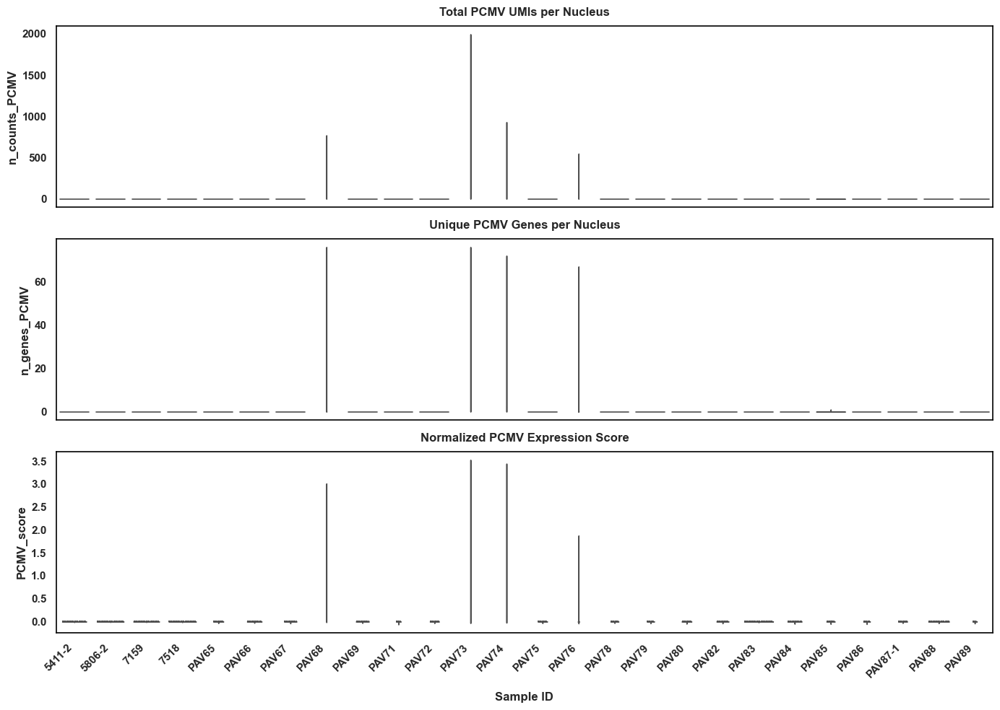

✓ Stacked PCMV violin plots saved to: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/QC_PCMV_metrics_violin_stacked.pdf


In [22]:
# # ============================================================
# #  VIOLIN PLOTS — PCMV METRICS ACROSS SAMPLES
# # ============================================================

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import os


mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.weight": "bold",
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

sns.set_theme(
    style="white", 
    font="Arial", 
    rc={"axes.grid": False, "font.weight": "bold", "axes.labelweight": "bold"}
)

# # ── 2. Define Plot Parameters ────────────────────────────────
metrics = ["n_counts_PCMV", "n_genes_PCMV", "PCMV_score"]
titles = [
    "Total PCMV UMIs per Nucleus", 
    "Unique PCMV Genes per Nucleus", 
    "Normalized PCMV Expression Score"
]

# Sort Sample_IDs alphanumerically for consistent X-axis ordering
sample_order = sorted(pre_qc_adata.obs["Sample_ID"].unique())

# ── 3. Initialize Stacked Canvas ─────────────────────────────
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(14, 10), sharex=True)

# ── 4. Generate Violins ──────────────────────────────────────
for i, (metric, title) in enumerate(zip(metrics, titles)):
    sns.violinplot(
        data=pre_qc_adata.obs, 
        x="Sample_ID", 
        y=metric, 
        # order=sample_order,
        ax=axes[i],
        inner="quartile",   
        linewidth=1.2,
        color="#E67E22",     
        cut=0                
    )
    
    # Format individual subplot axes
    axes[i].set_title(title, fontweight="bold", pad=10)
    axes[i].set_ylabel(metric, fontweight="bold")
    axes[i].set_xlabel("")  
    
    # Enforce bold tick labels on Y axis
    for label in axes[i].get_yticklabels():
        label.set_fontweight("bold")
        
    for spine in ["top", "bottom", "left", "right"]:
        axes[i].spines[spine].set_visible(True)
        axes[i].spines[spine].set_color("black")
        axes[i].spines[spine].set_linewidth(1.2)

# ── 5. Format Bottom X-Axis ──────────────────────────────────
axes[2].set_xlabel("Sample ID", fontweight="bold", labelpad=12)
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=45, ha="right", fontweight="bold")

plt.tight_layout()

# # ── 6. Save Figure ───────────────────────────────────────────
OUT_ROOT = (
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/"
    "xeno/analysis/v1/celltype_annotation/results"
)
os.makedirs(OUT_ROOT, exist_ok=True)
out_pdf = os.path.join(OUT_ROOT, "QC_PCMV_metrics_violin_stacked.pdf")

plt.savefig(out_pdf, bbox_inches="tight", dpi=300)
plt.show()
# 
print(f"✓ Stacked PCMV violin plots saved to: {out_pdf}")

# QC filtering

In [23]:
# ============================================================
#  STEP 4 - QC FILTERING
# ============================================================
print(f"Cells before QC filtering: {pre_qc_adata.n_obs:,}")

# ── 1. Define Boolean Masks for Thresholds ──────────────────
mask_min_genes  = pre_qc_adata.obs["n_genes"] >= 200
mask_min_counts = pre_qc_adata.obs["n_counts"] >= 300

# 2. Ceiling: Remove massive outliers (unresolved doublets)
mask_max_genes  = pre_qc_adata.obs["n_genes"] <= 5000
mask_max_counts = pre_qc_adata.obs["n_counts"] <= 15000

# 3. Quality: Must be pure nuclei (Mito/Ribo <= 1%)
mask_mito = pre_qc_adata.obs["percent_mito"] <= 0.01
mask_ribo = pre_qc_adata.obs["percent_ribo"] <= 0.01

# Combine all masks into one master filter
master_qc_mask = (
    mask_min_genes & 
    mask_min_counts & 
    mask_max_genes & 
    mask_max_counts & 
    mask_mito & 
    mask_ribo
)

qc_adata = pre_qc_adata[master_qc_mask].copy()

# ── 3. Filter Summary ───────────────────────────────────────
cells_removed = pre_qc_adata.n_obs - qc_adata.n_obs
retention_rate = (qc_adata.n_obs / pre_qc_adata.n_obs) * 100

print(f"Cells after QC filtering : {qc_adata.n_obs:,}")
print(f"Cells removed            : {cells_removed:,} ({100 - retention_rate:.1f}%)")

import gc
del pre_qc_adata
gc.collect()

# Save the final cleaned object
out_path = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/Post_QC_filtered_adata_v1.h5ad'
print(f"\nSaving QC-passed object to: {out_path} ...")
qc_adata.write(out_path)
print("✓ Save complete.")

Cells before QC filtering: 262,514
Cells after QC filtering : 243,733
Cells removed            : 18,781 (7.2%)

Saving QC-passed object to: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/Post_QC_filtered_adata_v1.h5ad ...
✓ Save complete.


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


# Pre/post QC filtering plots and CSVs

Loading data...
Recalculating QC metrics for the 'Before' state...


/tmp/ipykernel_3771734/613879539.py:74: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  failure_breakdown = pre_obs.groupby('Sample_ID')[


✓ Grand Master CSV saved successfully to: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/QC_Filtering_Grand_Master_Summary.csv


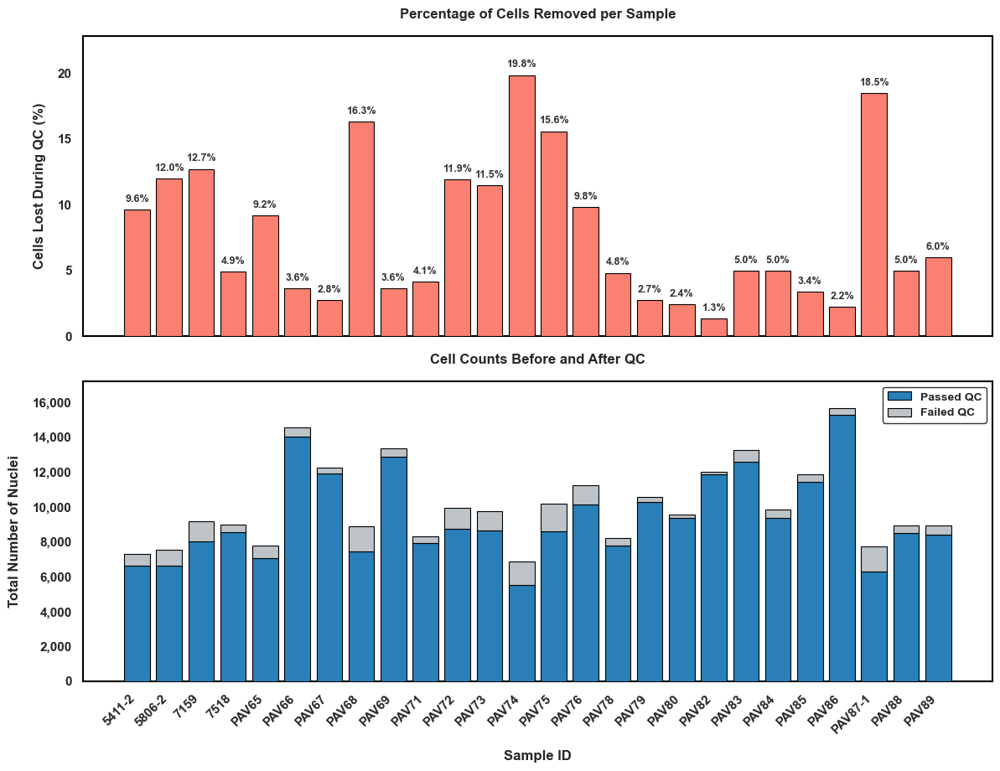

✓ Stacked QC summary visualization generated successfully!
  Target Vector PDF: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/QC_Filtering_Summary_Stacked.pdf


In [24]:
# ============================================================
#  QC FILTERING SUMMARY PLOTS & MASTER CSV
# ============================================================

import os
import scanpy as sc
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as ticker
import seaborn as sns

# ── 1. Re-apply Publication Style ────────────────────────────
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.weight": "bold",
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

sns.set_theme(
    style="white", 
    font="Arial", 
    rc={"axes.grid": False, "font.weight": "bold", "axes.labelweight": "bold"}
)

# ── 2. Load Data (Fully loading pre-QC to compute metrics) ───
print("Loading data...")
pre_qc_path = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/PCMV_fixed_METADATA_added_post_scrublet_and_barnyard_preQC_RAW_concatenated_v1.h5ad'
post_qc_path = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/Post_QC_filtered_adata_v1.h5ad'

# Load fully to calculate metrics
pre_qc = sc.read_h5ad(pre_qc_path)
# Post QC can remain backed since we only need the cell counts
post_qc = sc.read_h5ad(post_qc_path, backed='r') 

# ── 3. Rapidly Recalculate Missing QC Metrics ────────────────
print("Recalculating QC metrics for the 'Before' state...")
sc.pp.calculate_qc_metrics(pre_qc, percent_top=None, log1p=False, inplace=True)
pre_qc.obs["n_counts"] = pre_qc.obs["total_counts"]
pre_qc.obs["n_genes"]  = pre_qc.obs["n_genes_by_counts"]

total_counts = np.asarray(pre_qc.X.sum(axis=1)).flatten()

mito_candidates = [
    "Sus_scrofa___ND1",  "Sus_scrofa___ND2",  "Sus_scrofa___ND3",
    "Sus_scrofa___ND4L", "Sus_scrofa___ND5",  "Sus_scrofa___ND6",
    "Sus_scrofa___COX1", "Sus_scrofa___COX2", "Sus_scrofa___ATP8",
    "Sus_scrofa___ATP6", "Sus_scrofa___COX3", "Sus_scrofa___ND4",
    "Sus_scrofa___CYTB"
]
mito_genes = [g for g in mito_candidates if g in pre_qc.var_names]
pre_qc.obs["percent_mito"] = (np.asarray(pre_qc[:, mito_genes].X.sum(axis=1)).flatten() / total_counts) if mito_genes else 0.0

ribo_genes = [g for g in pre_qc.var_names if re.search(r'_RP[SL][0-9]+$', g)]
pre_qc.obs["percent_ribo"] = (np.asarray(pre_qc[:, ribo_genes].X.sum(axis=1)).flatten() / total_counts) if ribo_genes else 0.0

# ── 4. Calculate Attrition Metrics & Threshold Failures ──────
pre_obs = pre_qc.obs.copy()

# Calculate boolean failures based on your PI's exact thresholds
pre_obs['Failed_Low_Genes (<200)']   = pre_obs["n_genes"] < 200
pre_obs['Failed_Low_UMIs (<300)']    = pre_obs["n_counts"] < 300
pre_obs['Failed_High_Genes (>6000)'] = pre_obs["n_genes"] > 6000
pre_obs['Failed_High_UMIs (>15000)'] = pre_obs["n_counts"] > 15000
pre_obs['Failed_High_Mito (>1%)']    = pre_obs["percent_mito"] > 0.01
pre_obs['Failed_High_Ribo (>1%)']    = pre_obs["percent_ribo"] > 0.01

failure_breakdown = pre_obs.groupby('Sample_ID')[
    ['Failed_Low_Genes (<200)', 'Failed_Low_UMIs (<300)', 
     'Failed_High_Genes (>6000)', 'Failed_High_UMIs (>15000)', 
     'Failed_High_Mito (>1%)', 'Failed_High_Ribo (>1%)']
].sum().astype(int)

pre_counts = pre_obs['Sample_ID'].value_counts()
post_counts = post_qc.obs['Sample_ID'].value_counts()

df_qc = pd.DataFrame({'Cells_Before_QC': pre_counts, 'Cells_After_QC': post_counts}).fillna(0).astype(int)
df_qc['Total_Cells_Removed'] = df_qc['Cells_Before_QC'] - df_qc['Cells_After_QC']
df_qc['Percent_Lost (%)'] = (df_qc['Total_Cells_Removed'] / df_qc['Cells_Before_QC']) * 100
df_qc = df_qc.join(failure_breakdown).sort_index()

# ── 5. Save Grand Master CSV ─────────────────────────────────
OUT_ROOT = (
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/"
    "xeno/analysis/v1/celltype_annotation/results"
)
os.makedirs(OUT_ROOT, exist_ok=True)

csv_path = os.path.join(OUT_ROOT, "QC_Filtering_Grand_Master_Summary.csv")
df_qc.to_csv(csv_path, index_label="Sample_ID")
print(f"✓ Grand Master CSV saved successfully to: {csv_path}")

# ── 6. Generate Stacked 2-Panel Plot ─────────────────────────
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(14, 10), sharex=True)
fig.subplots_adjust(hspace=0.15) 

# --- TOP PANEL ---
axes[0].bar(
    df_qc.index, df_qc['Percent_Lost (%)'], 
    color='salmon', edgecolor='black', linewidth=0.8, zorder=3
)
axes[0].set_ylabel("Cells Lost During QC (%)", fontweight="bold", labelpad=10)
axes[0].set_title("Percentage of Cells Removed per Sample", fontweight="bold", pad=15)
axes[0].set_ylim(0, max(df_qc['Percent_Lost (%)'].max() * 1.15, 10)) 

for i, val in enumerate(df_qc['Percent_Lost (%)']):
    axes[0].text(
        i, val + (df_qc['Percent_Lost (%)'].max() * 0.02), 
        f"{val:.1f}%", ha='center', va='bottom', 
        fontweight='bold', fontsize=9, color='#333333'
    )

# --- BOTTOM PANEL ---
axes[1].bar(
    df_qc.index, df_qc['Cells_After_QC'], 
    color='#2980B9', edgecolor='black', linewidth=0.8, 
    label='Passed QC', zorder=3
)
axes[1].bar(
    df_qc.index, df_qc['Total_Cells_Removed'], 
    bottom=df_qc['Cells_After_QC'], 
    color='#BDC3C7', edgecolor='black', linewidth=0.8, 
    label='Failed QC', zorder=3
)

axes[1].set_ylabel("Total Number of Nuclei", fontweight="bold", labelpad=10)
axes[1].set_title("Cell Counts Before and After QC", fontweight="bold", pad=15)
axes[1].set_xlabel("Sample ID", fontweight="bold", labelpad=12)
axes[1].set_ylim(0, df_qc['Cells_Before_QC'].max() * 1.1)
axes[1].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))
axes[1].set_xticks(range(len(df_qc.index)))
axes[1].set_xticklabels(df_qc.index, rotation=45, ha='right', fontweight='bold')
axes[1].legend(loc="upper right", frameon=True, edgecolor="black", prop={"weight": "bold", "size": 10})

for ax in axes:
    for spine in ["top", "bottom", "left", "right"]:
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_color("black")
        ax.spines[spine].set_linewidth(1.5)
    for label in ax.get_yticklabels():
        label.set_fontweight("bold")

# ── 7. Clean up memory & Save Output ─────────────────────────
import gc
del pre_qc
gc.collect()
post_qc.file.close()

out_pdf = os.path.join(OUT_ROOT, "QC_Filtering_Summary_Stacked.pdf")
plt.savefig(out_pdf, bbox_inches="tight", dpi=300)
plt.show()

print(f"✓ Stacked QC summary visualization generated successfully!")
print(f"  Target Vector PDF: {out_pdf}")

# Pre/post QC violin plots and CSVs

In [25]:
post_qc_adata = sc.read('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/Post_QC_filtered_adata_v1.h5ad')

In [26]:
post_qc_adata

AnnData object with n_obs × n_vars = 243733 × 53826
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp', 'percent_mito', 'percent_ribo', 'n_genes_by_counts', 'total_counts', 'n_counts', 'n_genes', 'n_counts_PCMV', 'n_genes_PCMV', 'PCMV_score'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [27]:
# ============================================================
#  COMPREHENSIVE QC VIOLINS (PRE & POST) + CSV EXPORTS
# ============================================================

import os
import gc
import re
import numpy as np
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# ── 1. Re-apply Publication Style ────────────────────────────
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.weight": "bold",
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

sns.set_theme(
    style="white", 
    font="Arial", 
    rc={"axes.grid": False, "font.weight": "bold", "axes.labelweight": "bold"}
)

# ── 2. Define Output Directory ───────────────────────────────
OUTPUT_DIR = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/pre_post_QC_violins'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── 3. Define Aesthetics & Metrics ───────────────────────────
COND_ORDER = [
    "Control",
    "Prematurely-terminated",
    "3month-protocol",
    "6month-protocol",
    "PCMV/PRV",
    "Rejection",
]

COND_PALETTE = {
    "Control": "#EFE48E",
    "3month-protocol": "#DCB239",
    "6month-protocol": "#76B041",
    "Prematurely-terminated": "#C9B8D9",
    "PCMV/PRV": "#F0C096",
    "Rejection": "#E09E9E",
}

qc_metrics = {
    "n_genes": "Genes per nucleus",
    "n_counts": "Total UMIs per nucleus",
    "percent_mito": "MT% per nucleus",
    "percent_ribo": "Ribo% per nucleus",
    "doublet_score": "Doublet Score",
    "n_counts_Papio_anubis": "Papio anubis UMIs",
    "n_counts_PCMV": "Total PCMV UMIs",
    "PCMV_score": "Normalized PCMV Score"
}

# ── 4. Master Plotting & Export Function ─────────────────────
def generate_qc_set(df_obs, groupby_col, prefix_name):
    """
    Generates a 2x4 stacked violin plot and exports the underlying data to CSV.
    """
    print(f"\nProcessing: {prefix_name} grouped by {groupby_col}...")
    
    # Export the exact data used for the plot to CSV
    export_cols = [groupby_col] + list(qc_metrics.keys())
    csv_out = os.path.join(OUTPUT_DIR, f"{prefix_name}_{groupby_col}_data.csv")
    df_obs[export_cols].to_csv(csv_out)
    print(f"  Saved CSV: {csv_out}")

    # Set up 2x4 grid
    fig, axes = plt.subplots(2, 4, figsize=(22, 12))
    axes = axes.flatten()

    if groupby_col == "Condition":
        order = COND_ORDER
        palette = COND_PALETTE
    else:  # Sample_ID
        order = sorted(df_obs[groupby_col].dropna().unique())
        palette = {s: "#2980B9" for s in order} 

    for ax, (metric, title) in zip(axes, qc_metrics.items()):
        sns.violinplot(
            data=df_obs, 
            x=groupby_col, 
            y=metric, 
            order=order, 
            palette=palette,
            ax=ax, 
            inner="quartile",
            linewidth=1.2,
            cut=0
        )
        
        ax.set_title(title, fontsize=14, fontweight="bold", pad=10)
        ax.set_ylabel("") 
        ax.set_xlabel("")
        
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontweight="bold")
        for label in ax.get_yticklabels():
            label.set_fontweight("bold")
        
        if metric in ["percent_mito", "percent_ribo"]:
            ax.axhline(0.01, color="#C0392B", linestyle="--", linewidth=1.5, label="1% Threshold")
            ax.legend(fontsize=10, frameon=True, edgecolor="black", prop={"weight": "bold"})
        
        for spine in ["top", "bottom", "left", "right"]:
            ax.spines[spine].set_visible(True)
            ax.spines[spine].set_color("black")
            ax.spines[spine].set_linewidth(1.2)

    plt.suptitle(f"{prefix_name.replace('_', ' ')} QC Metrics by {groupby_col}", 
                 fontsize=18, fontweight="bold", y=1.03)
    plt.tight_layout()

    pdf_out = os.path.join(OUTPUT_DIR, f"{prefix_name}_{groupby_col}_violins.pdf")
    plt.savefig(pdf_out, dpi=300, bbox_inches="tight")
    plt.close()
    print(f"  Saved PDF: {pdf_out}")

# ============================================================
#  EXECUTION BLOCK: PRE-QC
# ============================================================
print("\n--- PHASE 1: PRE-QC DATA ---")
pre_qc_path = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/PCMV_fixed_METADATA_added_post_scrublet_and_barnyard_preQC_RAW_concatenated_v1.h5ad'

adata_pre = sc.read_h5ad(pre_qc_path)

# Defensive check: Recalculate metrics missing from the raw saved state
if "n_genes" not in adata_pre.obs.columns or "PCMV_score" not in adata_pre.obs.columns:
    print("Recalculating missing QC metrics for Pre-QC object...")
    sc.pp.calculate_qc_metrics(adata_pre, percent_top=None, log1p=False, inplace=True)
    adata_pre.obs["n_counts"] = adata_pre.obs["total_counts"]
    adata_pre.obs["n_genes"]  = adata_pre.obs["n_genes_by_counts"]
    
    total_counts = np.asarray(adata_pre.X.sum(axis=1)).flatten()
    mito_genes = [g for g in adata_pre.var_names if "ND" in g or "COX" in g or "ATP" in g or "CYTB" in g]
    ribo_genes = [g for g in adata_pre.var_names if re.search(r'_RP[SL][0-9]+$', g)]
    
    adata_pre.obs["percent_mito"] = (np.asarray(adata_pre[:, mito_genes].X.sum(axis=1)).flatten() / total_counts) if mito_genes else 0.0
    adata_pre.obs["percent_ribo"] = (np.asarray(adata_pre[:, ribo_genes].X.sum(axis=1)).flatten() / total_counts) if ribo_genes else 0.0

    # Re-calculate PCMV Metrics
    pcmv_genes = [g for g in adata_pre.var_names if "pCMV" in g or "Sus_scrofa___KCNJ12" == g]
    if pcmv_genes:
        adata_pre.obs["n_counts_PCMV"] = np.asarray(adata_pre[:, pcmv_genes].X.sum(axis=1)).flatten()
        tmp = adata_pre.copy()
        sc.pp.normalize_total(tmp, target_sum=1e4)
        sc.pp.log1p(tmp)
        sc.tl.score_genes(tmp, pcmv_genes, random_state=12, score_name="PCMV_score")
        adata_pre.obs["PCMV_score"] = tmp.obs["PCMV_score"]
        del tmp
    else:
        adata_pre.obs["n_counts_PCMV"] = 0.0
        adata_pre.obs["PCMV_score"] = 0.0

df_pre = adata_pre.obs.copy()
df_pre["Condition"] = pd.Categorical(df_pre["Condition"], categories=COND_ORDER, ordered=True)

generate_qc_set(df_pre, "Condition", "Pre_QC")
generate_qc_set(df_pre, "Sample_ID", "Pre_QC")

del adata_pre
del df_pre
gc.collect()

# ============================================================
#  EXECUTION BLOCK: POST-QC
# ============================================================
print("\n--- PHASE 2: POST-QC DATA ---")
post_qc_path = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/Post_QC_filtered_adata_v1.h5ad'

adata_post = sc.read_h5ad(post_qc_path)

df_post = adata_post.obs.copy()
df_post["Condition"] = pd.Categorical(df_post["Condition"], categories=COND_ORDER, ordered=True)

generate_qc_set(df_post, "Condition", "Post_QC")
generate_qc_set(df_post, "Sample_ID", "Post_QC")

del adata_post
del df_post
gc.collect()

print("\n✓ ALL PLOTS AND CSVS GENERATED SUCCESSFULLY.")


--- PHASE 1: PRE-QC DATA ---
Recalculating missing QC metrics for Pre-QC object...

Processing: Pre_QC grouped by Condition...
  Saved CSV: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/pre_post_QC_violins/Pre_QC_Condition_data.csv


/tmp/ipykernel_3771734/455454564.py:91: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_3771734/455454564.py:107: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontweight="bold")
/tmp/ipykernel_3771734/455454564.py:91: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_3771734/455454564.py:107: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontweight="bold")
/tmp/i

  Saved PDF: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/pre_post_QC_violins/Pre_QC_Condition_violins.pdf

Processing: Pre_QC grouped by Sample_ID...
  Saved CSV: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/pre_post_QC_violins/Pre_QC_Sample_ID_data.csv


/tmp/ipykernel_3771734/455454564.py:91: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_3771734/455454564.py:107: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontweight="bold")
/tmp/ipykernel_3771734/455454564.py:91: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_3771734/455454564.py:107: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontweight="bold")
/tmp/i

  Saved PDF: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/pre_post_QC_violins/Pre_QC_Sample_ID_violins.pdf

--- PHASE 2: POST-QC DATA ---

Processing: Post_QC grouped by Condition...
  Saved CSV: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/pre_post_QC_violins/Post_QC_Condition_data.csv


/tmp/ipykernel_3771734/455454564.py:91: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_3771734/455454564.py:107: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontweight="bold")
/tmp/ipykernel_3771734/455454564.py:91: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_3771734/455454564.py:107: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontweight="bold")
/tmp/i

  Saved PDF: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/pre_post_QC_violins/Post_QC_Condition_violins.pdf

Processing: Post_QC grouped by Sample_ID...
  Saved CSV: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/pre_post_QC_violins/Post_QC_Sample_ID_data.csv


/tmp/ipykernel_3771734/455454564.py:91: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_3771734/455454564.py:107: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontweight="bold")
/tmp/ipykernel_3771734/455454564.py:91: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_3771734/455454564.py:107: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontweight="bold")
/tmp/i

  Saved PDF: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/pre_post_QC_violins/Post_QC_Sample_ID_violins.pdf

✓ ALL PLOTS AND CSVS GENERATED SUCCESSFULLY.


# Pearson heatmap & scatter plot 

In [28]:
# ==============================================================================
#  PSEUDO-BULK PCA & PEARSON CORRELATION
# ==============================================================================

import os
import re
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.decomposition import PCA
from adjustText import adjust_text
import seaborn as sns

# ==============================================================================
# 1. MASTER CONFIGURATION
# ==============================================================================
INPUT_FILE = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/Post_QC_filtered_adata_v1.h5ad'
OUTPUT_DIR = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/pearson_scatterplot_PCA'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Publication Aesthetics
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.weight": "bold", "axes.labelweight": "bold", 
    "axes.titleweight": "bold", "figure.dpi": 300, "font.size": 12,
    "pdf.fonttype": 42, "ps.fonttype": 42
})

COND_ORDER = [
    "Control",
    "Prematurely-terminated",
    "3month-protocol",
    "6month-protocol",
    "PCMV/PRV",
    "Rejection",
]

COND_PALETTE = {
    "Control": "#EFE48E",
    "3month-protocol": "#DCB239",
    "6month-protocol": "#76B041",
    "Prematurely-terminated": "#C9B8D9",
    "PCMV/PRV": "#F0C096",
    "Rejection": "#E09E9E",
}

# ==============================================================================
# 2. AGGREGATION & NORMALIZATION
# ==============================================================================
print("Loading QC-filtered data...")
adata = sc.read_h5ad(INPUT_FILE)
print(f"Loaded {adata.n_obs:,} cells, {adata.n_vars:,} genes.")

# Memory-efficient sparse pseudo-bulk aggregation
print("Aggregating sparse matrices...")
sample_ids = adata.obs['Sample_ID'].unique()
agg_list = []

for sid in sample_ids:
    subset = adata[adata.obs['Sample_ID'] == sid]
    # Sum across the cell axis (0) while retaining sparse format until the 1D flatten
    sample_sum = np.asarray(subset.X.sum(axis=0)).flatten()
    agg_list.append(sample_sum)

agg_matrix = pd.DataFrame(agg_list, index=sample_ids, columns=adata.var_names)

# CPM + Log1p Normalization
print("Normalizing and computing HVGs...")
cpm = agg_matrix.div(agg_matrix.sum(axis=1), axis=0) * 1e6
log_cpm = np.log1p(cpm)

# Subset to top 2000 HVGs (Removes noise, essential for PCA/Correlation)
gene_vars = log_cpm.var(axis=0)
hvg_genes = gene_vars.nlargest(2000).index
log_cpm_hvg = log_cpm[hvg_genes]

# Z-score standardization across samples
Z = (log_cpm_hvg - log_cpm_hvg.mean(axis=0)) / log_cpm_hvg.std(axis=0).replace(0, np.nan)
Z = Z.fillna(0.0)

# ==============================================================================
# 3. SORTING LOGIC
# ==============================================================================
# Map conditions for sorting
sample_to_cond = adata.obs[['Sample_ID', 'Condition']].drop_duplicates().set_index('Sample_ID')['Condition'].to_dict()

def custom_sort_key(sid):
    """Sorts primarily by COND_ORDER to block heatmap by experimental group, then by numeric ID."""
    cond = sample_to_cond.get(sid, "Other")
    cond_idx = COND_ORDER.index(cond) if cond in COND_ORDER else 99
    
    # Extract numerical value for secondary sorting
    nums = re.findall(r'\d+', str(sid))
    num = int(nums[0]) if nums else 0
    return (cond_idx, num, sid)

sorted_ids = sorted(log_cpm_hvg.index, key=custom_sort_key)
log_cpm_sorted = log_cpm_hvg.reindex(sorted_ids)
Z_sorted = Z.reindex(sorted_ids)

# ==============================================================================
# 4. PCA PLOT
# ==============================================================================
print("Performing PCA...")
pca = PCA(n_components=2, random_state=42)
pca_data = pca.fit_transform(Z_sorted.values)
pca_df = pd.DataFrame(pca_data, index=sorted_ids, columns=["PC1", "PC2"])

# Map condition to PCA coordinates
pca_df["Condition"] = pca_df.index.map(sample_to_cond)
pca_df.to_csv(os.path.join(OUTPUT_DIR, "pca_coordinates.csv"))

for show_labels in [True, False]:
    # FIX: Set layout="tight" natively during figure creation
    fig, ax = plt.subplots(figsize=(9, 7), layout="tight")
    ax.grid(False)
    
    # Plot iteratively by explicit COND_ORDER to ensure legend follows hierarchy
    for cond in COND_ORDER:
        sub = pca_df[pca_df["Condition"] == cond]
        if not sub.empty:
            ax.scatter(sub["PC1"], sub["PC2"], s=150, alpha=0.9, 
                       edgecolors="black", linewidths=1.2, 
                       color=COND_PALETTE[cond], label=cond, zorder=3)
    
    if show_labels:
        texts = [ax.text(row["PC1"], row["PC2"], sid, fontsize=10, fontweight="bold", zorder=4) 
                 for sid, row in pca_df.iterrows()]
        adjust_text(texts, arrowprops=dict(arrowstyle='-', color='#555555', lw=0.8))
        suffix = "_labeled"
    else:
        suffix = "_clean"
        
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)", fontweight="bold")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)", fontweight="bold")
    ax.set_title("Sample Pseudo-Bulk PCA (Top 2000 HVGs)", fontweight="bold", pad=15)
    
    # Legend formatting
    ax.legend(title="Condition", frameon=True, edgecolor="black", prop={'weight':'bold'}, 
              bbox_to_anchor=(1.02, 1), loc='upper left')
    
    for spine in ax.spines.values(): 
        spine.set_linewidth(1.5)
        spine.set_color("black")
        
    # Removed plt.tight_layout() here
    fig.savefig(os.path.join(OUTPUT_DIR, f"PCA_scatter{suffix}.pdf"), bbox_inches="tight")
    plt.close(fig)

# ==============================================================================
# 5. HEATMAP PLOT (Sample-wise Pearson Correlation)
# ==============================================================================
print("Calculating Pearson Correlation...")
corr_df = log_cpm_sorted.T.corr(method="pearson")
corr_df.to_csv(os.path.join(OUTPUT_DIR, "pearson_correlation_matrix.csv"))

vmin = corr_df.values.min()
vmax = corr_df.values.max()

# FIX: Set layout="tight" natively during figure creation to prevent colorbar clash
fig2, ax2 = plt.subplots(figsize=(12, 10), layout="tight")
ax2.grid(False)
im = ax2.imshow(corr_df.values, aspect="auto", cmap="RdBu_r", vmin=vmin, vmax=vmax)

# Format ticks
ax2.set_xticks(range(len(corr_df)))
ax2.set_yticks(range(len(corr_df)))
ax2.set_xticklabels(corr_df.index, rotation=90, fontsize=10, fontweight="bold")
ax2.set_yticklabels(corr_df.index, fontsize=10, fontweight="bold")
ax2.set_title("Sample-wise Pearson Correlation (Top 2000 HVGs)", fontweight="bold", pad=20)

# Add colorbar safely
cbar = fig2.colorbar(im, ax=ax2, pad=0.02)
cbar.set_label("Pearson Correlation", fontweight="bold", labelpad=10)
cbar.ax.tick_params(labelsize=10)

# Add conditional bounding lines to visually separate the experimental groups in the heatmap
group_boundaries = []
current_cond = pca_df.iloc[0]["Condition"]
for i in range(1, len(pca_df)):
    if pca_df.iloc[i]["Condition"] != current_cond:
        group_boundaries.append(i - 0.5)
        current_cond = pca_df.iloc[i]["Condition"]

for boundary in group_boundaries:
    ax2.axhline(boundary, color="black", linewidth=1.5, zorder=5)
    ax2.axvline(boundary, color="black", linewidth=1.5, zorder=5)

for spine in ax2.spines.values(): 
    spine.set_linewidth(1.5)
    spine.set_color("black")

# Removed plt.tight_layout() here to prevent the RuntimeError
fig2.savefig(os.path.join(OUTPUT_DIR, "pearson_correlation_heatmap.pdf"), bbox_inches="tight")
plt.close(fig2)

print(f"✓ Master script complete. Outputs saved to:\n  {OUTPUT_DIR}")

Loading QC-filtered data...
Loaded 243,733 cells, 53,826 genes.
Aggregating sparse matrices...
Normalizing and computing HVGs...
Performing PCA...
Calculating Pearson Correlation...
✓ Master script complete. Outputs saved to:
  /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/pearson_scatterplot_PCA


In [29]:
post_qc_adata = sc.read('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/Post_QC_filtered_adata_v1.h5ad')

Loaded: 243,733 nuclei  ×  53,826 genes
Conditions:
Condition
3month-protocol           75631
Rejection                 51894
6month-protocol           34420
Prematurely-terminated    30438
Control                   29774
PCMV/PRV                  21576


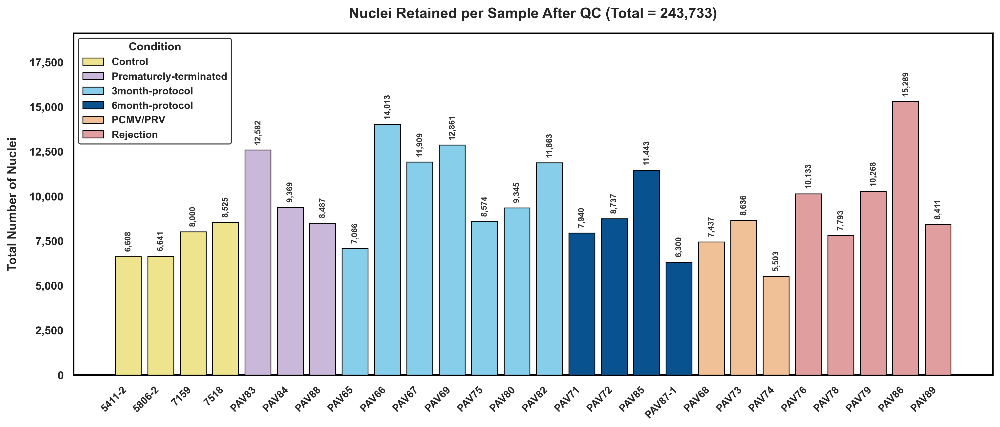

✓ Saved: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/cell_counts_per_sample_grouped.pdf


In [33]:
# ============================================================
#  PLOT: NUCLEI COUNTS PER SAMPLE
# ============================================================


# ── 2. Define Output and Palette ─────────────────────────────
OUTPUT_DIR = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/'
os.makedirs(OUTPUT_DIR, exist_ok=True)

COND_ORDER = [
    "Control",
    "Prematurely-terminated",
    "3month-protocol",
    "6month-protocol",
    "PCMV/PRV",
    "Rejection",
]

COND_PALETTE = {
    "Control": "#EFE48E",
    "3month-protocol": "skyblue",
    "6month-protocol": "#08528f",
    "Prematurely-terminated": "#C9B8D9",
    "PCMV/PRV": "#F0C096",
    "Rejection": "#E09E9E",
}

print(f"Loaded: {post_qc_adata.n_obs:,} nuclei  ×  {post_qc_adata.n_vars:,} genes")
print(f"Conditions:\n{post_qc_adata.obs['Condition'].value_counts().to_string()}")

# ── 3. Extract and Sort Data ─────────────────────────────────
sample_meta = post_qc_adata.obs[["Sample_ID", "Condition"]].drop_duplicates().set_index("Sample_ID")
counts = post_qc_adata.obs["Sample_ID"].value_counts()

# Advanced Sorting: Group by Condition order first, then alphanumerically
def sort_key(sid):
    cond = sample_meta.loc[sid, "Condition"]
    cond_idx = COND_ORDER.index(cond) if cond in COND_ORDER else 99
    nums = re.findall(r'\d+', str(sid))
    num = int(nums[0]) if nums else 0
    return (cond_idx, num, sid)

sorted_sids = sorted(counts.index, key=sort_key)
counts = counts.reindex(sorted_sids)

# Map colors to the newly sorted index
bar_colors = [COND_PALETTE.get(sample_meta.loc[s, "Condition"], "#BDC3C7") for s in counts.index]

# ── 4. Generate Plot ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(16, 6)) # Slightly taller to fit bold labels
bars = ax.bar(
    range(len(counts)), 
    counts.values, 
    color=bar_colors, 
    edgecolor="black",  # Switched to black for crisp contrast
    linewidth=0.8,
    zorder=3
)

# Format Axes
ax.set_xticks(range(len(counts)))
ax.set_xticklabels(counts.index, rotation=45, ha="right", fontweight="bold", fontsize=10)
ax.set_ylabel("Total Number of Nuclei", fontsize=12, fontweight="bold", labelpad=10)
ax.set_title(f"Nuclei Retained per Sample After QC (Total = {post_qc_adata.n_obs:,})", 
             fontsize=14, fontweight="bold", pad=15)

# Add comma grouping to Y-axis (e.g., 10,000 instead of 10000)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

# ── 5. Add Annotations & Legends ─────────────────────────────
# Add counts above bars
for bar, val in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2, 
        bar.get_height() + (counts.max() * 0.02), 
        f"{val:,}", 
        ha="center", va="bottom", 
        fontweight="bold", fontsize=8, color="#333333", rotation=90
    )

# Increase Y-limit to make room for text
ax.set_ylim(0, counts.max() * 1.25)

# Nature-style 4-sided border
for spine in ["top", "bottom", "left", "right"]:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_color("black")
    ax.spines[spine].set_linewidth(1.5)

# Enforce bold Y-ticks
for label in ax.get_yticklabels():
    label.set_fontweight("bold")

# Custom Legend
legend_handles = [Patch(facecolor=COND_PALETTE[cond], edgecolor="black", linewidth=0.8, label=cond) 
                  for cond in COND_ORDER if cond in sample_meta["Condition"].values]
ax.legend(
    handles=legend_handles, 
    title="Condition",
    title_fontproperties={"weight": "bold", "size": 11},
    loc="upper left", 
    frameon=True, 
    edgecolor="black",
    fontsize=10
)

# ── 6. Save Output ───────────────────────────────────────────
out_pdf = os.path.join(OUTPUT_DIR, "cell_counts_per_sample_grouped.pdf")
plt.savefig(out_pdf, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"✓ Saved: {out_pdf}")

# Preprocessing

In [34]:
post_qc_adata = sc.read('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/Post_QC_filtered_adata_v1.h5ad')

In [35]:
adata = post_qc_adata.copy()

# Step 2: Preprocess - Normalize and Log Transform
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

adata.raw = adata.copy()



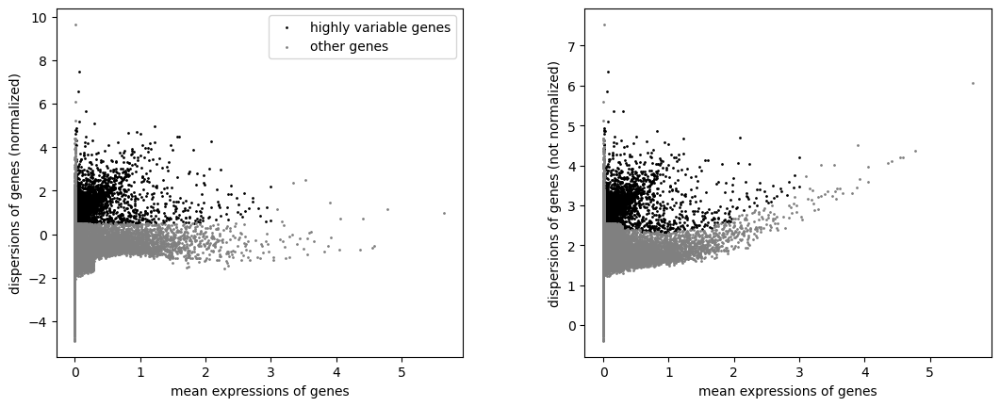

In [4]:
# sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
# sc.pl.highly_variable_genes(adata)
# adata_hvg = adata[:, adata.var.highly_variable]

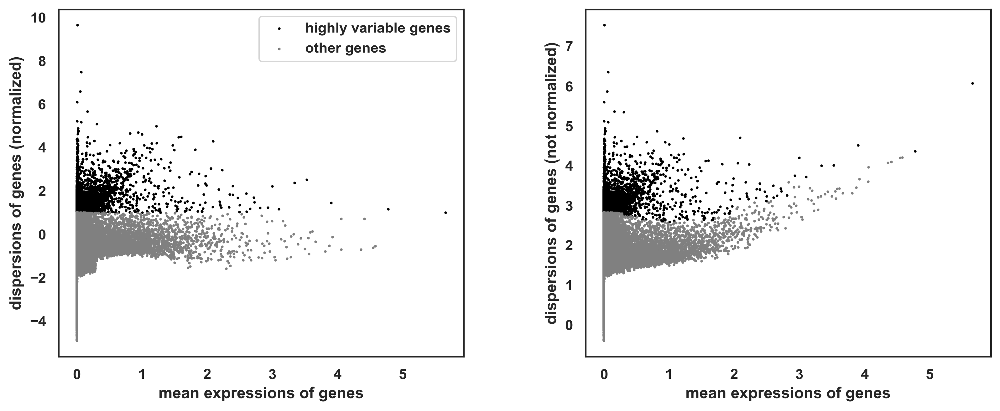

Number of highly variable genes (HVGs): 4500
Subsetting complete. New shape: (243733, 4500)


In [36]:
# Identify highly variable genes 
sc.pp.highly_variable_genes(
    adata, 
    n_top_genes=4500, 
    subset=False, 
    flavor='seurat'
)

# 2. Plot highly variable genes
# This will highlight the top 5000 in red
sc.pl.highly_variable_genes(adata)

# 3. Verify the count
num_hvgs = adata.var['highly_variable'].sum()
print(f"Number of highly variable genes (HVGs): {num_hvgs}")

# 4. Subset to HVGs for downstream analysis (PCA/Harmony)
# We keep a copy of the full object if needed, but subset for speed
adata_hvg = adata[:, adata.var['highly_variable']].copy()

print(f"Subsetting complete. New shape: {adata_hvg.shape}")


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


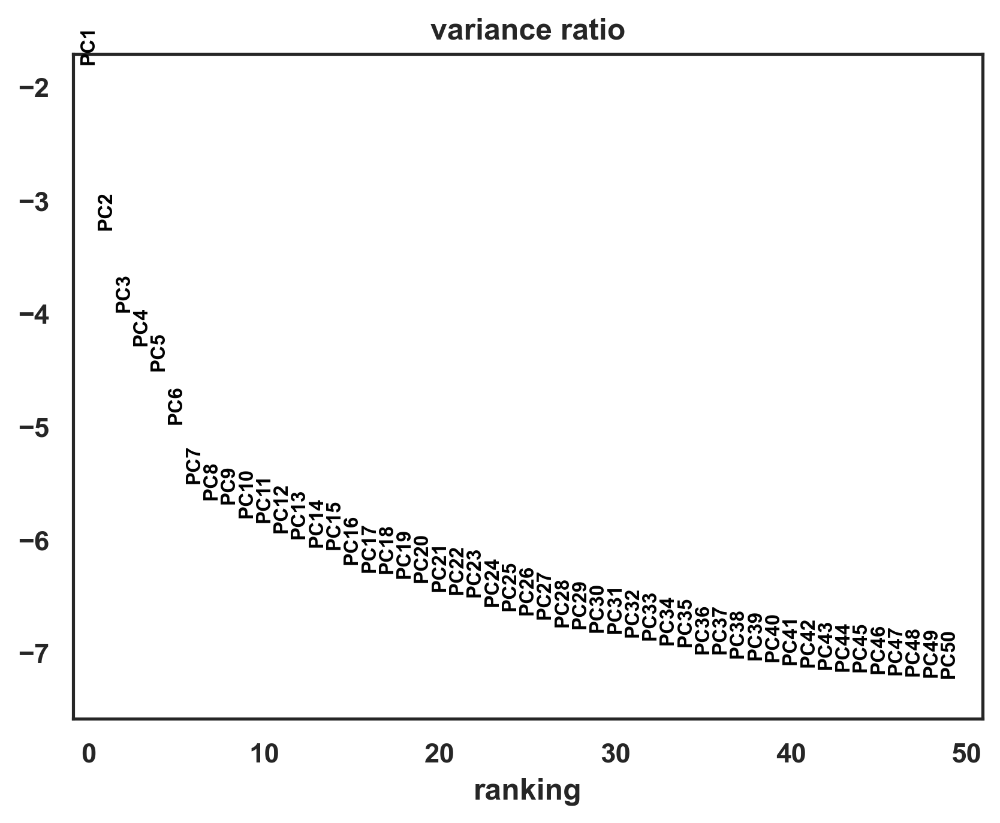

/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [37]:
# 2. Scale the data (z=score normalization)
sc.pp.scale(adata_hvg, max_value=10)  # max_value=10 clips extreme outliers

# 3. Run PCA
sc.tl.pca(adata_hvg, n_comps=50, svd_solver='arpack')  # Adjust n_comps as needed

# 4. (Optional) Plot variance explained
sc.pl.pca_variance_ratio(adata_hvg, log=True, n_pcs=50)

adata_hvg.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/adata_hvg_xeno_v1.h5ad')


In [38]:
pca_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/adata_hvg_xeno_v1.h5ad')


# Harmony

In [2]:
pca_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/adata_hvg_xeno_v1.h5ad')


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


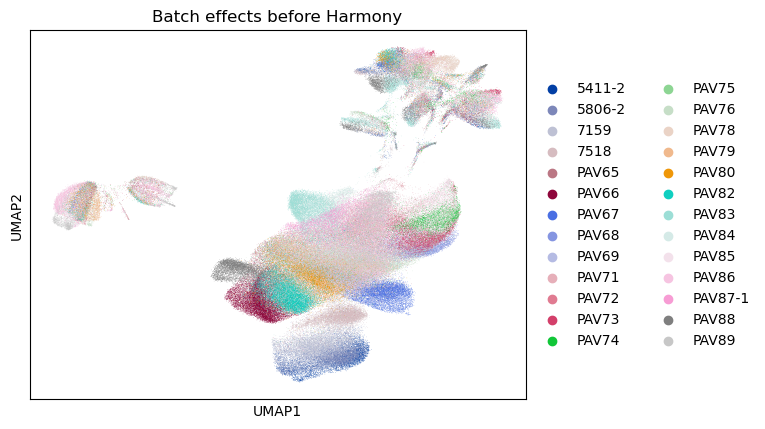

In [3]:
# Checking batch effects before Harmony
sc.pp.neighbors(pca_adata, random_state=10, n_neighbors=25, n_pcs=50)

# Perform UMAP
sc.tl.umap(pca_adata)

# Plot UMAP colored by sample (batch) and save it
sc.pl.umap (pca_adata, color=['Sample_ID'],  title='Batch effects before Harmony')

In [4]:

pca_matrix = pca_adata.obsm["X_pca"][:, :50].copy()
print(f"PCA matrix passed to Harmony: {pca_matrix.shape}")

ho = hm.run_harmony(
    pca_matrix,
    pca_adata.obs,
    vars_use="Sample_ID",
    max_iter_harmony=20,
    epsilon_harmony=-float('Inf'),ce
    epsilon_cluster=-float('Inf'), 
    
    random_state=10,
    verbose=True         
)
 
pca_adata.obsm["X_pca_harmony"] = ho.Z_corr.T
 
print(f"\nHarmony embedding stored in obsm['X_pca_harmony']")
print(f"Shape: {pca_adata.obsm['X_pca_harmony'].shape}") 
 

2026-06-17 11:46:18,488 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...


PCA matrix passed to Harmony: (243733, 50)


2026-06-17 11:46:51,460 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-06-17 11:46:51,951 - harmonypy - INFO - Iteration 1 of 20
2026-06-17 11:48:02,181 - harmonypy - INFO - Iteration 2 of 20
2026-06-17 11:49:16,857 - harmonypy - INFO - Iteration 3 of 20
2026-06-17 11:50:31,466 - harmonypy - INFO - Iteration 4 of 20
2026-06-17 11:51:46,144 - harmonypy - INFO - Iteration 5 of 20
2026-06-17 11:53:01,119 - harmonypy - INFO - Iteration 6 of 20
2026-06-17 11:54:16,077 - harmonypy - INFO - Iteration 7 of 20
2026-06-17 11:55:31,092 - harmonypy - INFO - Iteration 8 of 20
2026-06-17 11:56:46,184 - harmonypy - INFO - Iteration 9 of 20
2026-06-17 11:58:00,971 - harmonypy - INFO - Iteration 10 of 20
2026-06-17 11:59:15,340 - harmonypy - INFO - Iteration 11 of 20
2026-06-17 12:00:29,766 - harmonypy - INFO - Iteration 12 of 20
2026-06-17 12:01:44,908 - harmonypy - INFO - Iteration 13 of 20
2026-06-17 12:02:59,980 - harmonypy - INFO - Iteration 14 of 20
2026-06-17 12:04:14,927 - ha


Harmony embedding stored in obsm['X_pca_harmony']
Shape: (243733, 50)


In [5]:
pca_adata.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/hm_adata_xeno_v1.h5ad')

/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [6]:
hm_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/hm_adata_xeno_v1.h5ad')

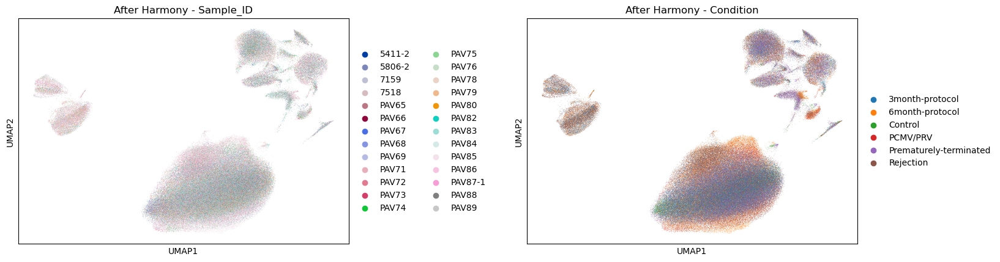

In [7]:
# Compute neighbors using Harmony embeddings
sc.pp.neighbors(
    hm_adata, 
    use_rep='X_pca_harmony', 
    n_neighbors=25, 
    n_pcs=50,
    random_state=10
)

# Recompute UMAP based on Harmony
sc.tl.umap(hm_adata, random_state=10)

# Visualize - should show reduced batch effects
sc.pl.umap(
    hm_adata, color=['Sample_ID', 'Condition'],  ncols=2, wspace = 0.4,  title=['After Harmony - Sample_ID', 'After Harmony - Condition']
)

In [8]:
# 1. Compute Neighbors (Graph building)
sc.pp.neighbors(
    hm_adata, 
    use_rep='X_pca_harmony', 
    n_neighbors=25, 
    n_pcs=50,
    random_state=10
)

sc.tl.umap(
    hm_adata, 
    min_dist=0.5, 
    spread=2, 
    random_state=10
)

# 3. Run Leiden Clustering (Community detection)
resolutions = [
    0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9
              ]

for res in resolutions:
    # Formats key cleanly (e.g., leiden_03, leiden_04)
    key = f"leiden_{str(res).replace('.', '')}"
    print(f"Running Leiden clustering at resolution {res} -> stored in {key}")
    
    sc.tl.leiden(
        hm_adata, 
        resolution=res, 
        key_added=key, 
        random_state=10
    )

print("✓ UMAP and Leiden clustering complete.")

Running Leiden clustering at resolution 0.3 -> stored in leiden_03


/tmp/ipykernel_409279/2329355908.py:28: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


Running Leiden clustering at resolution 0.4 -> stored in leiden_04


IOStream.flush timed out
IOStream.flush timed out


Running Leiden clustering at resolution 0.5 -> stored in leiden_05
Running Leiden clustering at resolution 0.6 -> stored in leiden_06
Running Leiden clustering at resolution 0.7 -> stored in leiden_07
Running Leiden clustering at resolution 0.8 -> stored in leiden_08


IOStream.flush timed out


Running Leiden clustering at resolution 0.9 -> stored in leiden_09
✓ UMAP and Leiden clustering complete.


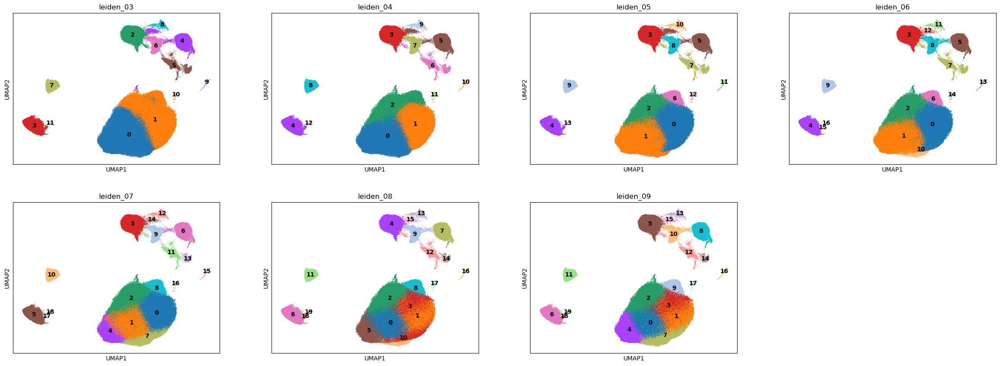

In [13]:

sc.pl.umap( hm_adata, color=[  "leiden_03", "leiden_04", "leiden_05" , "leiden_06" , "leiden_07", "leiden_08" , "leiden_09" ],
            legend_loc="on data",  size=5)


In [14]:
hm_adata.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/clustered_adata_xeno_v1.h5ad')

/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [15]:
clustered_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/clustered_adata_xeno_v1.h5ad')

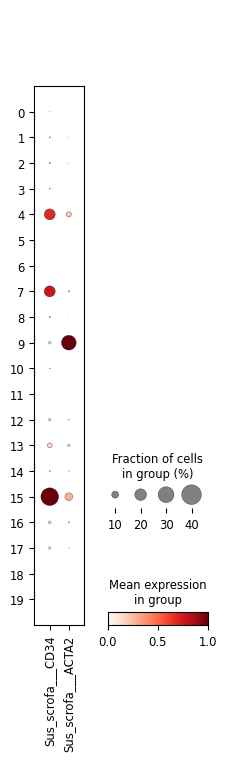

In [67]:
sc.pl.dotplot(
    clustered_adata, 
    var_names=[

# 'Sus_scrofa___FN1', 
        # 'Sus_scrofa___CDH5', 'Sus_scrofa___PECAM1', 'Sus_scrofa___VWF', 'Sus_scrofa___NOS3', 'Sus_scrofa___PLVAP', 'Sus_scrofa___NOS3', 
        # 'Sus_scrofa___TCF21', 
        # 'Sus_scrofa___PDGFRA', 'Sus_scrofa___DCN',
        # 'Sus_scrofa___SNAI1', 'Sus_scrofa___SNAI2',  'Sus_scrofa___ZEB1', 'Sus_scrofa___ZEB2',
        #         'Sus_scrofa___CDH2', 'Sus_scrofa___ACTA2',  'Sus_scrofa___TAGLN', 'Sus_scrofa___VIM',
        #  'Sus_scrofa___RGS5', 
        'Sus_scrofa___CD34', 'Sus_scrofa___ACTA2'


        
    ], 
    groupby='leiden_08', 
    # standard_scale='var',  # Scales expression from 0 to 1 for better comparison
    cmap='Reds', 
    standard_scale = 'var',
    # use_raw = True

)
    

In [2]:
def stacked_barplot(adata, xaxis, stack, xaxis_label, legend_label, shift_top=0.2, xaxis_rotation=45, figsize=(10,10), percent=True):
    tmp=pd.crosstab(adata.obs[xaxis],
                adata.obs[stack]).sum(axis=1)
    
    ax= pd.crosstab(adata.obs[xaxis], 
                    adata.obs[stack]).apply(lambda r: r/r.sum()*100, axis=1)
    #ax_1 = ax.plot.bar(figsize=(10,10),stacked=True, rot=0, colors=colors)
    ax_1 = ax.plot.bar(figsize=figsize,stacked=True, rot=0)
    #display(ax)
    #plt.legend(title="Subject") # loc='upper center', bbox_to_anchor=(0.1, 1.0), 
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), title=legend_label)
    plt.xlabel(xaxis_label,fontweight="bold")
    plt.ylabel('Percent Distribution',fontweight="bold")
    
    if percent:
        for rec in ax_1.patches:
            height = rec.get_height()
            ax_1.text(rec.get_x() + rec.get_width() / 2, rec.get_y() + height/2, "{:.0f}%".format(height),
                   ha = 'center', va='center', fontsize=14.5, weight='bold') #
    
    for xaxistick in range(ax.shape[0]):
        ax_1.text(xaxistick-shift_top,110,tmp[xaxistick],va='center', rotation=45, fontsize=14.5, weight='bold')
    
    plt.xticks(rotation=xaxis_rotation)
    
    ax_1.grid(False)
    plt.show()

In [3]:
stacked_barplot(dea_adata, 'Condition', 'leiden_08', 
                'Condition', 'leiden_08', 
                shift_top=0.2, xaxis_rotation=45, 
                figsize=(8,20), percent=True)

NameError: name 'dea_adata' is not defined

# DEA

In [23]:
clustered_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/clustered_adata_xeno_v1.h5ad')

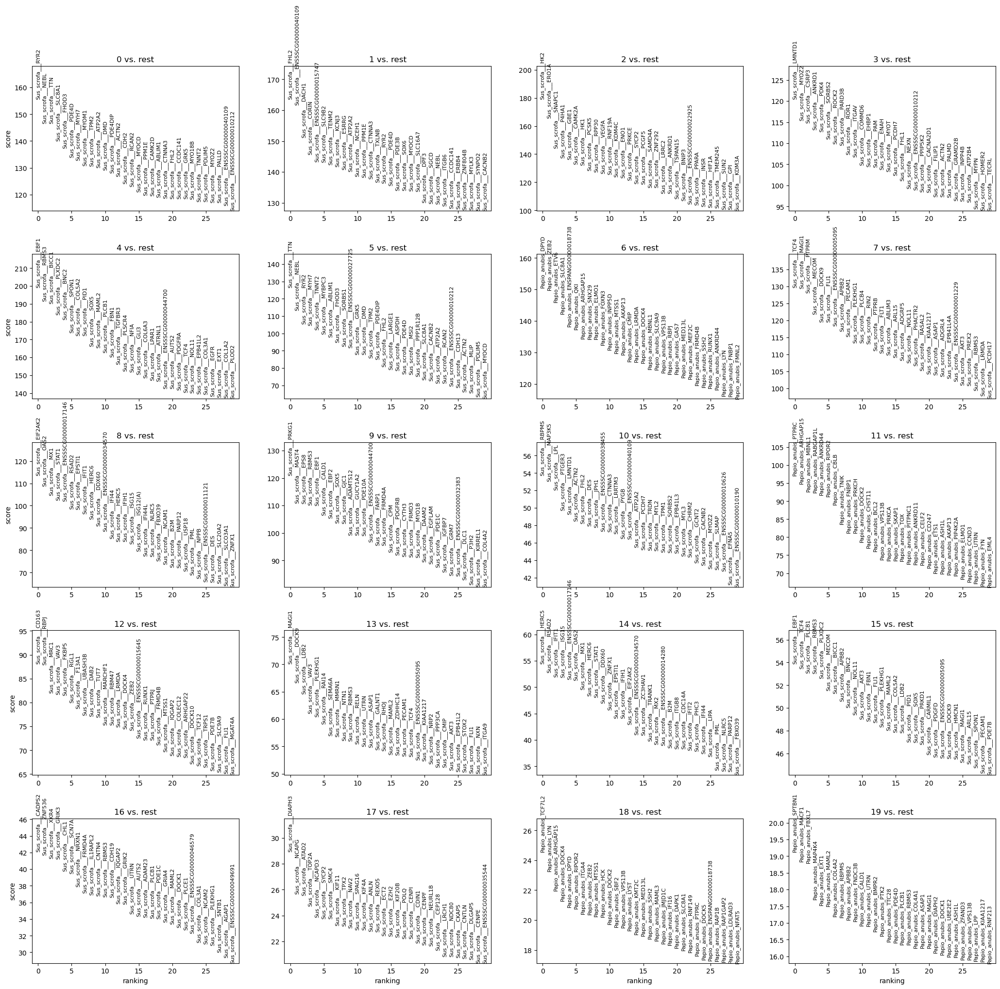

In [26]:
# Perform differential expression to find marker genes for each cluster
sc.tl.rank_genes_groups(clustered_adata, 'leiden_08', method='wilcoxon', key_added='wilcoxon', use_raw=True)

# Visualize the top marker genes for each cluster
sc.pl.rank_genes_groups(clustered_adata, key='wilcoxon', n_genes=30, sharey=False)


In [27]:
clustered_adata.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/dea_adata_xeno_v1.h5ad')

/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [2]:
dea_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/dea_adata_xeno_v1.h5ad')

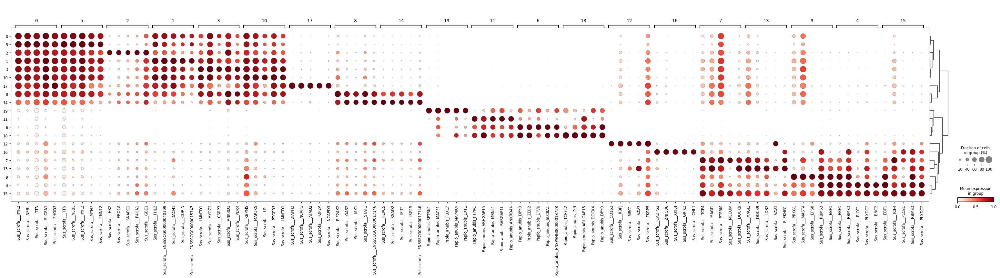

In [29]:
%matplotlib inline

sc.pl.rank_genes_groups_dotplot(dea_adata, key="wilcoxon", n_genes=5, standard_scale="var"
                                # , cmap="coolwarm", vmin= -1
                               )


In [31]:
import pandas as pd
import os

de_key = 'wilcoxon' 
results = dea_adata.uns[de_key]
clusters = results['names'].dtype.names 

output_dir = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/DEGs'
os.makedirs(output_dir, exist_ok=True)

for clust in clusters:
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    # Optional: Sort by Wilcoxon score, descending (highest first)
    df = df.sort_values('score', ascending=False)
    # Save to CSV
    df.to_csv(f"{output_dir}/Cluster_{clust}_DEGs.csv", index=False)



In [32]:
import os
import pandas as pd

# 1. Setup paths
base_results_dir = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/DEGs'
sig_output_dir = os.path.join(base_results_dir, "significant_DEGs")
os.makedirs(sig_output_dir, exist_ok=True)

# 2. Thresholds
P_ADJ_CUTOFF = 0.05
LFC_CUTOFF = 2

print(f"Filtering DEGs: pval_adj < {P_ADJ_CUTOFF} and |logfoldchange| > {LFC_CUTOFF}")

# 3. Process each cluster's results from your previous loop
# Using the 'clusters' variable from your previous code block
for clust in clusters:
    # Extract data from the scanpy results object
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    # Create the DataFrame
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    
    sig_df = df[
        (df['pval_adj'] < P_ADJ_CUTOFF) & 
        ((df['logfoldchange'] > LFC_CUTOFF) | (df['logfoldchange'] < -LFC_CUTOFF))
    ].copy()
    
    # Sort by logfoldchange descending
    sig_df = sig_df.sort_values('logfoldchange', ascending=False)
    
    # 5. Save if there are significant genes found
    if not sig_df.empty:
        output_file = f"{sig_output_dir}/Significant_Cluster_{clust}_DEGs.csv"
        sig_df.to_csv(output_file, index=False)
        print(f"  Cluster {clust}: Saved {len(sig_df)} significant DEGs.")
    else:
        print(f"  Cluster {clust}: No genes met the significance criteria.")

print("\nAll significant files saved in:", sig_output_dir)

Filtering DEGs: pval_adj < 0.05 and |logfoldchange| > 2
  Cluster 0: Saved 3972 significant DEGs.
  Cluster 1: Saved 3206 significant DEGs.
  Cluster 2: Saved 2376 significant DEGs.
  Cluster 3: Saved 2355 significant DEGs.
  Cluster 4: Saved 3664 significant DEGs.
  Cluster 5: Saved 4938 significant DEGs.
  Cluster 6: Saved 17811 significant DEGs.
  Cluster 7: Saved 2885 significant DEGs.
  Cluster 8: Saved 910 significant DEGs.
  Cluster 9: Saved 2007 significant DEGs.
  Cluster 10: Saved 612 significant DEGs.
  Cluster 11: Saved 14382 significant DEGs.
  Cluster 12: Saved 1937 significant DEGs.
  Cluster 13: Saved 1604 significant DEGs.
  Cluster 14: Saved 364 significant DEGs.
  Cluster 15: Saved 2011 significant DEGs.
  Cluster 16: Saved 852 significant DEGs.
  Cluster 17: Saved 585 significant DEGs.
  Cluster 18: Saved 5680 significant DEGs.
  Cluster 19: Saved 6829 significant DEGs.

All significant files saved in: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analy

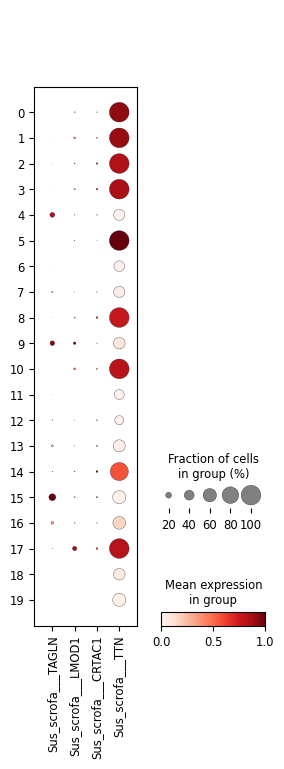

In [52]:
sc.pl.dotplot(
    dea_adata, 
    var_names=[

# 'Sus_scrofa___FN1', 
        'Sus_scrofa___TAGLN', 'Sus_scrofa___LMOD1', 
        'Sus_scrofa___CRTAC1', 
        'Sus_scrofa___TTN',
        # 'Sus_scrofa___CNN1', 
        # 'Sus_scrofa___PDGFRA', 'Sus_scrofa___ABCA8'
      
    ], 
    groupby='leiden_08', 
    standard_scale='var', 
    cmap='Reds', 
    standard_scale = 'var',
    use_raw = True

)
    

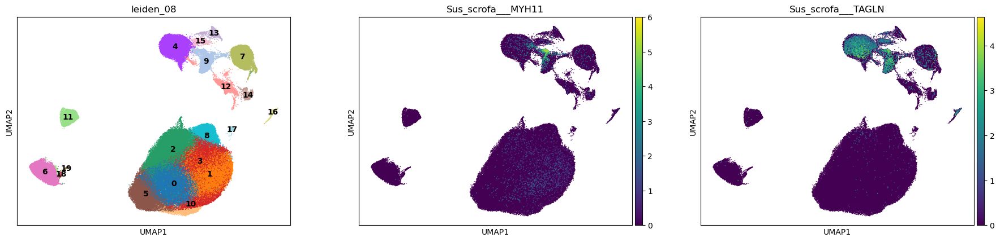

In [36]:

sc.pl.umap( dea_adata, color=[  "leiden_08", 'Sus_scrofa___MYH11' , 'Sus_scrofa___TAGLN' ],
            legend_loc="on data",  size=5)


In [39]:
dea_adata

AnnData object with n_obs × n_vars = 243733 × 4500
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp', 'percent_mito', 'percent_ribo', 'n_genes_by_counts', 'total_counts', 'n_counts', 'n_genes', 'n_counts_PCMV', 'n_genes_PCMV', 'PCMV_score', 'leiden_03', 'leiden_04', 'leiden_05', 'leiden_06', 'leiden_07', 'leiden_08', 'leiden_09'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'Condition_colors', 'Sample_ID_colors', 'hvg', 'leiden_03', 'leiden_03_colors', 'leiden_04', 'leiden_04_colors', 'leiden_05', 'leiden_0

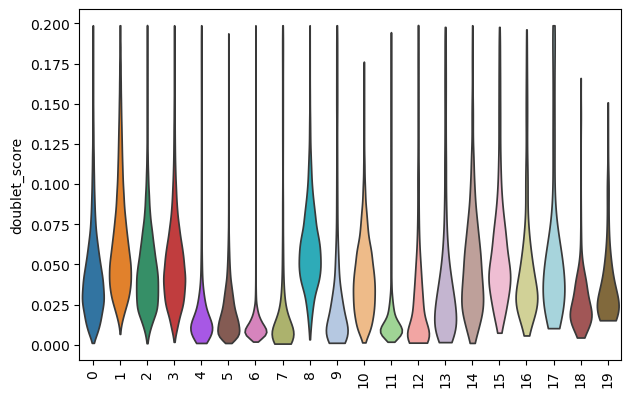

In [51]:
cluster_key = 'leiden_08'      

qc_vars = [
    # 'n_genes_by_counts',
    # 'total_counts', 
           # 'n_counts',
    # 'n_genes' , 
    # 'percent_mito', 
    # 'percent_ribo', 
    'doublet_score'
    # 'n_counts_Sus_scrofa',
    # 'n_counts_Papio_anubis'
]

sc.pl.violin(
    dea_adata,
    qc_vars,
    groupby=cluster_key,
    rotation=90,
    stripplot=False,
    multi_panel=True
)


# Annotation

In [15]:
import os
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
sc.settings.set_figure_params(dpi=300, dpi_save=300)
# 42 is for TrueType fonts (editable text in Illustrator)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

# ---------------------------
# PATHS
# ---------------------------
RESULTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results"
OBJECTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(OBJECTS_DIR, exist_ok=True)

sc.settings.figdir = RESULTS_DIR
sc.settings.autosave = False
sc.settings.set_figure_params(dpi=300)

# Load the object
# dea_adata = sc.read(os.path.join(OBJECTS_DIR, 'dea_adata_xeno_v1.h5ad'))

# ---------------------------
# ANNOTATION
# ---------------------------
cluster_annotation = {
    '0': 'CM',
    '1': 'CM',
    '2': 'CM',
    '3': 'CM',
    '4': 'FB',
    '5': 'CM',
    '6': 'Mye_papio',
    '7': 'EC',
    '8': 'CM',
    '9': 'MC',
    '10': 'CM',
    '11': 'Lymph_papio',
    '12': 'Mye_sus',
    '13': 'EC',
    '14': 'Lymph_sus',
    '15': 'EC',
    '16': 'NC',
    '17': 'Cycling',
    '18': 'Mye_papio',
    '19': 'EC_papio'
}

# Ensure cluster column is string
dea_adata.obs['leiden_08'] = dea_adata.obs['leiden_08'].astype(str)

# Map annotations
dea_adata.obs['cell_type'] = dea_adata.obs['leiden_08'].map(cluster_annotation)

# Safety check for unmapped cells
n_missing = dea_adata.obs['cell_type'].isna().sum()
print(f"cell_type missing (NaN) for {n_missing} cells")

if n_missing > 0:
    missing_clusters = sorted(
        dea_adata.obs.loc[
            dea_adata.obs['cell_type'].isna(), 'leiden_08'
        ].unique()
    )
    print(f"Unmapped cluster IDs: {missing_clusters}")

# ---------------------------
# REMOVE DOUBLETS (Conditional)
# ---------------------------
print(f"Original cell count: {dea_adata.n_obs}")
if 'doublet' in dea_adata.obs['cell_type'].values:
    dea_adata = dea_adata[dea_adata.obs['cell_type'] != 'doublet'].copy()
    print(f"Cleaned cell count (doublets removed): {dea_adata.n_obs}")
else:
    print("No doublets found to remove.")

# ---------------------------
# CATEGORICAL ORDERING
# ---------------------------
state_order = [
    'CM',
    'FB',
    'EC',
    'EC_papio',
    'MC',
    'Mye_papio',
    'Mye_sus',
    'Lymph_papio',
    'Lymph_sus',
    'NC',
    'Cycling'
]

present_states = [s for s in state_order if s in dea_adata.obs["cell_type"].unique()]

dea_adata.obs["cell_type"] = pd.Categorical(
    dea_adata.obs["cell_type"],
    categories=present_states,
    ordered=True
)

# ---------------------------
# CELL STATE COLORS
# ---------------------------
cell_state_colors = {
    # "CM":          "#4FBDBA",  # Vibrant/professional light greenish-blue
    # "FB":          "#FADA5E",  # Deep yellow
    # "EC":          "#5499C7",  # Blue
    # "EC_papio":    "#B0E0E6",  # Dark gray
    # "MC":          "#FF8C7A",  # Salmon
    # "Mye_papio":   "#D2691E",  # Deep orange
    # "Mye_sus":     "#C9A0DC",  # Light violet/purple
    # "Lymph_papio": "#FFCBA4",  # Light orange-ish peach
    # "Lymph_sus":   "#D6739B",  # Professional pink
    # "NC":          "#1B5E20",  # Dark green
    # "Cycling":     "#707070",  # Deep navy blue
    
        "CM":          "#4FBDBA",
    "FB":          "#FADA5E",
    "EC":          "#5499C7",
    "EC_papio":    "#B0E0E6",
    "MC":          "#FF8C7A",
    "Mye_papio":   "#94708E",
    "Mye_sus":     "#C9A0DC",
    "Lymph_papio": "#D2691E",
    "Lymph_sus":   "#FFCBA4",
    "NC":          "#1B5E20",
    "Cycling":     "#707070",
}

# Ensure categories align with color dictionary
dea_adata.uns["cell_type_colors"] = [
    cell_state_colors[s] for s in dea_adata.obs["cell_type"].cat.categories
]

# ---------------------------
# CONDITION COLORS
# ---------------------------
COND_PALETTE = {
    "Control": "#EFE48E",
    "3month-protocol": "skyblue",
    "6month-protocol": "#08528f",
    "Prematurely-terminated": "#C9B8D9",
    "PCMV/PRV": "#F0C096",
    "Rejection": "#E09E9E",
}

if "Condition" in dea_adata.obs.columns:
    dea_adata.obs["Condition"] = dea_adata.obs["Condition"].astype("category")
    cats = list(dea_adata.obs["Condition"].cat.categories)
    if all(c in COND_PALETTE for c in cats):
        dea_adata.uns["Condition_colors"] = [COND_PALETTE[c] for c in cats]
    else:
        missing = [c for c in cats if c not in COND_PALETTE]
        print(f"Warning: Condition categories not in COND_PALETTE: {missing}")

# ---------------------------
# PLOTS
# ---------------------------
plot_kwargs = dict(
    frameon=False,
    size=8,
    alpha=0.8,
    legend_loc="on data", 
    # legend_loc="right margin",
    legend_fontsize=9,
    legend_fontweight="bold",
)

with plt.rc_context({"figure.figsize": (7, 5)}):
    sc.pl.umap(
        dea_adata,
        color=["Condition", "cell_type"] if "Condition" in dea_adata.obs.columns else ["cell_type"],
        ncols=2,
        wspace=0.1,
        **plot_kwargs,
        save="_Annotated_Xeno_celltype_v1_UMAP.pdf",
        show=False
    )

# ---------------------------
# SAVE ANNOTATED OBJECT
# ---------------------------
out_h5ad = os.path.join(OBJECTS_DIR, "annotated_xeno_v1.h5ad")
dea_adata.write(out_h5ad)
print(f"\nSaved annotated object to: {out_h5ad}")

cell_type missing (NaN) for 0 cells
Original cell count: 243733
No doublets found to remove.


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)



Saved annotated object to: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/annotated_xeno_v1.h5ad


In [16]:
annotated_adata = sc.read ("/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/annotated_xeno_v1.h5ad")

In [17]:
annotated_adata

AnnData object with n_obs × n_vars = 243733 × 4500
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp', 'percent_mito', 'percent_ribo', 'n_genes_by_counts', 'total_counts', 'n_counts', 'n_genes', 'n_counts_PCMV', 'n_genes_PCMV', 'PCMV_score', 'leiden_03', 'leiden_04', 'leiden_05', 'leiden_06', 'leiden_07', 'leiden_08', 'leiden_09', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'Condition_colors', 'Sample_ID_colors', 'cell_type_colors', 'hvg', 'leiden_03', 'leiden_03_colors', 'leiden_04', 'leiden_0

# DEA annotated

In [17]:
annotated_adata = sc.read ("/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/annotated_xeno_v1.h5ad")

In [18]:

# Perform differential expressxion to find marker genes for each cluster using Wilcoxon test
sc.tl.rank_genes_groups(annotated_adata, 'cell_type', method='wilcoxon', key_added='wilcoxon', use_raw=True)

# Visualize the top marker genes for each cluster
sc.pl.rank_genes_groups(annotated_adata, key='wilcoxon', n_genes=30, sharey=False)

# Save the DE analysis to an H5AD file
annotated_adata.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/dea_annotated_global_xeno_v1.h5ad')


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [19]:
dea_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/dea_annotated_global_xeno_v1.h5ad')


In [20]:
%matplotlib inline

sc.pl.rank_genes_groups_dotplot(dea_adata, key="wilcoxon", n_genes=5, standard_scale="var"
                                # , cmap="coolwarm", vmin= -1
                               )


In [21]:
import pandas as pd
import os

de_key = 'wilcoxon' 
results = dea_adata.uns[de_key] # These are your clusters

output_dir = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/Annotated_DEGs"
os.makedirs(output_dir, exist_ok=True)

for clust in clusters:
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    # Optional: Sort by Wilcoxon score, descending (highest first)
    df = df.sort_values('score', ascending=False)
    # Save to CSV
    df.to_csv(f"{output_dir}/Cluster_{clust}_DEGs.csv", index=False)



In [22]:
import os
import pandas as pd

# 1. Setup paths
base_results_dir = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/Annotated_DEGs"
sig_output_dir = os.path.join(base_results_dir, "significant_DEGs")
os.makedirs(sig_output_dir, exist_ok=True)

# 2. Thresholds
P_ADJ_CUTOFF = 0.05
LFC_CUTOFF = 0.5

print(f"Filtering DEGs: pval_adj < {P_ADJ_CUTOFF} and |logfoldchange| > {LFC_CUTOFF}")

# 3. Process each cluster's results from your previous loop
# Using the 'clusters' variable from your previous code block
for clust in clusters:
    # Extract data from the scanpy results object
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    # Create the DataFrame
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    
    # 4. Apply strict filtering
    # Filtering for p-adj AND (|LFC| > 0.75)
    sig_df = df[
        (df['pval_adj'] < P_ADJ_CUTOFF) & 
        ((df['logfoldchange'] > LFC_CUTOFF) | (df['logfoldchange'] < -LFC_CUTOFF))
    ].copy()
    
    # Sort by logfoldchange descending
    sig_df = sig_df.sort_values('logfoldchange', ascending=False)
    
    # 5. Save if there are significant genes found
    if not sig_df.empty:
        output_file = f"{sig_output_dir}/Significant_Cluster_{clust}_DEGs.csv"
        sig_df.to_csv(output_file, index=False)
        print(f"  Cluster {clust}: Saved {len(sig_df)} significant DEGs.")
    else:
        print(f"  Cluster {clust}: No genes met the significance criteria.")

print("\nAll significant files saved in:", sig_output_dir)

Filtering DEGs: pval_adj < 0.05 and |logfoldchange| > 0.5
  Cluster CM: Saved 13667 significant DEGs.
  Cluster FB: Saved 8107 significant DEGs.
  Cluster EC: Saved 6884 significant DEGs.
  Cluster EC_papio: Saved 6841 significant DEGs.
  Cluster MC: Saved 4881 significant DEGs.
  Cluster Mye_papio: Saved 17901 significant DEGs.
  Cluster Mye_sus: Saved 5200 significant DEGs.
  Cluster Lymph_papio: Saved 14443 significant DEGs.
  Cluster Lymph_sus: Saved 2788 significant DEGs.
  Cluster NC: Saved 2387 significant DEGs.
  Cluster Cycling: Saved 3620 significant DEGs.

All significant files saved in: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/Annotated_DEGs/significant_DEGs


# Composition

In [23]:
annotated_adata = sc.read ("/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/annotated_xeno_v1.h5ad")

In [24]:
annotated_adata

AnnData object with n_obs × n_vars = 243733 × 4500
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp', 'percent_mito', 'percent_ribo', 'n_genes_by_counts', 'total_counts', 'n_counts', 'n_genes', 'n_counts_PCMV', 'n_genes_PCMV', 'PCMV_score', 'leiden_03', 'leiden_04', 'leiden_05', 'leiden_06', 'leiden_07', 'leiden_08', 'leiden_09', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'Condition_colors', 'Sample_ID_colors', 'cell_type_colors', 'hvg', 'leiden_03', 'leiden_03_colors', 'leiden_04', 'leiden_0

In [25]:
def stacked_barplot(adata, xaxis, stack, xaxis_label, legend_label, shift_top=0.2, xaxis_rotation=45, figsize=(10,10), percent=True):
    tmp=pd.crosstab(adata.obs[xaxis],
                adata.obs[stack]).sum(axis=1)
    
    ax= pd.crosstab(adata.obs[xaxis], 
                    adata.obs[stack]).apply(lambda r: r/r.sum()*100, axis=1)
    #ax_1 = ax.plot.bar(figsize=(10,10),stacked=True, rot=0, colors=colors)
    ax_1 = ax.plot.bar(figsize=figsize,stacked=True, rot=0)
    #display(ax)
    #plt.legend(title="Subject") # loc='upper center', bbox_to_anchor=(0.1, 1.0), 
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), title=legend_label)
    plt.xlabel(xaxis_label,fontweight="bold")
    plt.ylabel('Percent Distribution',fontweight="bold")
    
    if percent:
        for rec in ax_1.patches:
            height = rec.get_height()
            ax_1.text(rec.get_x() + rec.get_width() / 2, rec.get_y() + height/2, "{:.0f}%".format(height),
                   ha = 'center', va='center', fontsize=14.5, weight='bold') #
    
    for xaxistick in range(ax.shape[0]):
        ax_1.text(xaxistick-shift_top,110,tmp[xaxistick],va='center', rotation=45, fontsize=14.5, weight='bold')
    
    plt.xticks(rotation=xaxis_rotation)
    
    ax_1.grid(False)
    plt.show()

/tmp/ipykernel_1705173/757559510.py:22: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax_1.text(xaxistick-shift_top,110,tmp[xaxistick],va='center', rotation=45, fontsize=14.5, weight='bold')


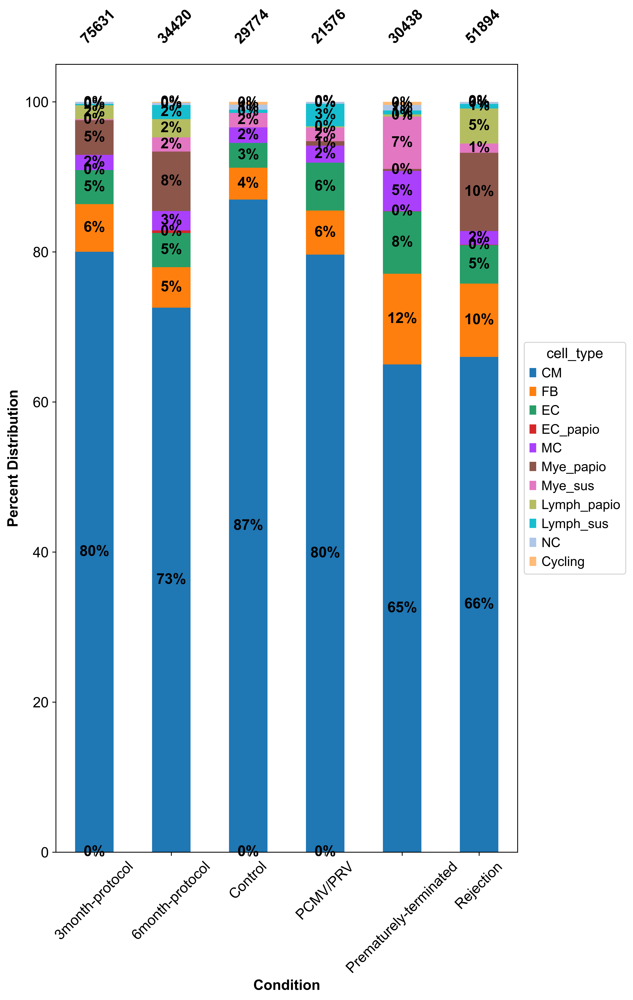

In [26]:
stacked_barplot(dea_adata, 'Condition', 'cell_type', 
                'Condition', 'cell_type', 
                shift_top=0.2, xaxis_rotation=45, 
                figsize=(8,14), percent=True)

In [27]:
stacked_barplot(annotated_adata, 'Sample_ID', 'cell_type', 
                'Sample_ID', 'cell_type', 
                shift_top=0.2, xaxis_rotation=45, 
                figsize=(18,12), percent=True)

/tmp/ipykernel_1705173/757559510.py:22: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax_1.text(xaxistick-shift_top,110,tmp[xaxistick],va='center', rotation=45, fontsize=14.5, weight='bold')


# Label transfer

In [28]:
post_qc_adata = sc.read('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/Post_QC_filtered_adata_v1.h5ad')

In [29]:
post_qc_adata

AnnData object with n_obs × n_vars = 243733 × 53826
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp', 'percent_mito', 'percent_ribo', 'n_genes_by_counts', 'total_counts', 'n_counts', 'n_genes', 'n_counts_PCMV', 'n_genes_PCMV', 'PCMV_score'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [30]:
annotated_adata = sc.read ("/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/annotated_xeno_v1.h5ad")

In [31]:
annotated_adata

AnnData object with n_obs × n_vars = 243733 × 4500
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp', 'percent_mito', 'percent_ribo', 'n_genes_by_counts', 'total_counts', 'n_counts', 'n_genes', 'n_counts_PCMV', 'n_genes_PCMV', 'PCMV_score', 'leiden_03', 'leiden_04', 'leiden_05', 'leiden_06', 'leiden_07', 'leiden_08', 'leiden_09', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'Condition_colors', 'Sample_ID_colors', 'cell_type_colors', 'hvg', 'leiden_03', 'leiden_03_colors', 'leiden_04', 'leiden_0

In [3]:
import scanpy as sc

# 1. Define paths
# raw_path = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/Post_QC_filtered_adata_v1.h5ad"
# annotated_path = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/annotated_xeno_v1.h5ad"
output_path = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/rawraw_annotated_xeno_v1.h5ad"

# # 2. Load objects
# print("Loading objects...")
# post_qc_adata = sc.read_h5ad(raw_path)
# annotated_adata = sc.read_h5ad(annotated_path)

# 3. Ensure strict alignment of cell barcodes before matrix transfer
if not (post_qc_adata.obs_names == annotated_adata.obs_names).all():
    print("Aligning annotated object indices to match raw object...")
    annotated_adata = annotated_adata[post_qc_adata.obs_names].copy()

# 4. Transfer .obs (Pandas handles index alignment naturally, but the above step guarantees it)
print("Transferring .obs metadata...")
post_qc_adata.obs['cell_type'] = annotated_adata.obs['cell_type'].copy()

# 5. Transfer .obsm embeddings
print("Transferring .obsm embeddings...")
post_qc_adata.obsm['X_pca_harmony'] = annotated_adata.obsm['X_pca_harmony'].copy()
post_qc_adata.obsm['X_umap'] = annotated_adata.obsm['X_umap'].copy()

# 6. Transfer .uns colors
# Using .get() ensures it won't throw a KeyError if a color palette happens to be missing
print("Transferring .uns color dictionaries...")
color_keys = ['Condition_colors', 'Sample_ID_colors', 'cell_type_colors']

for key in color_keys:
    if key in annotated_adata.uns:
        post_qc_adata.uns[key] = annotated_adata.uns[key].copy()
    else:
        print(f"Warning: {key} not found in annotated_adata.uns")

# 7. Save the final rawraw annotated object
print(f"Saving raw annotated object to:\n{output_path}")
post_qc_adata.write_h5ad(output_path)
print("Done!")

In [5]:
raw_annotated_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/rawraw_annotated_xeno_v1.h5ad')

In [6]:
raw_annotated_adata

AnnData object with n_obs × n_vars = 243733 × 53826
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp', 'percent_mito', 'percent_ribo', 'n_genes_by_counts', 'total_counts', 'n_counts', 'n_genes', 'n_counts_PCMV', 'n_genes_PCMV', 'PCMV_score', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'Condition_colors', 'Sample_ID_colors', 'cell_type_colors'
    obsm: 'X_pca_harmony', 'X_umap'

# Flipping X,Y-axis

In [44]:
raw_annotated_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/rawraw_annotated_xeno_v1.h5ad')

In [55]:
sc.settings.set_figure_params(dpi=300, dpi_save=300)

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

import os
import scanpy as sc
import matplotlib.pyplot as plt

# 1. Set the correct figure directory to the new repository
fig_dir = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results'
os.makedirs(fig_dir, exist_ok=True)
sc.settings.figdir = fig_dir

# 2. Copy the original UMAP coordinates
coords = raw_annotated_adata.obsm['X_umap'].copy()

# ====================================================================
# 3. CHOOSE YOUR MIRRORING DIRECTION
# ====================================================================

# Option A: Mirror Vertically (Flip Y-axis only)
# coords[:, 1] = coords[:, 1] * -1

# Option B: Mirror Horizontally (Flip X-axis only)
# coords[:, 0] = coords[:, 0] * -1

# Option C: Mirror Both (Flip X and Y)
coords[:, 0] = coords[:, 0] * -1
coords[:, 1] = coords[:, 1] * -1

# ====================================================================

# Store the mirrored coordinates
raw_annotated_adata.obsm['X_umap_mirrored'] = coords

# 4. Define your specific plot parameters
plot_kwargs = {
    "size": 15,
    "legend_loc": "right margin",
    "frameon": False
}

# 5. Plot and save using your template 
# Note: sc.pl.embedding is used to prevent the 'multiple basis' error, but functions identically to sc.pl.umap
with plt.rc_context({"figure.figsize": (6, 5)}):
    sc.pl.embedding(
        raw_annotated_adata,
        basis="umap_mirrored",
        color=["Condition", "cell_type"] if "Condition" in raw_annotated_adata.obs.columns else ["cell_type"],
        ncols=2,
        wspace=0.3,
        **plot_kwargs,
        save="_Annotated_Xeno_celltype_v1_UMAP.pdf",
        show=False
    )

print(f"✓ Mirrored UMAP saved correctly using template to {fig_dir}")

✓ Mirrored UMAP saved correctly using template to /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results


# Composition boxplots

In [33]:
"""
=============================================================================
COMPOSITIONAL ANALYSIS
=============================================================================
Statistical design:
  - Mann-Whitney U test (two-sided) for each cell type x pair combination (The mann whitney FDR values wont be used, they will be replaced with CLR values, this is for cross-checking)
  - BH FDR correction applied WITHIN each pairwise comparison family
    across all cell types.
  - Only specific pairs tested: vs Control and vs 3month-protocol
  - Only pairs with FDR < 0.05 are annotated on the plot
=============================================================================
"""

import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import scanpy as sc
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# --- Adobe Illustrator-compatible fonts ---
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype']  = 42
matplotlib.rcParams['font.family']      = 'sans-serif'
matplotlib.rcParams['font.sans-serif']  = ['Arial']

# =============================================================================
# 0. PATHS & DATA
# =============================================================================
RESULTS_DIR = (
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/"
    "analysis/v1/celltype_annotation/results/composition"
)
os.makedirs(RESULTS_DIR, exist_ok=True)

# Load your newly created rawraw object containing the transferred annotations
annotated_adata = sc.read(
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/"
    "analysis/v1/celltype_annotation/objects/rawraw_annotated_xeno_v1.h5ad"
)

# =============================================================================
# 1. ORDERS, COLORS & EXPLICIT PAIRS
# =============================================================================
COND_ORDER = [
    "Control",
    "Prematurely-terminated",
    "3month-protocol",
    "6month-protocol",
    "PCMV/PRV",
    "Rejection",
]

COND_COLORS = {
    "Control": "#EFE48E",
    "3month-protocol": "skyblue",
    "6month-protocol": "#08528f",
    "Prematurely-terminated": "#C9B8D9",
    "PCMV/PRV": "#F0C096",
    "Rejection": "#E09E9E",
}

# Dynamically extract cell types from the object
if annotated_adata.obs["cell_type"].dtype.name == "category":
    CELL_TYPE_ORDER = list(annotated_adata.obs["cell_type"].cat.categories)
else:
    CELL_TYPE_ORDER = sorted(annotated_adata.obs["cell_type"].unique().tolist())

# Explicitly define the custom testing pairs
# Format: (Baseline/Denominator, Experimental/Numerator)
ALL_PAIRS = [
    # Versus Control
    ("Control", "3month-protocol"),
    ("Control", "6month-protocol"),
    ("Control", "Prematurely-terminated"),
    ("Control", "PCMV/PRV"),
    ("Control", "Rejection"),
    # Versus 3month-protocol
    ("3month-protocol", "6month-protocol"),
    ("3month-protocol", "Prematurely-terminated"),
    ("3month-protocol", "PCMV/PRV"),
    ("3month-protocol", "Rejection")
]

# =============================================================================
# 2. COMPUTE PER-SAMPLE PROPORTIONS
# =============================================================================
df_obs = annotated_adata.obs.copy().reset_index()
df_obs["Condition"] = df_obs["Condition"].astype(str)
df_obs["cell_type"] = df_obs["cell_type"].astype(str)

counts = (
    df_obs
    .groupby(["Sample_ID", "cell_type", "Condition"], observed=False)
    .size()
    .reset_index(name="count")
)
totals = (
    df_obs
    .groupby(["Sample_ID", "Condition"], observed=False)
    .size()
    .reset_index(name="total")
)

prop_df = counts.merge(totals, on=["Sample_ID", "Condition"], how="left")
prop_df["proportion"] = (prop_df["count"] / prop_df["total"]) * 100

prop_df["Condition"] = pd.Categorical(
    prop_df["Condition"], categories=COND_ORDER, ordered=True
)
prop_df["cell_type"] = pd.Categorical(
    prop_df["cell_type"], categories=CELL_TYPE_ORDER, ordered=True
)

# =============================================================================
# 3. STATISTICS
#    Outer loop = comparison pairs
#    Inner loop = cell types
#    BH-FDR applied within each pair across all cell types
# =============================================================================
raw_rows = []

for (c1, c2) in ALL_PAIRS:
    pair_rows = []

    for ct in CELL_TYPE_ORDER:
        ct_data = prop_df[prop_df["cell_type"] == ct]

        v1 = ct_data[ct_data["Condition"] == c1]["proportion"].dropna().values
        v2 = ct_data[ct_data["Condition"] == c2]["proportion"].dropna().values

        mean1   = np.mean(v1)   if len(v1) > 0 else np.nan
        mean2   = np.mean(v2)   if len(v2) > 0 else np.nan
        median1 = np.median(v1) if len(v1) > 0 else np.nan
        median2 = np.median(v2) if len(v2) > 0 else np.nan

        # log2FC: c2 relative to c1  (positive = higher in c2)
        if mean1 > 0 and mean2 > 0:
            lfc = np.log2(mean2 / mean1)
            fc  = mean2 / mean1
        elif mean1 == 0 and mean2 > 0:
            lfc, fc = np.inf, np.inf
        elif mean1 > 0 and mean2 == 0:
            lfc, fc = -np.inf, 0.0
        else:
            lfc, fc = np.nan, np.nan

        if len(v1) >= 2 and len(v2) >= 2:
            _, pval = mannwhitneyu(v1, v2, alternative="two-sided")
        else:
            pval = np.nan

        pair_rows.append({
            "cell_type":     ct,
            "group1":        c1,
            "group2":        c2,
            "comparison":    f"{c2}_vs_{c1}",
            "fdr_family":    f"{c2}_vs_{c1}",
            "mean_group1":   mean1,
            "mean_group2":   mean2,
            "median_group1": median1,
            "median_group2": median2,
            "fold_change":   fc,
            "log2FC":        lfc,
            "p_val":         pval,
        })

    # --- BH correction across all cell types for this pair ---
    pvals_arr  = np.array([r["p_val"] for r in pair_rows], dtype=float)
    valid_mask = ~np.isnan(pvals_arr)
    fdr_arr    = np.full(len(pvals_arr), np.nan)
    
    if valid_mask.sum() > 0:
        _, fdr_valid, _, _ = multipletests(
            pvals_arr[valid_mask], method="fdr_bh"
        )
        fdr_arr[valid_mask] = fdr_valid

    for i, row in enumerate(pair_rows):
        row["fdr_adj_p_val"] = fdr_arr[i]

    raw_rows.extend(pair_rows)

stats_df = pd.DataFrame(raw_rows)

def get_stars(p):
    if pd.isna(p):  return ""
    if p < 0.001:   return "***"
    if p < 0.01:    return "**"
    if p < 0.05:    return "*"
    return ""

stats_df["significance"] = stats_df["fdr_adj_p_val"].apply(get_stars)

# =============================================================================
# 4. SAVE STATISTICS CSV
# =============================================================================
csv_cols = [
    "cell_type", "comparison", "fdr_family", "group1", "group2",
    "mean_group1", "mean_group2", "median_group1", "median_group2",
    "fold_change", "log2FC", "p_val", "fdr_adj_p_val", "significance"
]
out_csv = os.path.join(RESULTS_DIR, "Compositional_Stats_CellTypes_PerPairFDR.csv")
(
    stats_df[csv_cols]
    .sort_values(["comparison", "fdr_adj_p_val"])
    .to_csv(out_csv, index=False, float_format="%.6g")
)
print(f"Stats CSV saved -> {out_csv}")

# =============================================================================
# 5. PLOT
# =============================================================================
sns.set_style("white")

N_COND  = len(COND_ORDER)
N_STATE = len(CELL_TYPE_ORDER)

# ── layout constants ──────────────────────────────────────────────────────────
BOX_WIDTH  = 0.82    
# Scale figure width dynamically based on number of cell types to prevent crowding
FIG_WIDTH  = max(22, N_STATE * 1.5) 
FIG_HEIGHT = 10

X_PAD_LEFT  = 0.52   
X_PAD_RIGHT = 0.52   

# ── whisker geometry ──────────────────────────────────────────────────────────
Y_START_ABOVE_DATA = 2.5   
Y_STEP             = 3.2   
BRACKET_H          = 0.9   
STAR_OFFSET        = 0.3   

# =============================================================================
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))

ax.grid(False)
ax.xaxis.grid(False)
ax.yaxis.grid(False)

# ── boxplot ───────────────────────────────────────────────────────────────────
sns.boxplot(
    data=prop_df,
    x="cell_type", y="proportion",
    hue="Condition",
    order=CELL_TYPE_ORDER,
    hue_order=COND_ORDER,
    palette=COND_COLORS,
    showfliers=False,
    linewidth=1.2,
    width=BOX_WIDTH,
    ax=ax,
)

# ── strip / dot overlay ───────────────────────────────────────────────────────
sns.stripplot(
    data=prop_df,
    x="cell_type", y="proportion",
    hue="Condition",
    order=CELL_TYPE_ORDER,
    hue_order=COND_ORDER,
    dodge=True,
    jitter=0.12,
    palette=COND_COLORS,
    alpha=0.6,
    edgecolor="black",
    linewidth=0.5,
    size=4,
    legend=False,
    ax=ax,
)

# =============================================================================
# 5b. SIGNIFICANCE WHISKERS  (staggered, non-overlapping)
# =============================================================================
def box_x(ct_idx, cond_name):
    """
    Return the x-axis centre of one dodged box.
    """
    k      = COND_ORDER.index(cond_name)
    offset = (k - (N_COND - 1) / 2.0) * (BOX_WIDTH / N_COND)
    return ct_idx + offset

for ct_idx, ct in enumerate(CELL_TYPE_ORDER):
    # Collect significant pairs for this cell type, best FDR first
    sig_pairs = (
        stats_df[
            (stats_df["cell_type"]   == ct) &
            (stats_df["significance"] != "")
        ]
        .sort_values("fdr_adj_p_val")
    )

    if sig_pairs.empty:
        continue

    max_val = prop_df[prop_df["cell_type"] == ct]["proportion"].max()
    if pd.isna(max_val):
        max_val = 0.0

    base_y = max_val + Y_START_ABOVE_DATA

    for layer, (_, row) in enumerate(sig_pairs.iterrows()):
        y_bar = base_y + layer * Y_STEP
        x1    = box_x(ct_idx, row["group1"])
        x2    = box_x(ct_idx, row["group2"])

        if x1 > x2:               # always draw left to right
            x1, x2 = x2, x1

        ax.plot(
            [x1, x1, x2, x2],
            [y_bar, y_bar + BRACKET_H, y_bar + BRACKET_H, y_bar],
            color="black", lw=1.1, clip_on=False
        )
        
        ax.text(
            (x1 + x2) / 2,
            y_bar + BRACKET_H + STAR_OFFSET,
            row["significance"],
            ha="center", va="bottom",
            fontsize=9, fontweight="bold", color="black",
            clip_on=False
        )

# =============================================================================
# 6. AXES, FRAME & FORMATTING
# =============================================================================
ax.set_xlim(-X_PAD_LEFT, N_STATE - 1 + X_PAD_RIGHT)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.0)
    spine.set_color("black")

ax.set_xlabel("Cell Type", fontsize=13, fontweight="bold", labelpad=10)
ax.set_ylabel("Proportion of Total Cells (%)", fontsize=13, fontweight="bold", labelpad=10)
ax.set_title(
    "Cell Type Composition Across Conditions (Xenotransplant Cohort)",
    fontsize=15, fontweight="bold", pad=18
)

ax.tick_params(axis="x", rotation=45, labelsize=11) # Rotated to 45 to fit potentially long cell type names
ax.tick_params(axis="y", labelsize=11)
for tick in ax.get_xticklabels():
    tick.set_fontweight("bold")
    tick.set_ha("right") 
for tick in ax.get_yticklabels():
    tick.set_fontweight("bold")

handles = [
    mpatches.Patch(
        facecolor=COND_COLORS[c], edgecolor="black", linewidth=0.8, label=c
    )
    for c in COND_ORDER
]
ax.legend(
    handles=handles,
    title="Condition",
    title_fontsize=11,
    fontsize=10,
    loc="upper right",
    frameon=True,
    framealpha=0.85,
    edgecolor="black",
)

plt.tight_layout()

# =============================================================================
# 7. SAVE
# =============================================================================
out_pdf = os.path.join(RESULTS_DIR, "Compositional_CellTypes_PerPairFDR_final.pdf")
out_png = os.path.join(RESULTS_DIR, "Compositional_CellTypes_PerPairFDR_final.png")
plt.savefig(out_pdf, dpi=300, bbox_inches="tight")
plt.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()

print(f"\nPlot  -> {out_pdf}")
print(f"       -> {out_png}")
print(f"Stats -> {out_csv}")

# =============================================================================
# 8. SIGNIFICANT HITS SUMMARY (console)
# =============================================================================
sig_summary = (
    stats_df[stats_df["significance"] != ""][
        ["cell_type", "comparison", "mean_group1", "mean_group2",
         "log2FC", "p_val", "fdr_adj_p_val", "significance"]
    ]
    .sort_values(["cell_type", "fdr_adj_p_val"])
)

print(
    f"\n=== Significant pairs — per-pair BH-FDR (FDR < 0.05) "
    f"| n = {len(sig_summary)} ==="
)
print(sig_summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Stats CSV saved -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/composition/Compositional_Stats_CellTypes_PerPairFDR.csv



Plot  -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/composition/Compositional_CellTypes_PerPairFDR_final.pdf
       -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/composition/Compositional_CellTypes_PerPairFDR_final.png
Stats -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/composition/Compositional_Stats_CellTypes_PerPairFDR.csv

=== Significant pairs — per-pair BH-FDR (FDR < 0.05) | n = 12 ===
  cell_type                                comparison  mean_group1  mean_group2  log2FC  p_val  fdr_adj_p_val significance
         CM Prematurely-terminated_vs_3month-protocol      78.8799      64.7637 -0.2845 0.0167         0.0306            *
    Cycling Prematurely-terminated_vs_3month-protocol       0.0000       0.3970     inf 0.0050         0.0306            *
Lymph_papio                3month-protocol_vs_Control       0.0000 

In [34]:
"""
=============================================================================
COMPOSITIONAL ANALYSIS — snRNA-seq | Xenotransplant Cohort (Cell Types)
FDR STRATEGY: Per comparison family
LAYOUT: One subplot per cell_type, independent y-axis scaling
COMPARISONS: Only vs 3month-protocol (reference condition)
=============================================================================
Statistical design:
  - Mann-Whitney U test (two-sided) for each cell type x pair combination
  - BH FDR correction applied WITHIN each pairwise comparison family
    across all cell types.
  - Only pairs vs 3month-protocol are tested
  - Only pairs with FDR < 0.05 are annotated on the plot
=============================================================================
"""

import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import scanpy as sc
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# --- Adobe Illustrator-compatible fonts ---
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype']  = 42
matplotlib.rcParams['font.family']      = 'sans-serif'
matplotlib.rcParams['font.sans-serif']  = ['Arial']

# =============================================================================
# 0. PATHS & DATA
# =============================================================================
RESULTS_DIR = (
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/"
    "analysis/v1/celltype_annotation/results/composition"
)
os.makedirs(RESULTS_DIR, exist_ok=True)

annotated_adata = sc.read(
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/"
    "analysis/v1/celltype_annotation/objects/rawraw_annotated_xeno_v1.h5ad"
)

# =============================================================================
# 1. ORDERS, COLORS & EXPLICIT PAIRS
# =============================================================================
COND_ORDER = [
    "Control",
    "Prematurely-terminated",
    "3month-protocol",
    "6month-protocol",
    "PCMV/PRV",
    "Rejection",
]

COND_COLORS = {
    "Control": "#EFE48E",
    "3month-protocol": "skyblue",
    "6month-protocol": "#08528f",
    "Prematurely-terminated": "#C9B8D9",
    "PCMV/PRV": "#F0C096",
    "Rejection": "#E09E9E",
}

if annotated_adata.obs["cell_type"].dtype.name == "category":
    CELL_TYPE_ORDER = list(annotated_adata.obs["cell_type"].cat.categories)
else:
    CELL_TYPE_ORDER = sorted(annotated_adata.obs["cell_type"].unique().tolist())

# Only comparisons vs 3month-protocol (the reference condition)
REFERENCE_COND = "3month-protocol"
ALL_PAIRS = [
    (REFERENCE_COND, c) for c in COND_ORDER if c != REFERENCE_COND
]

# =============================================================================
# 2. COMPUTE PER-SAMPLE PROPORTIONS
# =============================================================================
df_obs = annotated_adata.obs.copy().reset_index()
df_obs["Condition"] = df_obs["Condition"].astype(str)
df_obs["cell_type"] = df_obs["cell_type"].astype(str)

counts = (
    df_obs
    .groupby(["Sample_ID", "cell_type", "Condition"], observed=False)
    .size()
    .reset_index(name="count")
)
totals = (
    df_obs
    .groupby(["Sample_ID", "Condition"], observed=False)
    .size()
    .reset_index(name="total")
)

prop_df = counts.merge(totals, on=["Sample_ID", "Condition"], how="left")
prop_df["proportion"] = (prop_df["count"] / prop_df["total"]) * 100

prop_df["Condition"] = pd.Categorical(
    prop_df["Condition"], categories=COND_ORDER, ordered=True
)
prop_df["cell_type"] = pd.Categorical(
    prop_df["cell_type"], categories=CELL_TYPE_ORDER, ordered=True
)

# =============================================================================
# 3. STATISTICS
#    Outer loop = comparison pairs (all vs 3month-protocol)
#    Inner loop = cell types
#    BH-FDR applied within each pair across all cell types
# =============================================================================
raw_rows = []

for (c1, c2) in ALL_PAIRS:
    pair_rows = []

    for ct in CELL_TYPE_ORDER:
        ct_data = prop_df[prop_df["cell_type"] == ct]

        v1 = ct_data[ct_data["Condition"] == c1]["proportion"].dropna().values
        v2 = ct_data[ct_data["Condition"] == c2]["proportion"].dropna().values

        mean1   = np.mean(v1)   if len(v1) > 0 else np.nan
        mean2   = np.mean(v2)   if len(v2) > 0 else np.nan
        median1 = np.median(v1) if len(v1) > 0 else np.nan
        median2 = np.median(v2) if len(v2) > 0 else np.nan

        if mean1 > 0 and mean2 > 0:
            lfc = np.log2(mean2 / mean1)
            fc  = mean2 / mean1
        elif mean1 == 0 and mean2 > 0:
            lfc, fc = np.inf, np.inf
        elif mean1 > 0 and mean2 == 0:
            lfc, fc = -np.inf, 0.0
        else:
            lfc, fc = np.nan, np.nan

        if len(v1) >= 2 and len(v2) >= 2:
            _, pval = mannwhitneyu(v1, v2, alternative="two-sided")
        else:
            pval = np.nan

        pair_rows.append({
            "cell_type":     ct,
            "group1":        c1,
            "group2":        c2,
            "comparison":    f"{c2}_vs_{c1}",
            "fdr_family":    f"{c2}_vs_{c1}",
            "mean_group1":   mean1,
            "mean_group2":   mean2,
            "median_group1": median1,
            "median_group2": median2,
            "fold_change":   fc,
            "log2FC":        lfc,
            "p_val":         pval,
        })

    # --- BH correction across all cell types for this pair ---
    pvals_arr  = np.array([r["p_val"] for r in pair_rows], dtype=float)
    valid_mask = ~np.isnan(pvals_arr)
    fdr_arr    = np.full(len(pvals_arr), np.nan)

    if valid_mask.sum() > 0:
        _, fdr_valid, _, _ = multipletests(
            pvals_arr[valid_mask], method="fdr_bh"
        )
        fdr_arr[valid_mask] = fdr_valid

    for i, row in enumerate(pair_rows):
        row["fdr_adj_p_val"] = fdr_arr[i]

    raw_rows.extend(pair_rows)

stats_df = pd.DataFrame(raw_rows)

def get_stars(p):
    if pd.isna(p):  return ""
    if p < 0.001:   return "***"
    if p < 0.01:    return "**"
    if p < 0.05:    return "*"
    return ""

stats_df["significance"] = stats_df["fdr_adj_p_val"].apply(get_stars)

# =============================================================================
# 4. SAVE STATISTICS CSV
# =============================================================================
csv_cols = [
    "cell_type", "comparison", "fdr_family", "group1", "group2",
    "mean_group1", "mean_group2", "median_group1", "median_group2",
    "fold_change", "log2FC", "p_val", "fdr_adj_p_val", "significance"
]
out_csv = os.path.join(RESULTS_DIR, "Compositional_Stats_CellTypes_vs3month_PerPairFDR.csv")
(
    stats_df[csv_cols]
    .sort_values(["comparison", "fdr_adj_p_val"])
    .to_csv(out_csv, index=False, float_format="%.6g")
)
print(f"Stats CSV saved -> {out_csv}")

# =============================================================================
# 5. PLOT — ONE SUBPLOT PER CELL TYPE (grid layout, independent y-axis)
# =============================================================================
sns.set_style("white")

N_STATE = len(CELL_TYPE_ORDER)

# Grid layout: wrap to multiple rows, max 4 columns
N_COLS = min(4, N_STATE)
N_ROWS = int(np.ceil(N_STATE / N_COLS))

SUBPLOT_W = 4.2
SUBPLOT_H = 4.6

fig, axes = plt.subplots(
    N_ROWS, N_COLS,
    figsize=(SUBPLOT_W * N_COLS, SUBPLOT_H * N_ROWS),
    squeeze=False
)
axes_flat = axes.flatten()

# Per-pair x positions within each single-cell-type panel
# Only conditions actually compared (3month-protocol + everything else) are shown
PANEL_CONDS = COND_ORDER  # keep full condition order on x-axis of each panel
N_COND = len(PANEL_CONDS)

Y_START_ABOVE_DATA = 0.06   # fraction of panel's data range
Y_STEP             = 0.09
BRACKET_H_FRAC     = 0.02
STAR_OFFSET_FRAC   = 0.01

for idx, ct in enumerate(CELL_TYPE_ORDER):
    ax = axes_flat[idx]
    ct_data = prop_df[prop_df["cell_type"] == ct]

    sns.boxplot(
        data=ct_data,
        x="Condition", y="proportion",
        order=PANEL_CONDS,
        palette=COND_COLORS,
        showfliers=False,
        linewidth=1.1,
        width=0.7,
        ax=ax,
    )
    sns.stripplot(
        data=ct_data,
        x="Condition", y="proportion",
        order=PANEL_CONDS,
        palette=COND_COLORS,
        jitter=0.12,
        alpha=0.6,
        edgecolor="black",
        linewidth=0.5,
        size=4,
        ax=ax,
    )

    ax.grid(False)
    ax.set_title(ct, fontsize=12, fontweight="bold", pad=8)
    ax.set_xlabel("")
    ax.set_ylabel("Proportion (%)", fontsize=10, fontweight="bold")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")
        tick.set_ha("right")

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.9)
        spine.set_color("black")

    # --- significance brackets, only vs 3month-protocol pairs for this cell type ---
    sig_pairs = (
        stats_df[
            (stats_df["cell_type"] == ct) &
            (stats_df["significance"] != "")
        ]
        .sort_values("fdr_adj_p_val")
    )

    if sig_pairs.empty:
        # still set a sensible y-limit with headroom
        max_val = ct_data["proportion"].max()
        if pd.isna(max_val):
            max_val = 1.0
        ax.set_ylim(0, max_val * 1.15)
        continue

    max_val = ct_data["proportion"].max()
    if pd.isna(max_val):
        max_val = 1.0

    data_range = max_val if max_val > 0 else 1.0
    base_y = max_val + Y_START_ABOVE_DATA * data_range
    n_layers = len(sig_pairs)
    top_y = base_y + (n_layers - 1) * Y_STEP * data_range + BRACKET_H_FRAC * data_range + STAR_OFFSET_FRAC * data_range

    # set per-panel y-limit with enough headroom for all brackets
    ax.set_ylim(0, top_y * 1.08)

    for layer, (_, row) in enumerate(sig_pairs.iterrows()):
        y_bar = base_y + layer * Y_STEP * data_range
        bracket_h = BRACKET_H_FRAC * data_range
        star_offset = STAR_OFFSET_FRAC * data_range

        x1 = PANEL_CONDS.index(row["group1"])
        x2 = PANEL_CONDS.index(row["group2"])
        if x1 > x2:
            x1, x2 = x2, x1

        ax.plot(
            [x1, x1, x2, x2],
            [y_bar, y_bar + bracket_h, y_bar + bracket_h, y_bar],
            color="black", lw=1.0, clip_on=False
        )
        ax.text(
            (x1 + x2) / 2,
            y_bar + bracket_h + star_offset,
            row["significance"],
            ha="center", va="bottom",
            fontsize=8, fontweight="bold", color="black",
            clip_on=False
        )

# Hide unused panels if grid has empty slots
for j in range(N_STATE, len(axes_flat)):
    axes_flat[j].axis("off")

fig.suptitle(
    "Cell Type Composition vs. 3-month Protocol (Xenotransplant Cohort)",
    fontsize=16, fontweight="bold", y=1.0
)

# Shared legend for the whole figure
handles = [
    mpatches.Patch(
        facecolor=COND_COLORS[c], edgecolor="black", linewidth=0.8, label=c
    )
    for c in COND_ORDER
]
fig.legend(
    handles=handles,
    title="Condition",
    title_fontsize=11,
    fontsize=10,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=min(6, len(COND_ORDER)),
    frameon=True,
    framealpha=0.85,
    edgecolor="black",
)

plt.tight_layout(rect=[0, 0.03, 1, 0.97])

# =============================================================================
# 6. SAVE
# =============================================================================
out_pdf = os.path.join(RESULTS_DIR, "Compositional_CellTypes_vs3month_PerPanel.pdf")
out_png = os.path.join(RESULTS_DIR, "Compositional_CellTypes_vs3month_PerPanel.png")
plt.savefig(out_pdf, dpi=300, bbox_inches="tight")
plt.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()

print(f"\nPlot  -> {out_pdf}")
print(f"       -> {out_png}")
print(f"Stats -> {out_csv}")

# =============================================================================
# 7. SIGNIFICANT HITS SUMMARY (console)
# =============================================================================
sig_summary = (
    stats_df[stats_df["significance"] != ""][
        ["cell_type", "comparison", "mean_group1", "mean_group2",
         "log2FC", "p_val", "fdr_adj_p_val", "significance"]
    ]
    .sort_values(["cell_type", "fdr_adj_p_val"])
)

print(
    f"\n=== Significant pairs — per-pair BH-FDR (FDR < 0.05), vs 3-month-protocol "
    f"| n = {len(sig_summary)} ==="
)
print(sig_summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Stats CSV saved -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/composition/Compositional_Stats_CellTypes_vs3month_PerPairFDR.csv


/tmp/ipykernel_1705173/395230142.py:240: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1705173/395230142.py:250: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
/tmp/ipykernel_1705173/395230142.py:240: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1705173/395230142.py:250: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
/tmp/ipykernel_1705173/395230142.py:240:


Plot  -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/composition/Compositional_CellTypes_vs3month_PerPanel.pdf
       -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/composition/Compositional_CellTypes_vs3month_PerPanel.png
Stats -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/composition/Compositional_Stats_CellTypes_vs3month_PerPairFDR.csv

=== Significant pairs — per-pair BH-FDR (FDR < 0.05), vs 3-month-protocol | n = 12 ===
  cell_type                                comparison  mean_group1  mean_group2  log2FC  p_val  fdr_adj_p_val significance
         CM Prematurely-terminated_vs_3month-protocol      78.8799      64.7637 -0.2845 0.0167         0.0306            *
    Cycling Prematurely-terminated_vs_3month-protocol       0.0000       0.3970     inf 0.0050         0.0306            *
Lymph_papio                Control_

# Immune chimerism

In [ ]:
raw_annotated_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/rawraw_annotated_xeno_v1.h5ad')

In [17]:
raw_annotated_adata

AnnData object with n_obs × n_vars = 243733 × 53826
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp', 'percent_mito', 'percent_ribo', 'n_genes_by_counts', 'total_counts', 'n_counts', 'n_genes', 'n_counts_PCMV', 'n_genes_PCMV', 'PCMV_score', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'Condition_colors', 'Sample_ID_colors', 'cell_type_colors'
    obsm: 'X_pca_harmony', 'X_umap'

In [25]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from adjustText import adjust_text 

# ---------------------------
# PATHS
# ---------------------------
RESULTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/results/immune_chimerism"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ---------------------------
# LOAD DATA
# ---------------------------
raw_annotated_adata = sc.read(
    '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/rawraw_annotated_xeno_v1.h5ad'
)
obs_full = raw_annotated_adata.obs.copy()

# ---------------------------
# REUSABLE FUNCTION: build data, fit, and plot for any pair of cell types
# ---------------------------
def run_immune_dynamics_analysis(
    obs_full,
    baboon_types,
    pig_types,
    label_suffix,        # e.g. "ALL", "Myeloid", "Lymphoid"
    title_suffix,        # e.g. "All Immune Cells", "Myeloid Cells", "Lymphoid Cells"
    results_dir
):
    obs = obs_full.copy()

    obs['immune_group'] = np.where(
        obs['cell_type'].isin(baboon_types), 'Infiltrating_baboon_immune_cells',
        np.where(obs['cell_type'].isin(pig_types), 'Pig_resident_immune_cells', 'Other')
    )
    obs.loc[obs['immune_group'] == 'Other', 'immune_group'] = np.nan

    # Percentage over ALL nuclei in the sample (same denominator as before)
    total_per_sample = obs.groupby('Sample_ID', observed=True).size().rename('total_nuc')

    group_counts = (
        obs[obs['immune_group'].notna()]
        .groupby(['Sample_ID', 'immune_group'], observed=True)
        .size()
        .rename('n_cells')
        .reset_index()
    )
    group_counts = group_counts.merge(total_per_sample, on='Sample_ID', how='left')
    group_counts['percentage'] = (group_counts['n_cells'] / group_counts['total_nuc']) * 100

    survival_per_sample = obs.groupby('Sample_ID', observed=True)['Survival'].first()

    all_samples = total_per_sample.index
    full_index = pd.MultiIndex.from_product(
        [all_samples, ['Infiltrating_baboon_immune_cells', 'Pig_resident_immune_cells']],
        names=['Sample_ID', 'immune_group']
    )
    group_counts = (
        group_counts.set_index(['Sample_ID', 'immune_group'])
        .reindex(full_index)
        .reset_index()
    )
    group_counts['percentage'] = group_counts['percentage'].fillna(0)
    group_counts['Survival'] = group_counts['Sample_ID'].map(survival_per_sample)
    group_counts['total_nuc'] = group_counts['Sample_ID'].map(total_per_sample)

    pig_df = group_counts[group_counts['immune_group'] == 'Pig_resident_immune_cells'].dropna(subset=['Survival']).copy()
    baboon_df = group_counts[group_counts['immune_group'] == 'Infiltrating_baboon_immune_cells'].dropna(subset=['Survival']).copy()

    x_pig = pig_df['Survival'].values.astype(float)
    y_pig = pig_df['percentage'].values.astype(float)
    x_baboon = baboon_df['Survival'].values.astype(float)
    y_baboon = baboon_df['percentage'].values.astype(float)

    # ---------------------------
    # FITS
    # ---------------------------
    def exp_decay(x, a, b, c):
        return a * np.exp(-b * x) + c

    y_pig_max_early = (
        y_pig[x_pig <= np.percentile(x_pig, 25)].max()
        if (x_pig <= np.percentile(x_pig, 25)).any() else y_pig.max()
    )

    p0 = [y_pig_max_early, 0.05, max(y_pig.min(), 0)]
    bounds_lower = [y_pig_max_early * 0.9, 1e-4, 0]
    bounds_upper = [y_pig_max_early * 1.5, 5, y_pig.min() + 1e-6 if y_pig.min() > 0 else 1]

    try:
        popt_pig, _ = curve_fit(
            exp_decay, x_pig, y_pig,
            p0=p0, bounds=(bounds_lower, bounds_upper), maxfev=20000
        )
        y_pig_pred = exp_decay(x_pig, *popt_pig)
        r2_pig = r2_score(y_pig, y_pig_pred)
    except RuntimeError:
        popt_pig, _ = curve_fit(exp_decay, x_pig, y_pig, p0=[y_pig.max(), 0.05, 0], maxfev=20000)
        y_pig_pred = exp_decay(x_pig, *popt_pig)
        r2_pig = r2_score(y_pig, y_pig_pred)

    coef_baboon = np.polyfit(x_baboon, y_baboon, deg=1)
    y_baboon_pred = np.polyval(coef_baboon, x_baboon)
    r2_baboon = r2_score(y_baboon, y_baboon_pred)

    # ---------------------------
    # STYLE
    # ---------------------------
    color_pig = "#F0A848"
    color_baboon = "#1F4E79"

    x_fit_pig = np.linspace(x_pig.min(), x_pig.max(), 300)
    x_fit_baboon = np.linspace(x_baboon.min(), x_baboon.max(), 300)

    def make_base_plot():
        fig, ax = plt.subplots(figsize=(7, 5.5))
        ax.scatter(
            x_pig, y_pig,
            facecolor=color_pig, edgecolor='black', linewidth=0.6,
            s=85, alpha=0.9, label='Resident immune cells', zorder=3
        )
        ax.scatter(
            x_baboon, y_baboon,
            facecolor=color_baboon, edgecolor='black', linewidth=0.6,
            s=85, alpha=0.9, marker='s', label='Infiltrating immune cells', zorder=3
        )
        ax.plot(
            x_fit_pig, exp_decay(x_fit_pig, *popt_pig),
            color=color_pig, linewidth=2.8,
            label=f'Resident Immune (Exp Fit R²={r2_pig:.2f})', zorder=2
        )
        ax.plot(
            x_fit_baboon, np.polyval(coef_baboon, x_fit_baboon),
            color=color_baboon, linewidth=2.8,
            label=f'Baboon Cells (Linear R²={r2_baboon:.2f})', zorder=2
        )
        ax.set_xlabel('Survival (d)', fontsize=13, fontweight='bold')
        ax.set_ylabel('Percentage (%) over all nuc', fontsize=13, fontweight='bold')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.tick_params(labelsize=10)
        ax.grid(False)  # no grids

        leg = ax.legend(
            loc='upper left', fontsize=9.5, frameon=True,
            facecolor='white', edgecolor='#CCCCCC', framealpha=0.95
        )
        leg.get_frame().set_linewidth(0.8)
        return fig, ax

    # Plot 1: clean
    fig1, ax1 = make_base_plot()
    ax1.set_title(f'{title_suffix} Dynamics vs. Survival', fontsize=13, fontweight='bold', pad=12)
    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, f"Immune_compartment_vs_Survival_{label_suffix}.pdf"), dpi=300)
    plt.close(fig1)

    # Plot 2: labeled by Sample_ID
    fig2, ax2 = make_base_plot()
    ax2.set_title(f'{title_suffix} Dynamics vs. Survival (labeled by Sample)', fontsize=12.5, fontweight='bold', pad=12)

    texts = []
    for _, row in pig_df.iterrows():
        texts.append(ax2.text(row['Survival'], row['percentage'], str(row['Sample_ID']),
                               fontsize=7, color=color_pig, fontweight='bold'))
    for _, row in baboon_df.iterrows():
        texts.append(ax2.text(row['Survival'], row['percentage'], str(row['Sample_ID']),
                               fontsize=7, color=color_baboon, fontweight='bold'))

    adjust_text(
        texts, ax=ax2,
        arrowprops=dict(arrowstyle='-', color='gray', lw=0.4, alpha=0.6),
        expand=(1.2, 1.4), force_text=(0.3, 0.5)
    )

    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, f"Immune_compartment_vs_Survival_{label_suffix}_labeled.pdf"), dpi=300)
    plt.close(fig2)

    # CSV export
    export_df = group_counts.copy()
    export_df = export_df.rename(columns={
        'n_cells': 'n_immune_cells_in_group',
        'total_nuc': 'total_nuclei_in_sample',
        'percentage': 'percentage_over_all_nuclei'
    })
    export_df['fit_type'] = np.where(
        export_df['immune_group'] == 'Pig_resident_immune_cells', 'Exponential', 'Linear'
    )

    def get_predicted(row):
        if row['immune_group'] == 'Pig_resident_immune_cells':
            return exp_decay(row['Survival'], *popt_pig)
        else:
            return np.polyval(coef_baboon, row['Survival'])

    export_df['fitted_percentage'] = export_df.apply(get_predicted, axis=1)
    export_df['residual'] = export_df['percentage_over_all_nuclei'] - export_df['fitted_percentage']
    export_df['model_R2'] = np.where(
        export_df['immune_group'] == 'Pig_resident_immune_cells', r2_pig, r2_baboon
    )
    export_df = export_df.sort_values(['immune_group', 'Survival', 'Sample_ID']).reset_index(drop=True)

    csv_path = os.path.join(results_dir, f"Immune_compartment_vs_Survival_{label_suffix}_full_detail.csv")
    export_df.to_csv(csv_path, index=False)

    print(f"\n[{label_suffix}] Saved:")
    print(f"  Plot (clean):   Immune_compartment_vs_Survival_{label_suffix}.pdf")
    print(f"  Plot (labeled): Immune_compartment_vs_Survival_{label_suffix}_labeled.pdf")
    print(f"  CSV: Immune_compartment_vs_Survival_{label_suffix}_full_detail.csv")
    print(f"  Pig (exp decay): a={popt_pig[0]:.3f}, b={popt_pig[1]:.4f}, c={popt_pig[2]:.3f}, R²={r2_pig:.3f}")
    print(f"  Baboon (linear): slope={coef_baboon[0]:.4f}, intercept={coef_baboon[1]:.3f}, R²={r2_baboon:.3f}")

    return group_counts, popt_pig, r2_pig, coef_baboon, r2_baboon


# ---------------------------
# RUN 1: ALL immune cells (your original combined version, grids removed)
# ---------------------------
run_immune_dynamics_analysis(
    obs_full,
    baboon_types=['Mye_papio', 'Lymph_papio'],
    pig_types=['Mye_sus', 'Lymph_sus'],
    label_suffix="ALL",
    title_suffix="Immune Compartment",
    results_dir=RESULTS_DIR
)

# ---------------------------
# RUN 2: MYELOID only (Mye_papio vs Mye_sus)
# ---------------------------
run_immune_dynamics_analysis(
    obs_full,
    baboon_types=['Mye_papio'],
    pig_types=['Mye_sus'],
    label_suffix="Myeloid",
    title_suffix="Myeloid Compartment",
    results_dir=RESULTS_DIR
)

# ---------------------------
# RUN 3: LYMPHOID only (Lymph_papio vs Lymph_sus)
# ---------------------------
run_immune_dynamics_analysis(
    obs_full,
    baboon_types=['Lymph_papio'],
    pig_types=['Lymph_sus'],
    label_suffix="Lymphoid",
    title_suffix="Lymphoid Compartment",
    results_dir=RESULTS_DIR
)

28 [-0.25460565  0.22283328]
29 [0.63302369 0.47557597]

[ALL] Saved:
  Plot (clean):   Immune_compartment_vs_Survival_ALL.pdf
  Plot (labeled): Immune_compartment_vs_Survival_ALL_labeled.pdf
  CSV: Immune_compartment_vs_Survival_ALL_full_detail.csv
  Pig (exp decay): a=7.147, b=0.0252, c=0.000, R²=-0.061
  Baboon (linear): slope=0.0766, intercept=1.210, R²=0.664
28 [0.68800188 0.04604286]
29 [-0.39133658  0.41319998]

[Myeloid] Saved:
  Plot (clean):   Immune_compartment_vs_Survival_Myeloid.pdf
  Plot (labeled): Immune_compartment_vs_Survival_Myeloid_labeled.pdf
  CSV: Immune_compartment_vs_Survival_Myeloid_full_detail.csv
  Pig (exp decay): a=6.554, b=0.0568, c=0.000, R²=-0.049
  Baboon (linear): slope=0.0529, intercept=0.915, R²=0.660
28 [-0.28515959  0.50159025]
29 [-0.66672698 -0.44312215]

[Lymphoid] Saved:
  Plot (clean):   Immune_compartment_vs_Survival_Lymphoid.pdf
  Plot (labeled): Immune_compartment_vs_Survival_Lymphoid_labeled.pdf
  CSV: Immune_compartment_vs_Survival_Lymph

(   Sample_ID                      immune_group  n_cells total_nuc  percentage  \
 0     5411-2  Infiltrating_baboon_immune_cells      NaN      6608    0.000000   
 1     5411-2         Pig_resident_immune_cells     28.0      6608    0.423729   
 2     5806-2  Infiltrating_baboon_immune_cells      NaN      6641    0.000000   
 3     5806-2         Pig_resident_immune_cells     18.0      6641    0.271044   
 4       7159  Infiltrating_baboon_immune_cells      NaN      8000    0.000000   
 5       7159         Pig_resident_immune_cells     19.0      8000    0.237500   
 6       7518  Infiltrating_baboon_immune_cells      NaN      8525    0.000000   
 7       7518         Pig_resident_immune_cells     62.0      8525    0.727273   
 8      PAV65  Infiltrating_baboon_immune_cells    277.0      7066    3.920181   
 9      PAV65         Pig_resident_immune_cells     10.0      7066    0.141523   
 10     PAV66  Infiltrating_baboon_immune_cells    277.0     14013    1.976736   
 11     PAV66   

# Fractions

In [28]:
import os
import scanpy as sc

# 1. Define input and output paths
input_file = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/rawraw_annotated_xeno_v1.h5ad'
output_dir = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/cell_state_fractions_v1'

# Ensure the output directory exists
os.makedirs(output_dir, exist_ok=True)

# 2. Load the main raw annotated object
print(f"Loading main object: {input_file}...")
adata = sc.read_h5ad(input_file)

# 3. Get all unique cell types
if adata.obs['cell_type'].dtype.name == 'category':
    cell_types = adata.obs['cell_type'].cat.categories
else:
    cell_types = adata.obs['cell_type'].unique()

print(f"\nFound {len(cell_types)} unique cell types. Starting extraction...")

# 4. Extract and save each fraction
for ct in cell_types:
    # Sanitize the cell type string for safe file naming 
    # e.g., "Donor (Pig) Macrophages" -> "Donor_Pig_Macrophages"
    safe_ct_name = str(ct).replace(' ', '_').replace('/', '_').replace('(', '').replace(')', '')
    
    output_filename = f"{safe_ct_name}_fraction_raw_v1.h5ad"
    output_path = os.path.join(output_dir, output_filename)
    
    print(f"Extracting [{ct}] -> Saving as {output_filename}...")
    
    # Subset the object. Using .copy() ensures all .obs, .var, .obsm, and .uns details are securely carried over.
    subset_adata = adata[adata.obs['cell_type'] == ct].copy()
    
    # Save the individual cell type object
    subset_adata.write_h5ad(output_path)

print("\nAll cell type fractions successfully extracted and saved!")

Loading main object: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/celltype_annotation/objects/rawraw_annotated_xeno_v1.h5ad...

Found 11 unique cell types. Starting extraction...
Extracting [CM] -> Saving as CM_fraction_raw_v1.h5ad...


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


Extracting [FB] -> Saving as FB_fraction_raw_v1.h5ad...


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


Extracting [EC] -> Saving as EC_fraction_raw_v1.h5ad...


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)
/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


... (8 outputs left out)

Extracting [Lymph_sus] -> Saving as Lymph_sus_fraction_raw_v1.h5ad...


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)
/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


Extracting [NC] -> Saving as NC_fraction_raw_v1.h5ad...
Extracting [Cycling] -> Saving as Cycling_fraction_raw_v1.h5ad...

All cell type fractions successfully extracted and saved!


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)
